In [4]:
methods= ['Furey'] #, 'Eckhardt']#, 'LocalHYSEP','USGS']

models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']

losses= ['NseLoss_flow_baseflow', 'RmseLoss_flow_baseflow', 'RmseLoss1_flow_baseflow', 'RMSE_4items', 'RMSE_4itemsv2']

# weights= ['2575', '5050', '7525']
weights=['5050']
def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den


def calc_kge(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    r = np.corrcoef(obs, sim)[0, 1]

    std_obs = np.std(obs)
    std_sim = np.std(sim)

    if std_obs == 0:
        return np.nan

    alpha = std_sim / std_obs

    mean_obs = np.mean(obs)
    if mean_obs == 0:
        return np.nan

    beta = np.mean(sim) / mean_obs

    return 1 - np.sqrt(
        (r - 1) ** 2 +
        (alpha - 1) ** 2 +
        (beta - 1) ** 2
    )


def calc_abs_bias(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    den = np.sum(obs)
    if den == 0:
        return np.nan

    return np.abs(np.sum(sim) - den) / den
kges_f=[]

nses_f=[]

abs_f= []

kges_b=[]

nses_b=[]

abs_b= []

mls=[]

mts=[]

lss=[]

wgts=[]

import numpy as np
import pandas as pd

for method in methods:
    for model in models:
        if model=='HBV':
            dyn= 'parBETA_parBETAET_'

        elif model=='marrmot_PRMS':
            dyn= 'alpha_cgw_scx_tt_'

        elif model=='HBV_capillary':
            dyn= 'parBETA_parBETAET_parK0_parUZL_'

        for loss in losses:
            for weight in weights:
                try:
                    print(f'{method}_{model}_{loss}_{weight}')
                    try: 
                        obs_flow= np.load(f"/home/s0shar47/scratch/salil/DPL/CASES/{method}/{model}/{loss}/{weight}/OUTPUTS/LSTM_{model}_E50_R365_B100_H256_tr1980_1995_n16_111111/{dyn}/ts1995_2010/00060_Mean.npy")
                        flow_sim= np.load(f"/home/s0shar47/scratch/salil/DPL/CASES/{method}/{model}/{loss}/{weight}/OUTPUTS/LSTM_{model}_E50_R365_B100_H256_tr1980_1995_n16_111111/{dyn}/ts1995_2010/flow_sim.npy")
                        flow_sim= flow_sim.squeeze()
                        baseflow= np.load(f"/home/s0shar47/scratch/salil/DPL/CASES/{method}/{model}/{loss}/{weight}/OUTPUTS/LSTM_{model}_E50_R365_B100_H256_tr1980_1995_n16_111111/{dyn}/ts1995_2010/baseflow.npy")
                        baseflow= baseflow.squeeze()
                        gwflow= np.load(f"/home/s0shar47/scratch/salil/DPL/CASES/{method}/{model}/{loss}/{weight}/OUTPUTS/LSTM_{model}_E50_R365_B100_H256_tr1980_1995_n16_111111/{dyn}/ts1995_2010/gwflow.npy")
                        gwflow= gwflow.squeeze()
                    except:
                        obs_flow= np.load(f"/home/s0shar47/scratch/salil/DPL/CASES/{method}/{model}/{loss}/{weight}/OUTPUTS/LSTM_{model}_E50_R365_B100_H256_tr1980_1995_n16_111111/{dyn}/ts1994_2010/00060_Mean.npy")
                        flow_sim= np.load(f"/home/s0shar47/scratch/salil/DPL/CASES/{method}/{model}/{loss}/{weight}/OUTPUTS/LSTM_{model}_E50_R365_B100_H256_tr1980_1995_n16_111111/{dyn}/ts1994_2010/flow_sim.npy")
                        flow_sim= flow_sim.squeeze()
                        baseflow= np.load(f"/home/s0shar47/scratch/salil/DPL/CASES/{method}/{model}/{loss}/{weight}/OUTPUTS/LSTM_{model}_E50_R365_B100_H256_tr1980_1995_n16_111111/{dyn}/ts1994_2010/baseflow.npy")
                        baseflow= baseflow.squeeze()
                        gwflow= np.load(f"/home/s0shar47/scratch/salil/DPL/CASES/{method}/{model}/{loss}/{weight}/OUTPUTS/LSTM_{model}_E50_R365_B100_H256_tr1980_1995_n16_111111/{dyn}/ts1994_2010/gwflow.npy")
                        gwflow= gwflow.squeeze()
                    # print("Files Read")
                    nse_flow=[]
                    kge_flow=[]
                    abs_bias_flow=[]
                    nse_baseflow=[]
                    kge_baseflow=[]
                    abs_bias_baseflow=[]
                    # print("Lists Ready")
                    # print(obs_flow.shape[1])
                    for i in range(0,obs_flow.shape[1]):
                        # print(i)
                        # Flow
                        nse_flow.append(calc_nse(obs_flow[:,i], flow_sim[:, i]))
                        # print(nse_flow)
                        kge_flow.append(calc_kge(obs_flow[:,i], flow_sim[:, i]))
                        abs_bias_flow.append(calc_abs_bias(obs_flow[:,i], flow_sim[:, i]))
                        # Baseflow
                        nse_baseflow.append(calc_nse(baseflow[:, i], gwflow[:, i]))
                        kge_baseflow.append(calc_kge(baseflow[:, i], gwflow[:, i]))
                        abs_bias_baseflow.append(calc_abs_bias(baseflow[:,i], gwflow[:, i]))

                    # # Medians across all basins
                    # print('FLOW')
                    # print(f"Median NSE: {np.median(nse_flow)}")
                    # print(f"Median KGE: {np.median(kge_flow)}")
                    # print(f"Median Absolute Bias: {np.median(abs_bias_flow)}")
                    # print('--------------------------------------------------')

                    # # Medians across all basins
                    # print('BASEFLOW')
                    # print(f"Median NSE: {np.median(nse_baseflow)}")
                    # print(f"Median KGE: {np.median(kge_baseflow)}")
                    # print(f"Median Absolute Bias: {np.median(abs_bias_baseflow)}")
                    # print("===========================================================")
                    # print("----------------------------------------------------------")

                    mts.append(method)
                    mls.append(model)
                    lss.append(loss)
                    wgts.append(weight)
                    nses_f.append(np.median(nse_flow))
                    kges_f.append(np.median(kge_flow))
                    abs_f.append(np.median(abs_bias_flow))

                    nses_b.append(np.median(nse_baseflow))
                    kges_b.append(np.median(kge_baseflow))
                    abs_b.append(np.median(abs_bias_baseflow))

                except:
                    print(f'{method}_{model}_{loss}_{weight} does not exist.')
                    print('-')
                    # print(f'{method}_{model}_{loss}_{weight} does not exist.')
df= pd.DataFrame({'Method':mts, 'Model':mls, 'Loss_Function':lss, 'Weights':wgts,
                  'NSE_Flow':nses_f, 'KGE_Flow':kges_f, 'Abs_Bias_Flow':abs_f,
                  'NSE_Baseflow':nses_b, 'KGE_Baseflow':kges_b, 'Abs_Bias_Baseflow':abs_b})

Furey_HBV_NseLoss_flow_baseflow_5050
Furey_HBV_RmseLoss_flow_baseflow_5050
Furey_HBV_RmseLoss1_flow_baseflow_5050
Furey_HBV_RMSE_4items_5050
Furey_HBV_RMSE_4itemsv2_5050
Furey_marrmot_PRMS_NseLoss_flow_baseflow_5050
Furey_marrmot_PRMS_RmseLoss_flow_baseflow_5050
Furey_marrmot_PRMS_RmseLoss1_flow_baseflow_5050
Furey_marrmot_PRMS_RMSE_4items_5050
Furey_marrmot_PRMS_RMSE_4itemsv2_5050
Furey_HBV_capillary_NseLoss_flow_baseflow_5050
Furey_HBV_capillary_RmseLoss_flow_baseflow_5050
Furey_HBV_capillary_RmseLoss1_flow_baseflow_5050
Furey_HBV_capillary_RMSE_4items_5050
Furey_HBV_capillary_RMSE_4itemsv2_5050


In [5]:
df

,Method,Model,Loss_Function,Weights,NSE_Flow,KGE_Flow,Abs_Bias_Flow,NSE_Baseflow,KGE_Baseflow,Abs_Bias_Baseflow
0,Furey,HBV,NseLoss_flow_baseflow,5050,0.737563,0.742434,0.100536,0.772945,0.774623,0.123159
1,Furey,HBV,RmseLoss_flow_baseflow,5050,0.724410,0.738306,0.126881,0.751298,0.754095,0.128001
2,Furey,HBV,RmseLoss1_flow_baseflow,5050,0.726458,0.739369,0.126343,0.751062,0.751739,0.125007
3,Furey,HBV,RMSE_4items,5050,0.732651,0.751031,0.112666,0.745786,0.748586,0.118361
4,Furey,HBV,RMSE_4itemsv2,5050,0.732651,0.751031,0.112666,0.745786,0.748586,0.118361
5,Furey,marrmot_PRMS,NseLoss_flow_baseflow,5050,0.715437,0.734080,0.102742,0.777969,0.788941,0.113716
6,Furey,marrmot_PRMS,RmseLoss_flow_baseflow,5050,0.723132,0.747226,0.111349,0.735831,0.760822,0.119515
7,Furey,marrmot_PRMS,RmseLoss1_flow_baseflow,5050,0.725637,0.746154,0.106727,0.711765,0.723216,0.151152
8,Furey,marrmot_PRMS,RMSE_4items,5050,0.720973,0.752144,0.109354,0.730411,0.764425,0.114852
9,Furey,marrmot_PRMS,RMSE_4itemsv2,5050,0.720973,0.752144,0.109354,0.730411,0.764425,0.114852


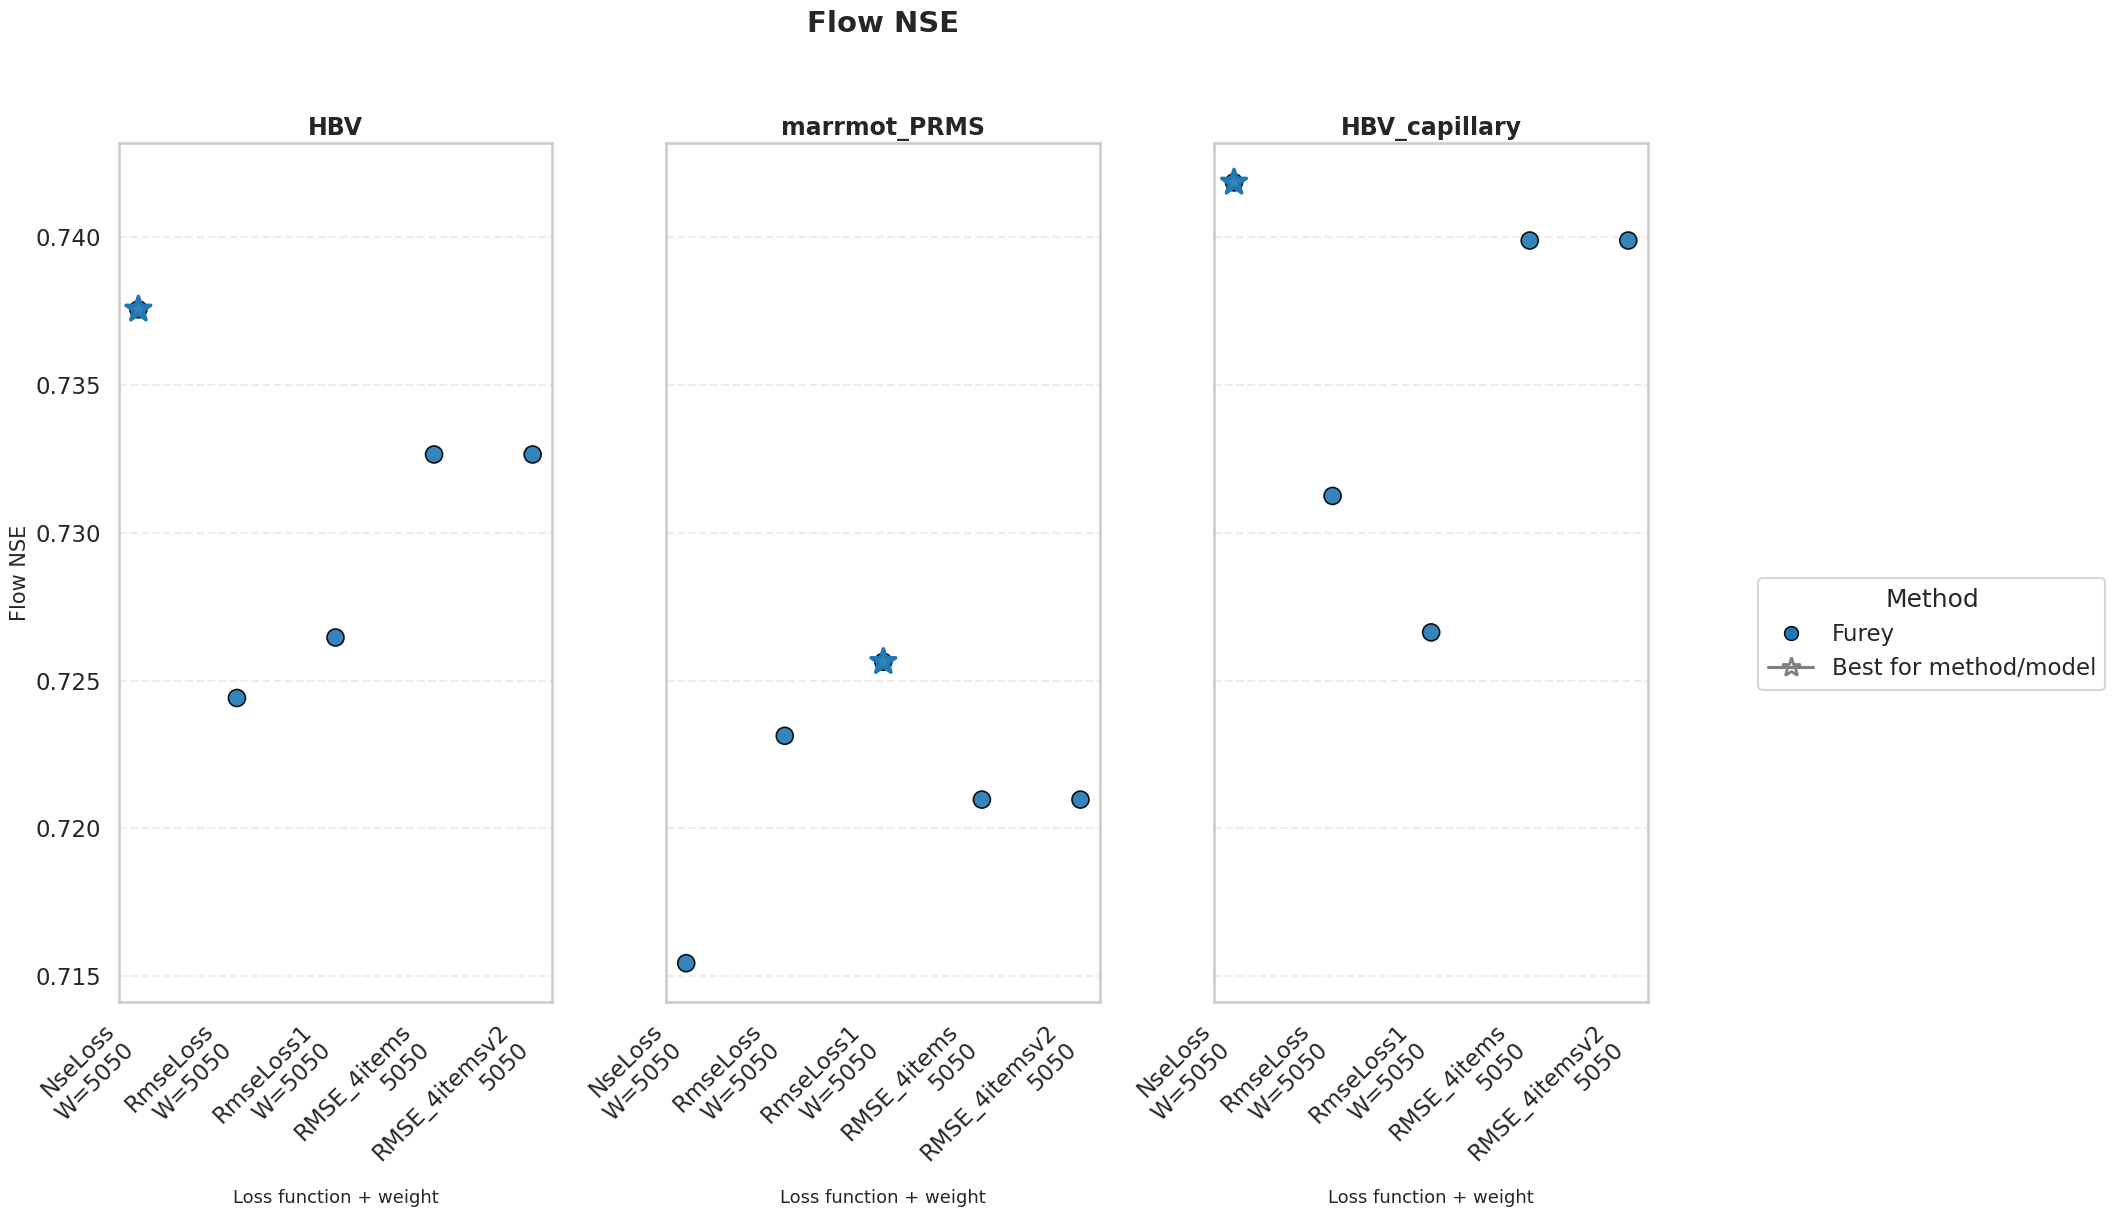

ValueError: 'RMSE_4items\nW=5050' is not in list

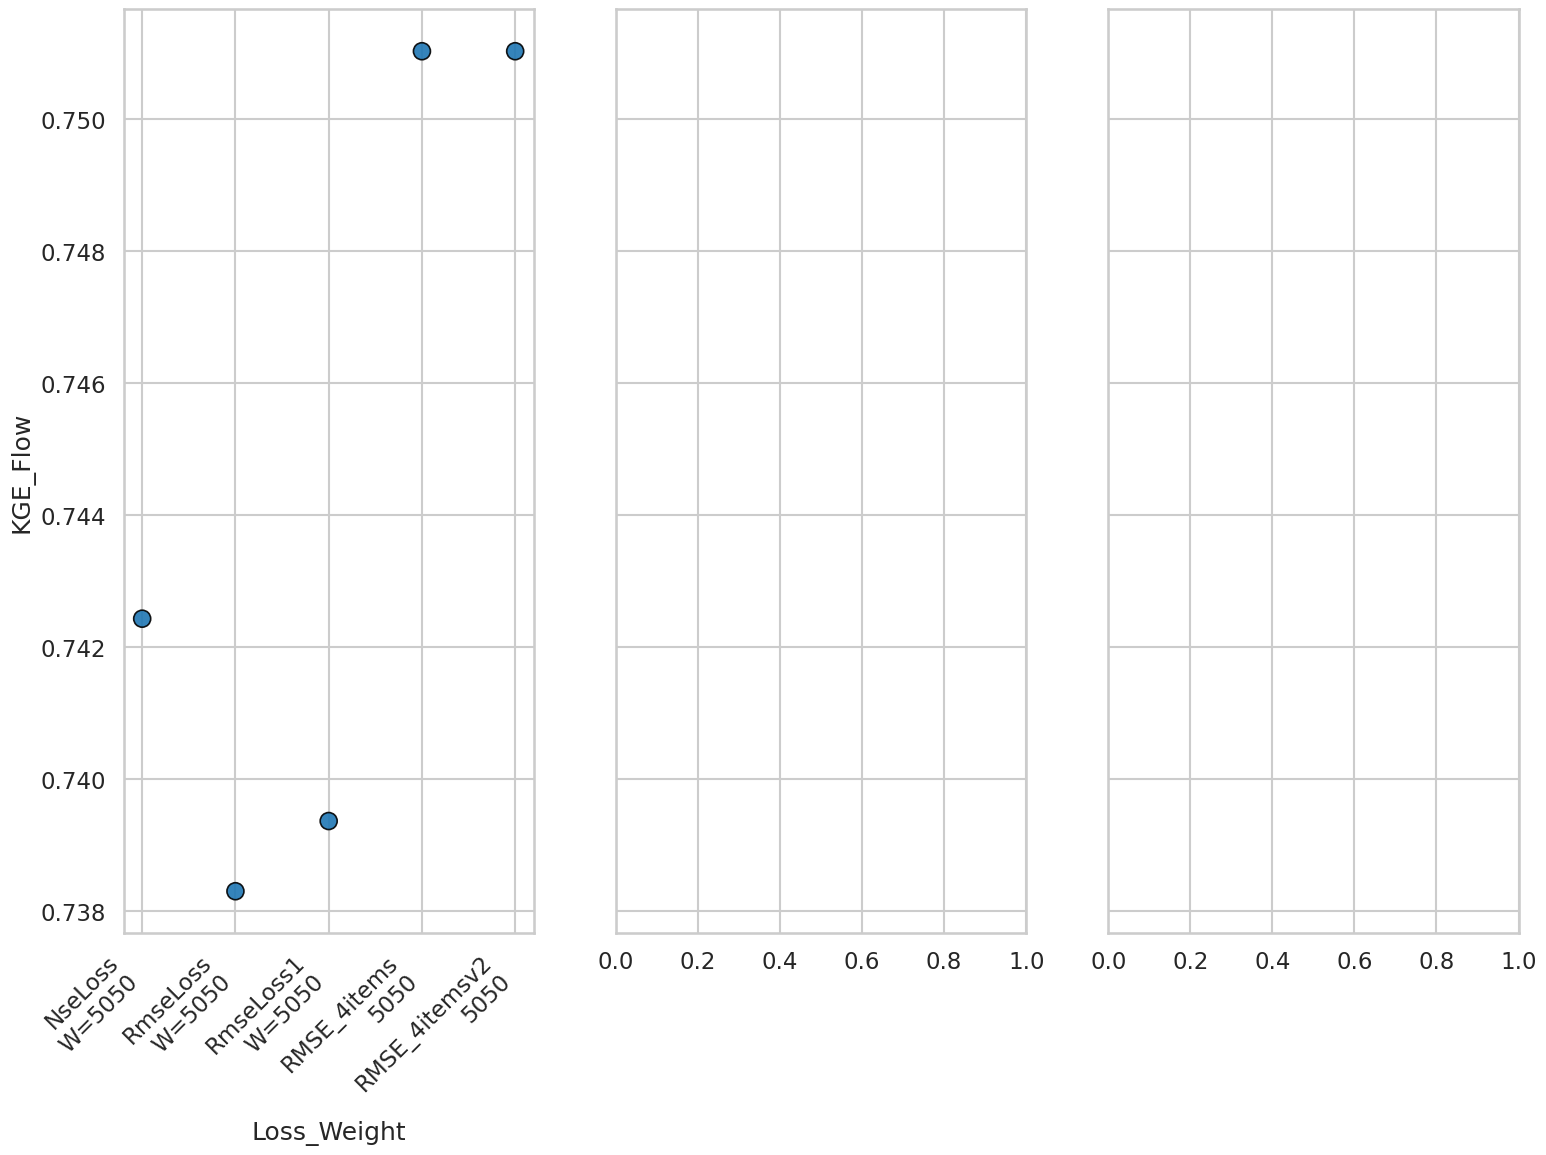

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------------------------------------
# Prepare data
# ---------------------------------------------------------

df = df.copy()

df['Loss_Weight'] = (
    df['Loss_Function']
    .str.replace('_flow_baseflow', '', regex=False)
    + '\nW='
    + df['Weights'].astype(str)
)

loss_order = [
    # 'NseLoss\nW=2575',
    'NseLoss\nW=5050',
    # 'NseLoss\nW=7525',
    # 'RmseLoss\nW=2575',
    'RmseLoss\nW=5050',
    # 'RmseLoss\nW=7525',
    # 'RmseLoss1\nW=2575',
    'RmseLoss1\nW=5050',
    # 'RmseLoss1\nW=7525',

    'RMSE_4items\n5050',
    'RMSE_4itemsv2\n5050'
]

methods_order = ['Furey'] #, 'Eckhardt']

models_order = [
    'HBV',
    'marrmot_PRMS',
    'HBV_capillary'
]

# ---------------------------------------------------------
# Plot settings
# ---------------------------------------------------------

metrics = [
    ('NSE_Flow', 'Flow NSE', 'higher'),
    ('KGE_Flow', 'Flow KGE', 'higher'),
    ('Abs_Bias_Flow', 'Flow Absolute Bias', 'lower'),
    ('NSE_Baseflow', 'Baseflow NSE', 'higher'),
    ('KGE_Baseflow', 'Baseflow KGE', 'higher'),
    ('Abs_Bias_Baseflow', 'Baseflow Absolute Bias', 'lower')
]

palette = {
    'Furey': '#1f77b4',
    # 'Eckhardt': '#d62728'
}

markers = {
    'Furey': 'o',
    # 'Eckhardt': 's'
}

sns.set_theme(
    style='whitegrid',
    context='talk'
)

# ---------------------------------------------------------
# Make six figures
# ---------------------------------------------------------

for metric, title, direction in metrics:

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(18, 12),
        sharey=True
    )

    for ax, model in zip(axes, models_order):

        data = df[df['Model'] == model].copy()

        # -------------------------------------------------
        # Scatter plot
        # -------------------------------------------------

        sns.scatterplot(
            data=data,
            x='Loss_Weight',
            y=metric,
            hue='Method',
            style='Method',
            hue_order=methods_order,
            style_order=methods_order,
            palette=palette,
            markers=markers,
            s=150,
            linewidth=1.2,
            edgecolor='black',
            alpha=0.9,
            ax=ax,
            legend=False
        )

        # Force desired x-axis order
        ax.set_xticks(
            range(len(loss_order))
        )

        ax.set_xticklabels(
            loss_order,
            rotation=45,
            ha='right'
        )

        # -------------------------------------------------
        # Ideal reference line
        # -------------------------------------------------

        # if direction == 'higher':

        #     # NSE/KGE ideal = 1
        #     ax.axhline(
        #         1,
        #         color='black',
        #         linestyle='--',
        #         linewidth=1.5,
        #         alpha=0.7,
        #         label='Ideal = 1'
        #     )

        # else:

        #     # Absolute bias ideal = 0
        #     ax.axhline(
        #         0,
        #         color='black',
        #         linestyle='--',
        #         linewidth=1.5,
        #         alpha=0.7,
        #         label='Ideal = 0'
        #     )

        # -------------------------------------------------
        # Highlight best point for each method
        # -------------------------------------------------

        for method in methods_order:

            method_data = data[
                data['Method'] == method
            ].copy()

            if len(method_data) == 0:
                continue

            if direction == 'higher':
                best_idx = method_data[metric].idxmax()
            else:
                best_idx = method_data[metric].idxmin()

            best = method_data.loc[best_idx]

            x = loss_order.index(
                best['Loss_Weight']
            )

            y = best[metric]

            # Star around best point
            ax.scatter(
                x,
                y,
                s=350,
                facecolors='none',
                edgecolors=palette[method],
                linewidths=2.5,
                marker='*',
                zorder=10
            )

        # -------------------------------------------------
        # Formatting
        # -------------------------------------------------

        ax.set_title(
            model,
            fontsize=17,
            fontweight='bold'
        )

        ax.set_xlabel(
            'Loss function + weight',
            fontsize=13
        )

        ax.grid(
            True,
            axis='y',
            linestyle='--',
            alpha=0.35
        )

        ax.grid(
            False,
            axis='x'
        )

    # -----------------------------------------------------
    # Y label
    # -----------------------------------------------------

    axes[0].set_ylabel(
        title,
        fontsize=15
    )

    axes[1].set_ylabel('')
    axes[2].set_ylabel('')

    # -----------------------------------------------------
    # Overall title
    # -----------------------------------------------------

    fig.suptitle(
        title,
        fontsize=21,
        fontweight='bold',
        y=1.02
    )

    # -----------------------------------------------------
    # Custom legend
    # -----------------------------------------------------

    from matplotlib.lines import Line2D

    legend_elements = [
        Line2D(
            [0],
            [0],
            marker='o',
            color='w',
            label='Furey',
            markerfacecolor=palette['Furey'],
            markeredgecolor='black',
            markersize=10
        ),
        # Line2D(
        #     [0],
        #     [0],
        #     marker='s',
        #     color='w',
        #     label='Eckhardt',
        #     markerfacecolor=palette['Eckhardt'],
        #     markeredgecolor='black',
        #     markersize=10
        # ),
        Line2D(
            [0],
            [0],
            marker='*',
            color='gray',
            label='Best for method/model',
            markerfacecolor='none',
            markeredgecolor='gray',
            markersize=14,
            markeredgewidth=2
        )
    ]

    fig.legend(
        handles=legend_elements,
        title='Method',
        loc='center left',
        bbox_to_anchor=(0.98, 0.5),
        frameon=True
    )

    plt.tight_layout(
        rect=[0, 0, 0.94, 1]
    )

    plt.show()

In [30]:
df.groupby('Loss_Function').get_group('NseLoss_flow_baseflow')

,Method,Model,Loss_Function,Weights,NSE_Flow,KGE_Flow,Abs_Bias_Flow,NSE_Baseflow,KGE_Baselow,Abs_Bias_Baseflow
0,Furey,HBV,NseLoss_flow_baseflow,2575,0.732580,0.733693,0.103811,0.786235,0.783329,0.122800
1,Furey,HBV,NseLoss_flow_baseflow,5050,0.737563,0.742434,0.100536,0.772945,0.774623,0.123159
2,Furey,HBV,NseLoss_flow_baseflow,7525,0.733894,0.747498,0.117690,0.756068,0.749883,0.128467
9,Furey,marrmot_PRMS,NseLoss_flow_baseflow,2575,0.712255,0.716398,0.109901,0.786721,0.789505,0.124443
10,Furey,marrmot_PRMS,NseLoss_flow_baseflow,5050,0.715437,0.734080,0.102742,0.777969,0.788941,0.113716
11,Furey,marrmot_PRMS,NseLoss_flow_baseflow,7525,0.721507,0.742324,0.108973,0.739613,0.752090,0.116884
18,Furey,HBV_capillary,NseLoss_flow_baseflow,2575,0.739462,0.750945,0.100237,0.794814,0.796678,0.105100
19,Furey,HBV_capillary,NseLoss_flow_baseflow,5050,0.741858,0.755393,0.102572,0.788255,0.795655,0.111707
20,Furey,HBV_capillary,NseLoss_flow_baseflow,7525,0.746004,0.746766,0.116422,0.755472,0.756934,0.124805
27,Eckhardt,HBV,NseLoss_flow_baseflow,2575,0.732207,0.730028,0.108551,0.785345,0.782148,0.120621




DATA CHECK

Dataframe columns:
['Method', 'Model', 'Loss_Function', 'Weights', 'NSE_Flow', 'KGE_Flow', 'Abs_Bias_Flow', 'NSE_Baseflow', 'KGE_Baseflow', 'Abs_Bias_Baseflow', 'Loss_Weight', 'Loss_Short', 'Method_Model']

Methods:
['Furey']

Models:
['HBV' 'marrmot_PRMS' 'HBV_capillary']

Loss functions:
['NseLoss' 'RmseLoss' 'RmseLoss1' 'RMSE_4items' 'RMSE_4itemsv2']

Weights:
['5050']

Number of rows:
15


PART 1: EFFECT OF WEIGHT
Plotting: Furey | HBV | NseLoss


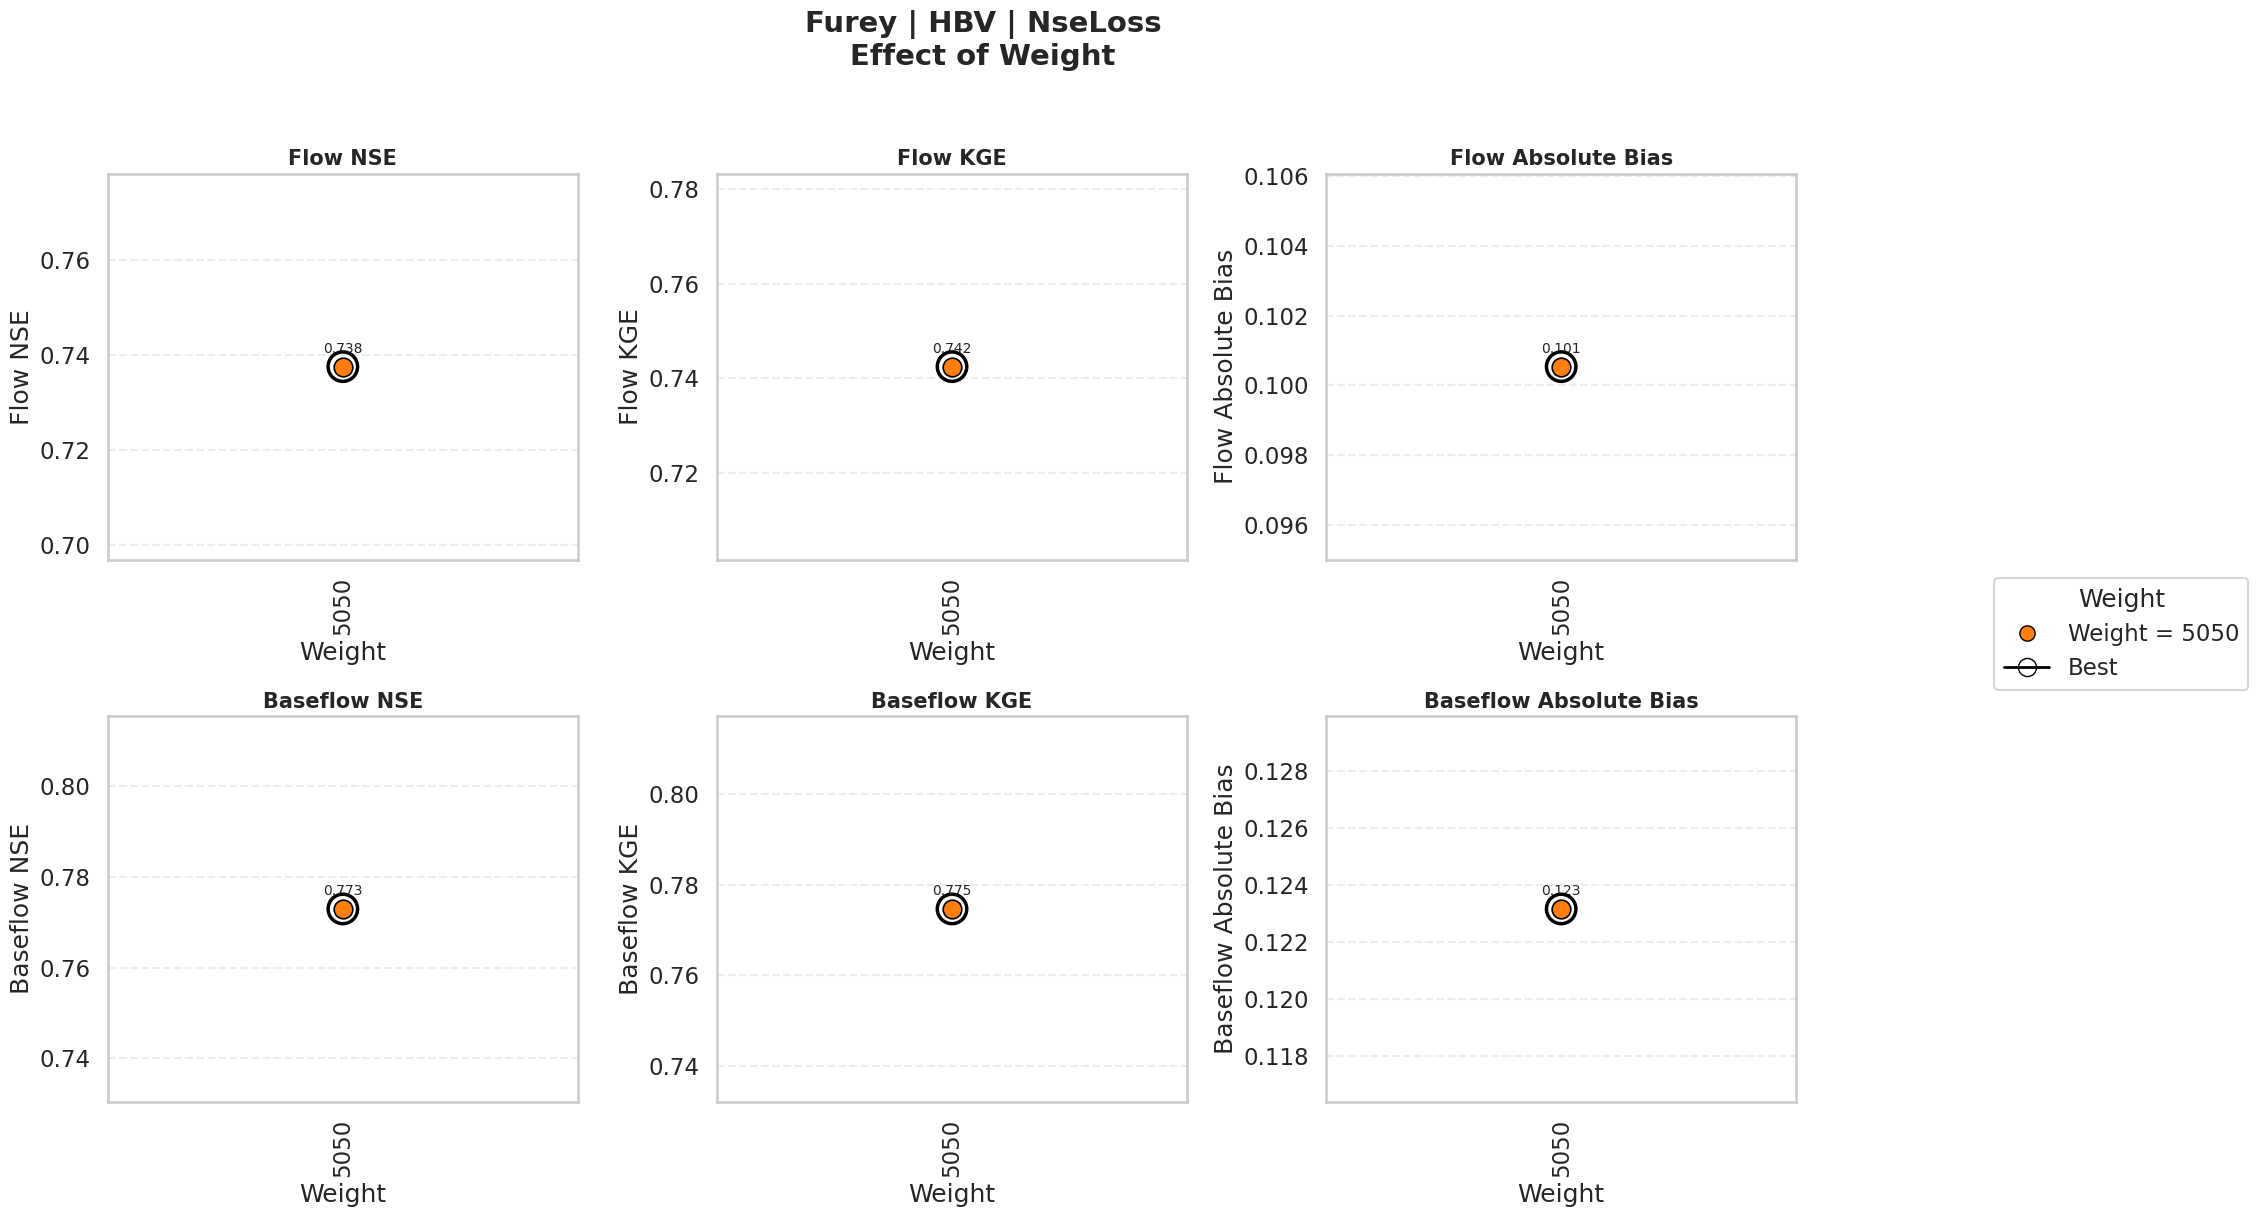

Plotting: Furey | HBV | RmseLoss


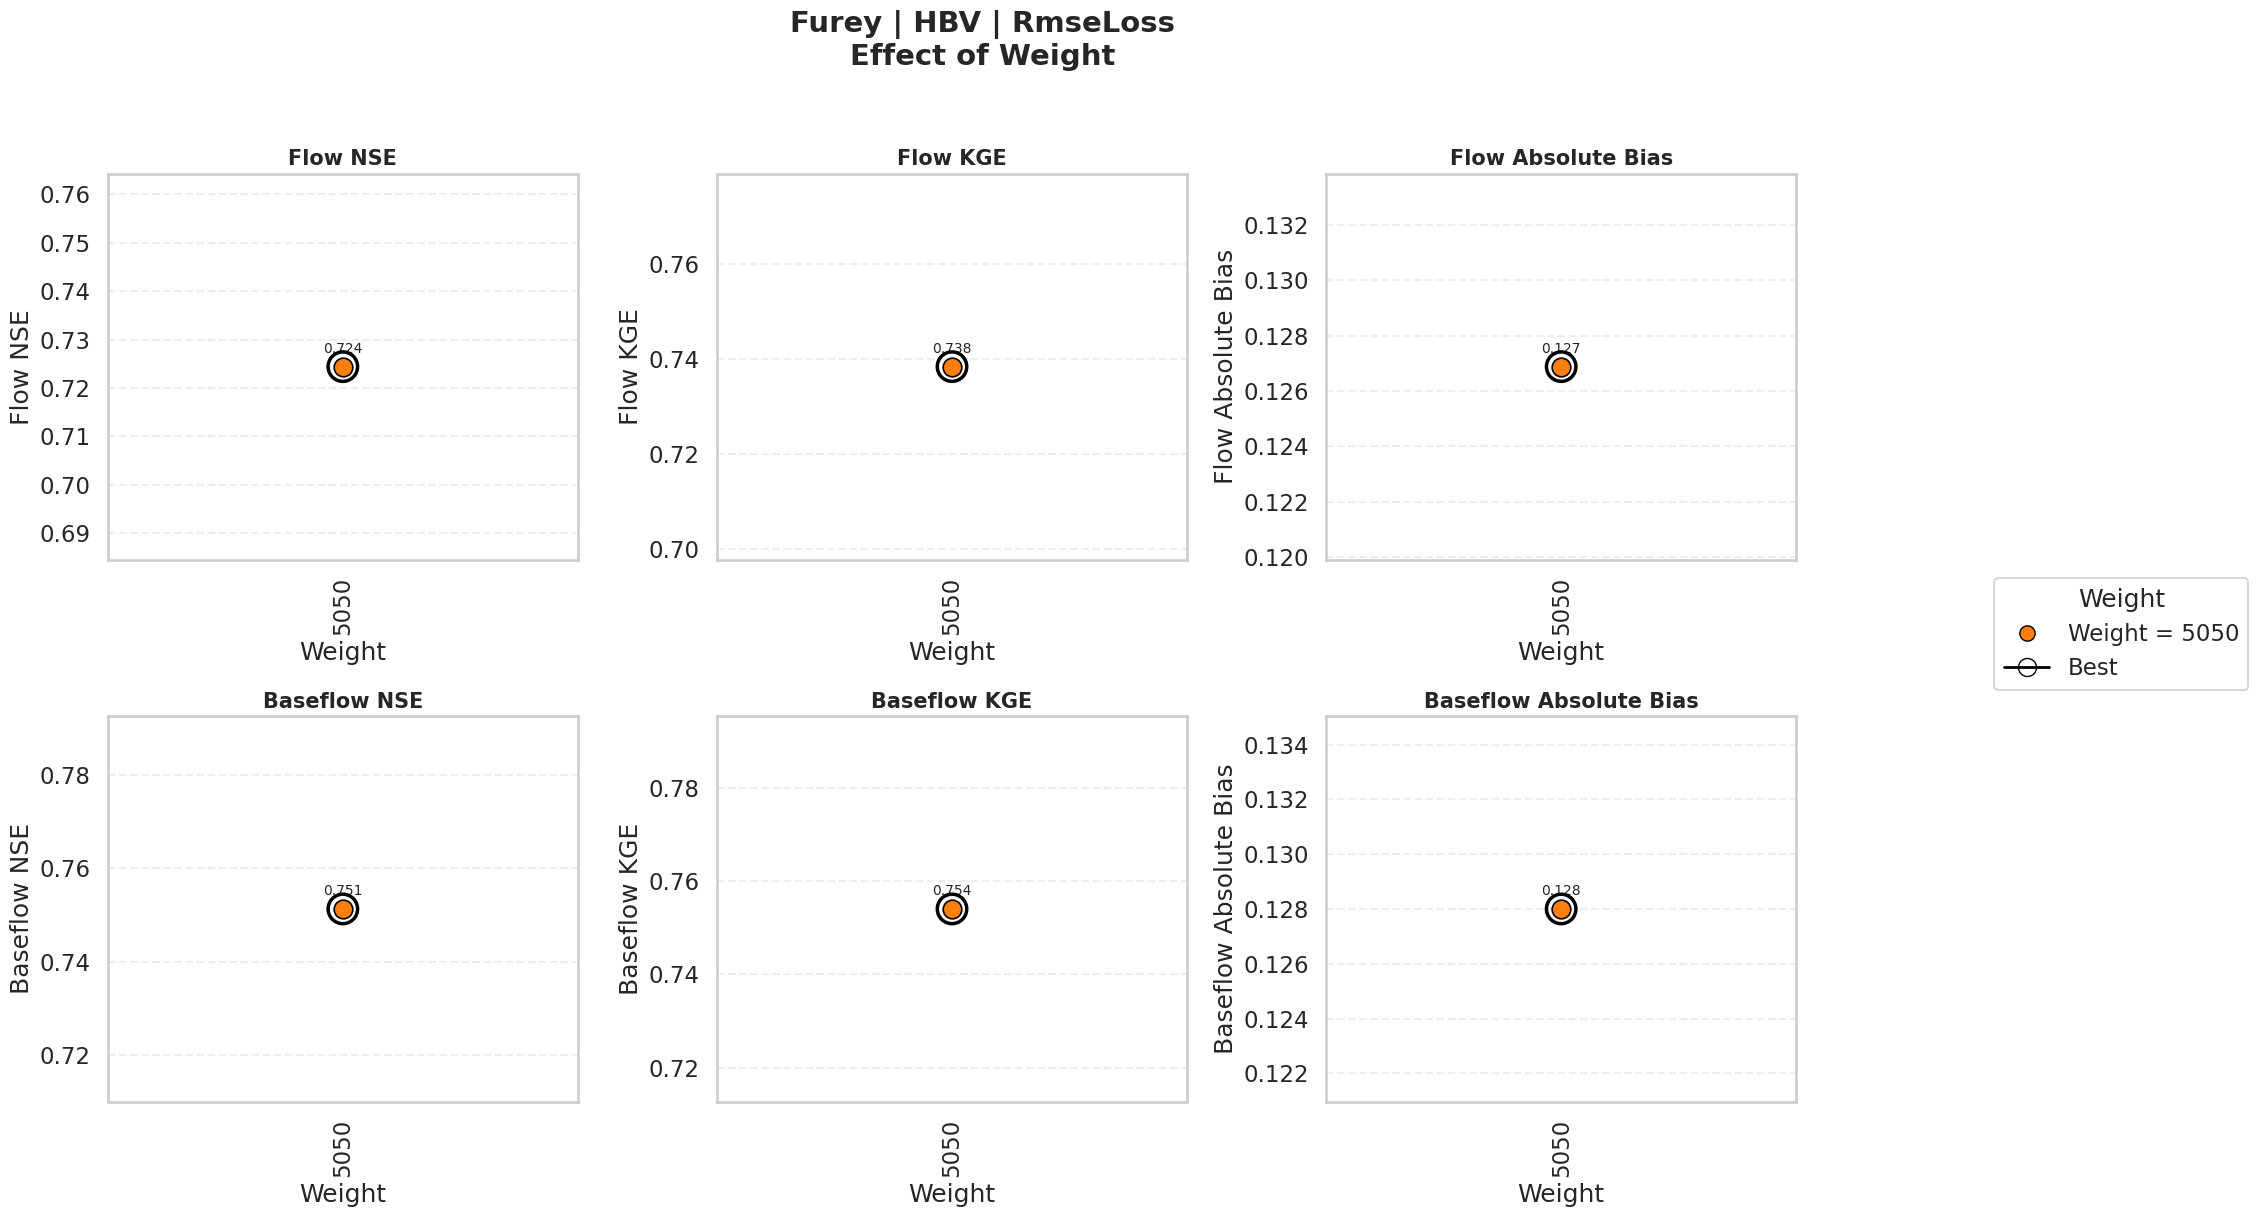

Plotting: Furey | HBV | RmseLoss1


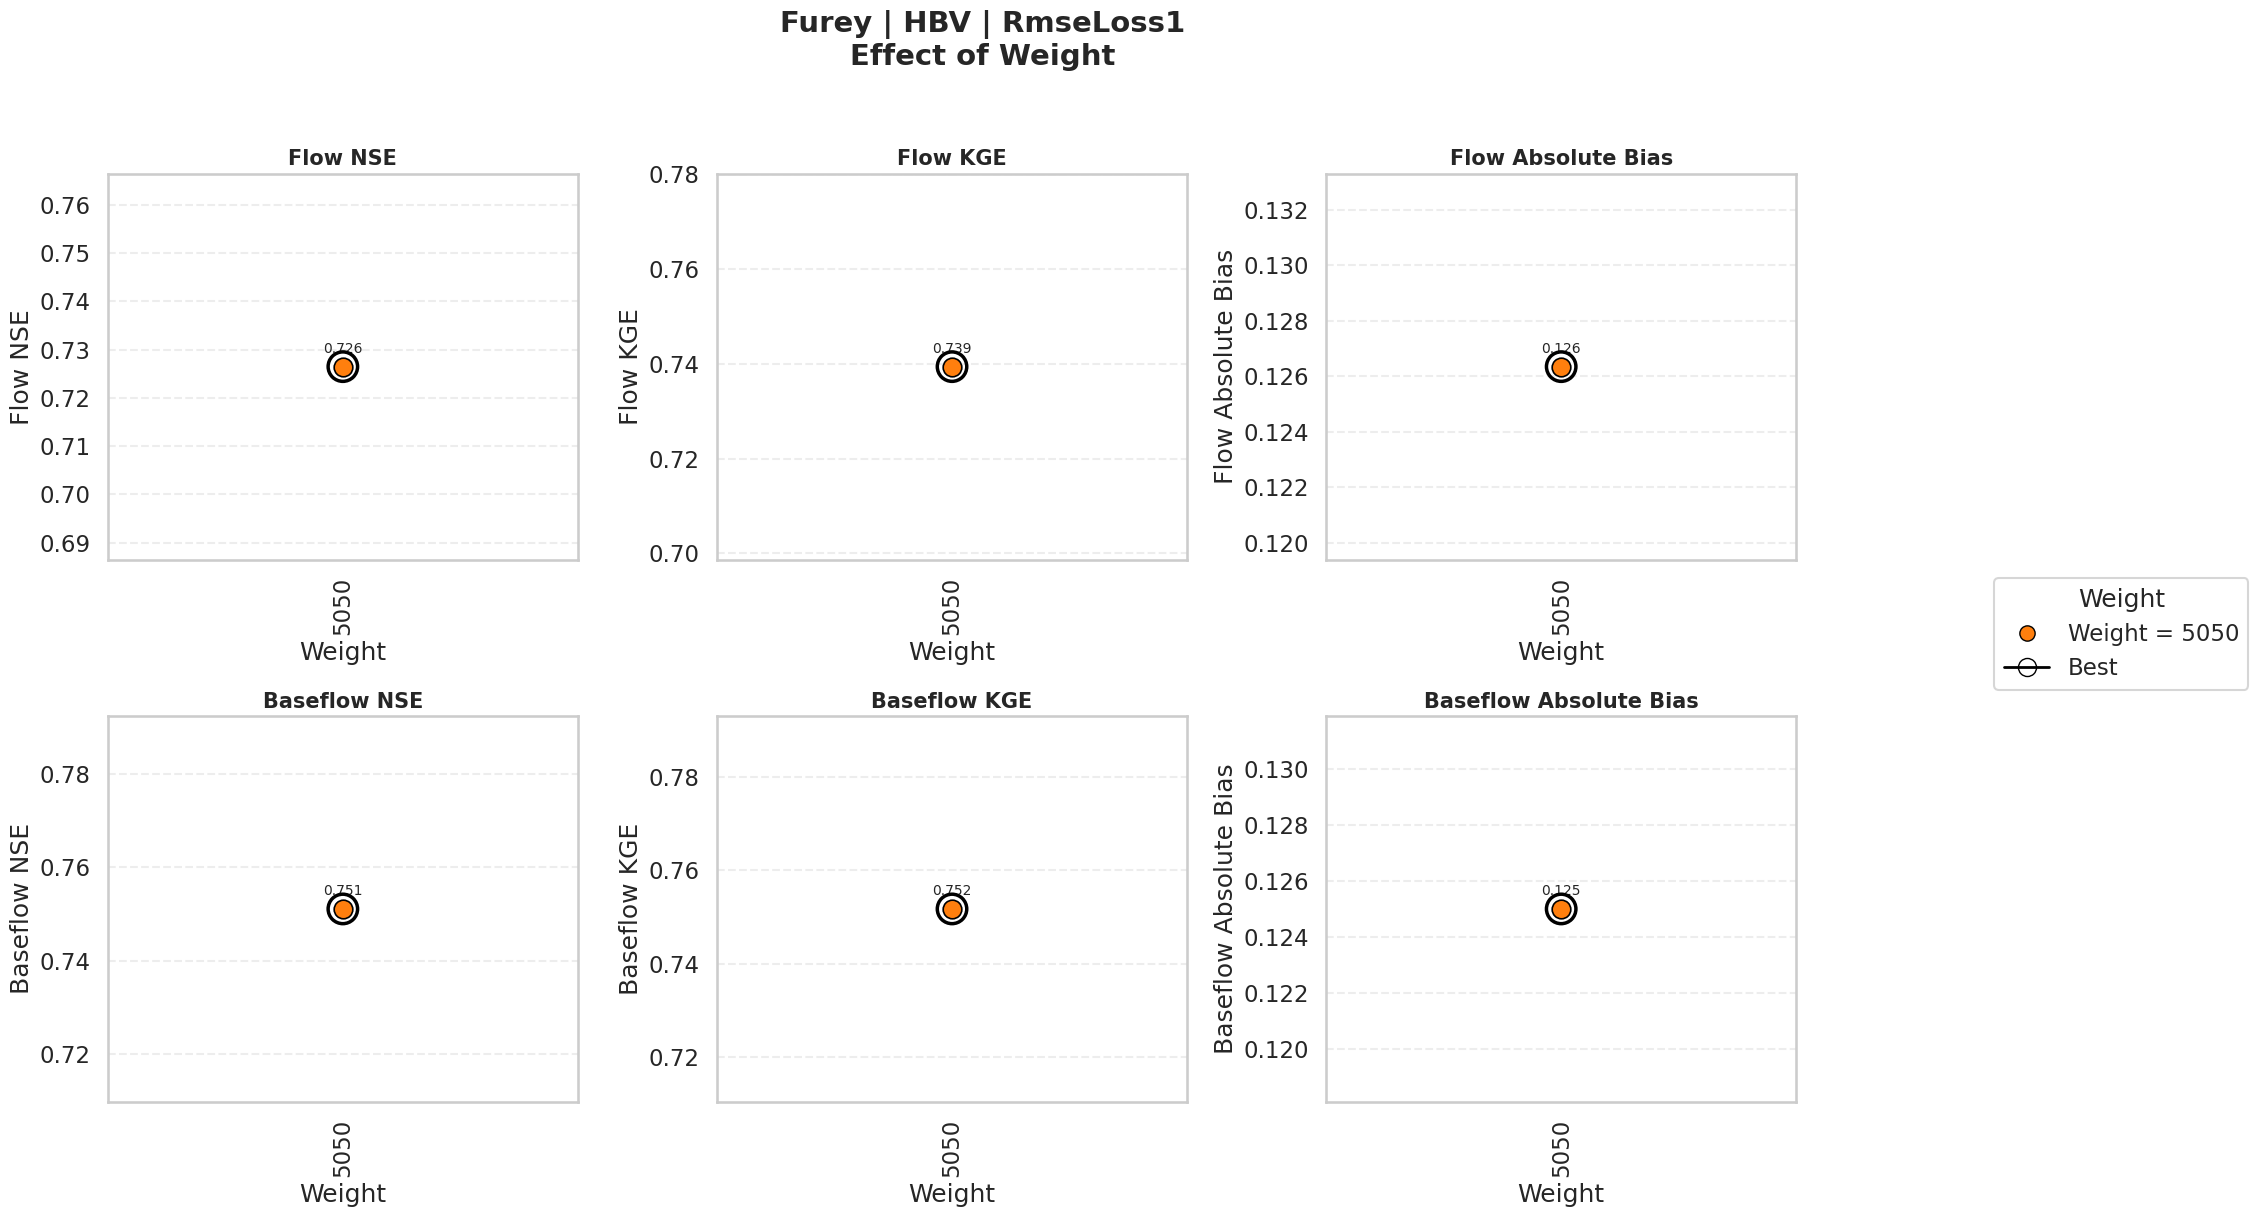

Plotting: Furey | HBV | RMSE_4items


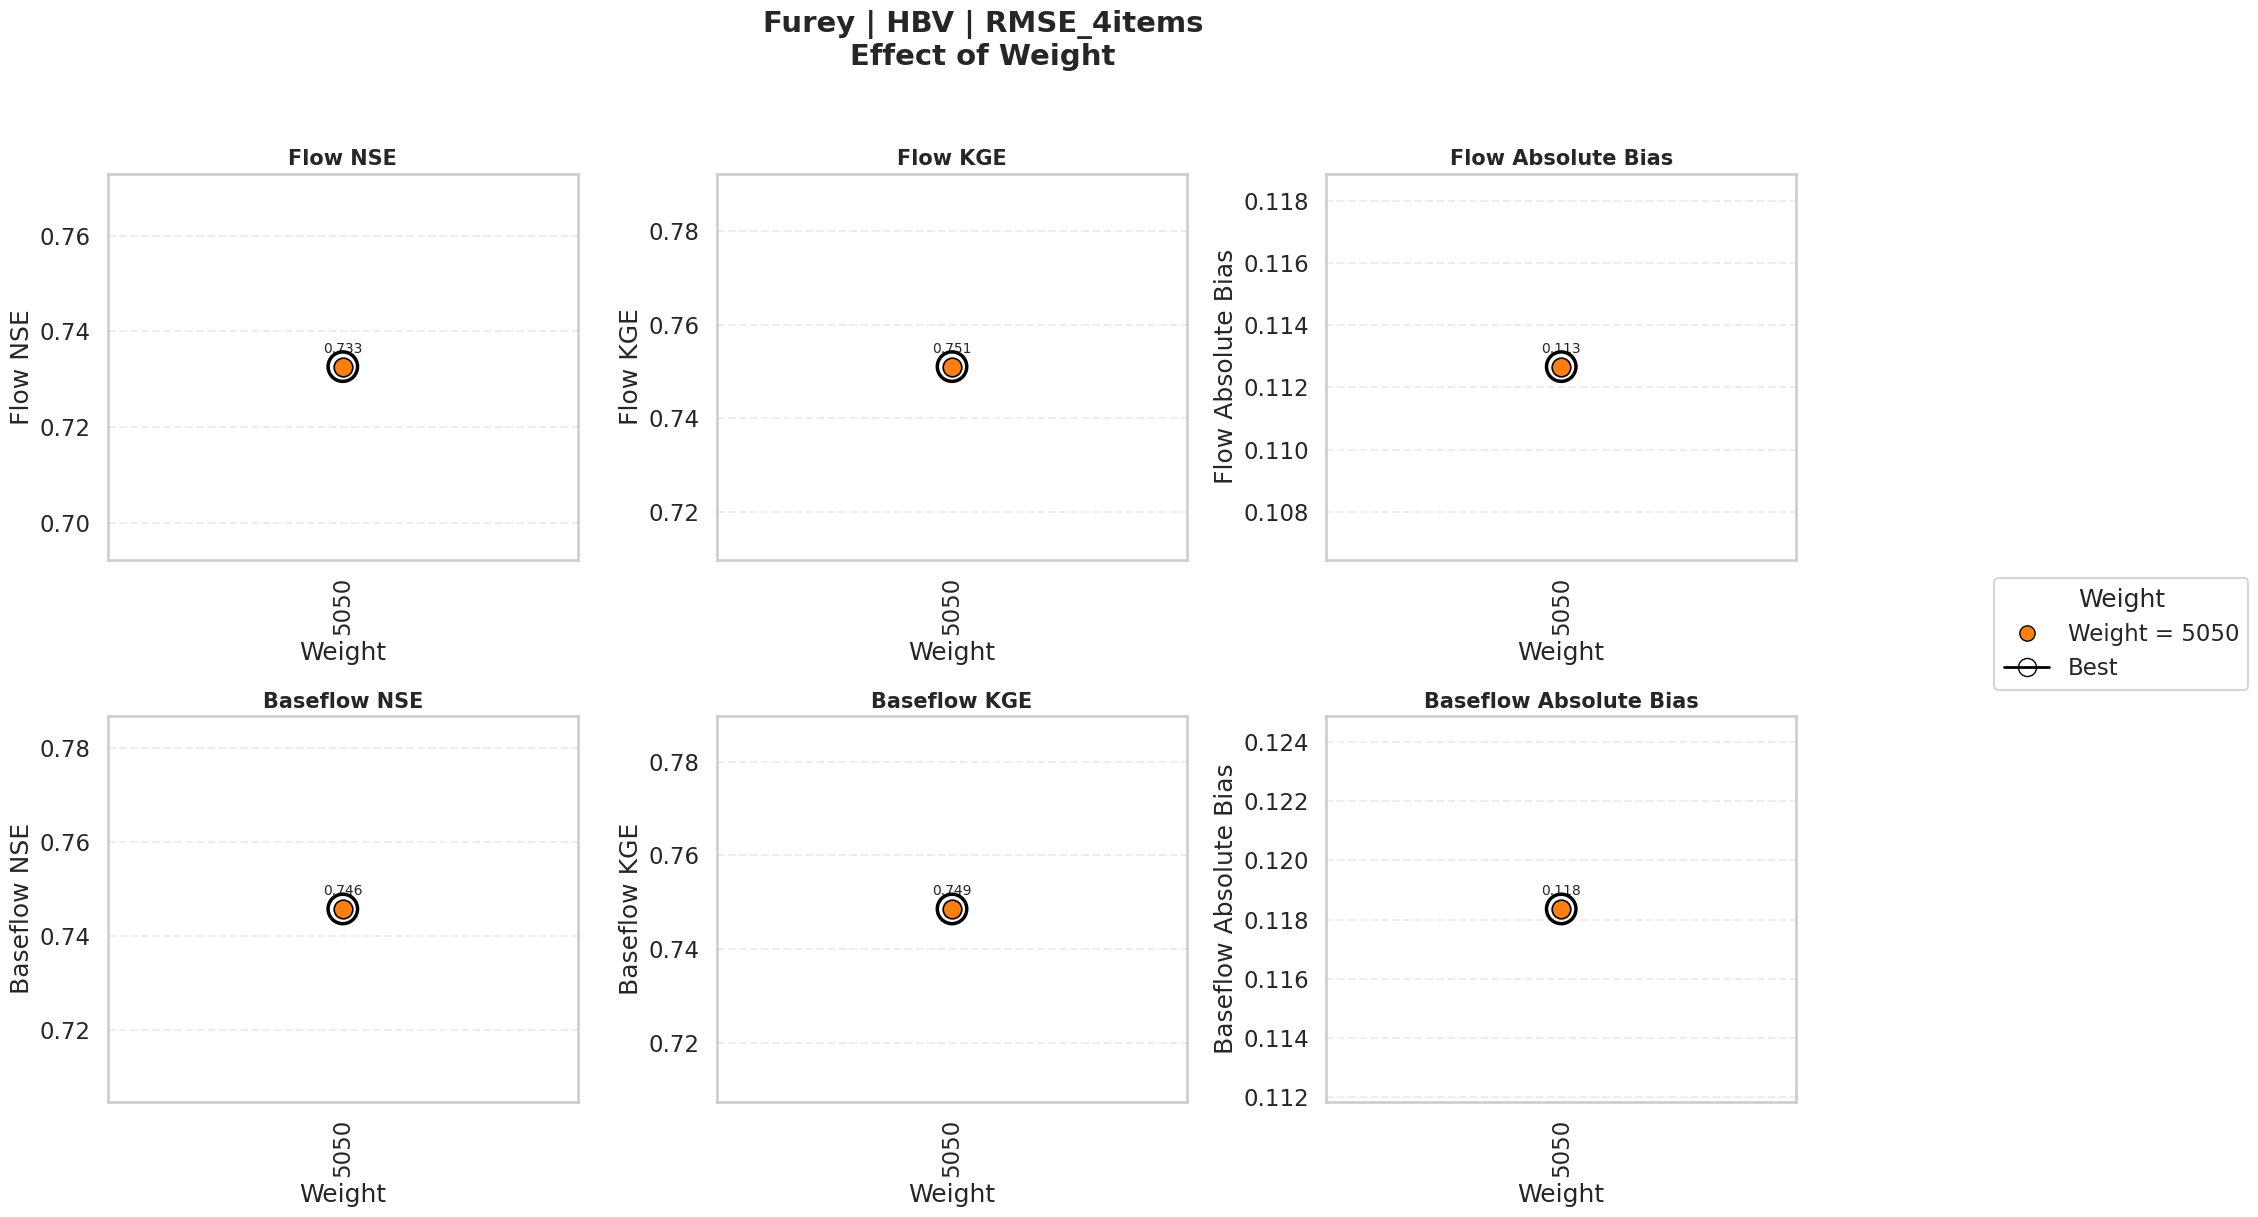

Plotting: Furey | HBV | RMSE_4itemsv2


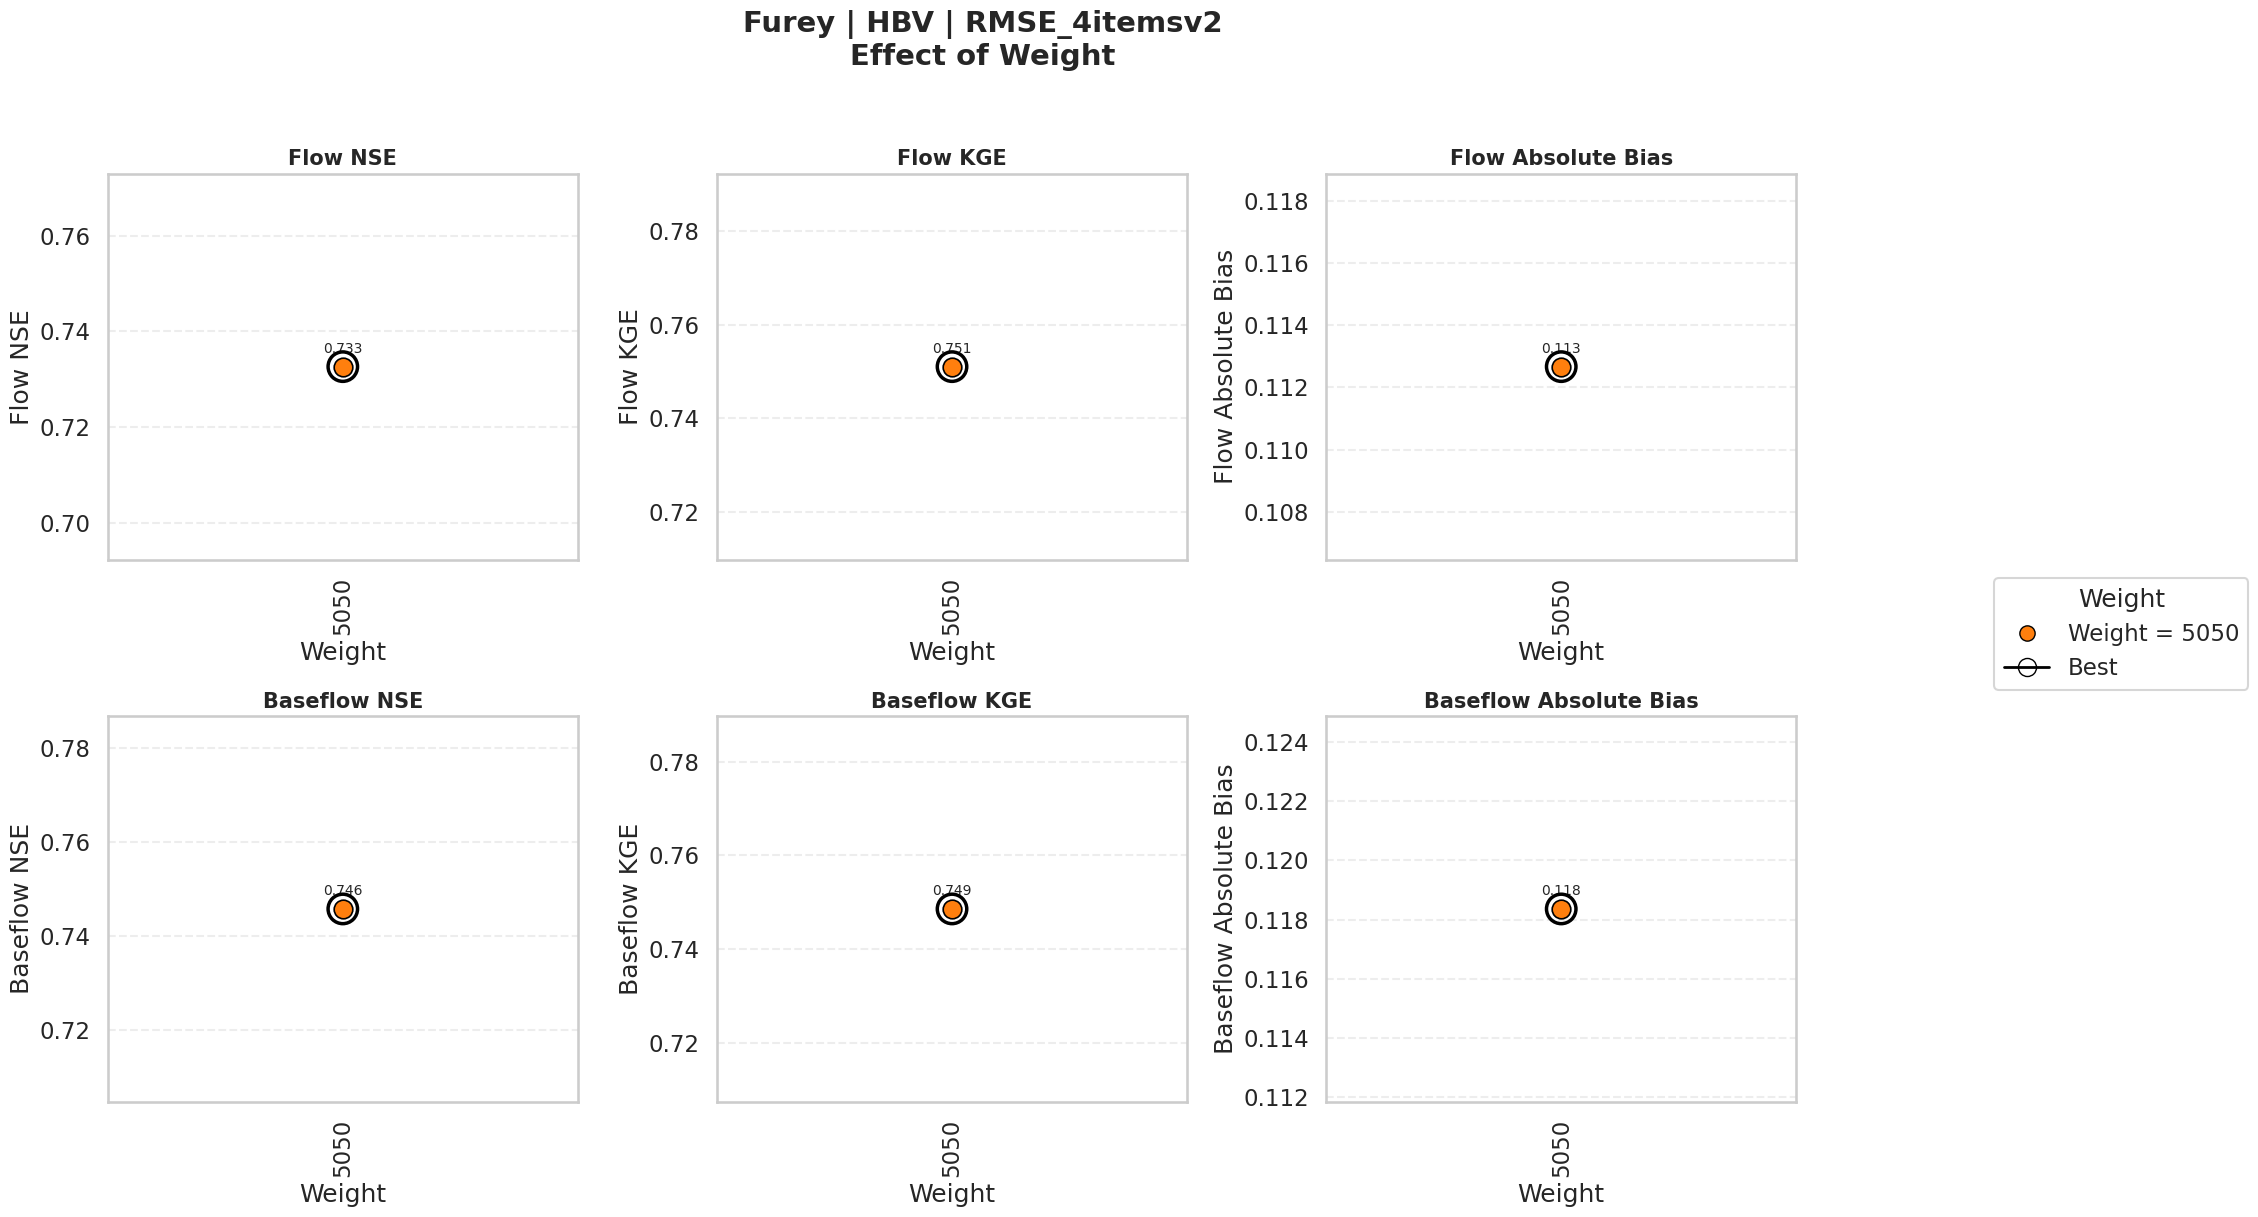

Plotting: Furey | marrmot_PRMS | NseLoss


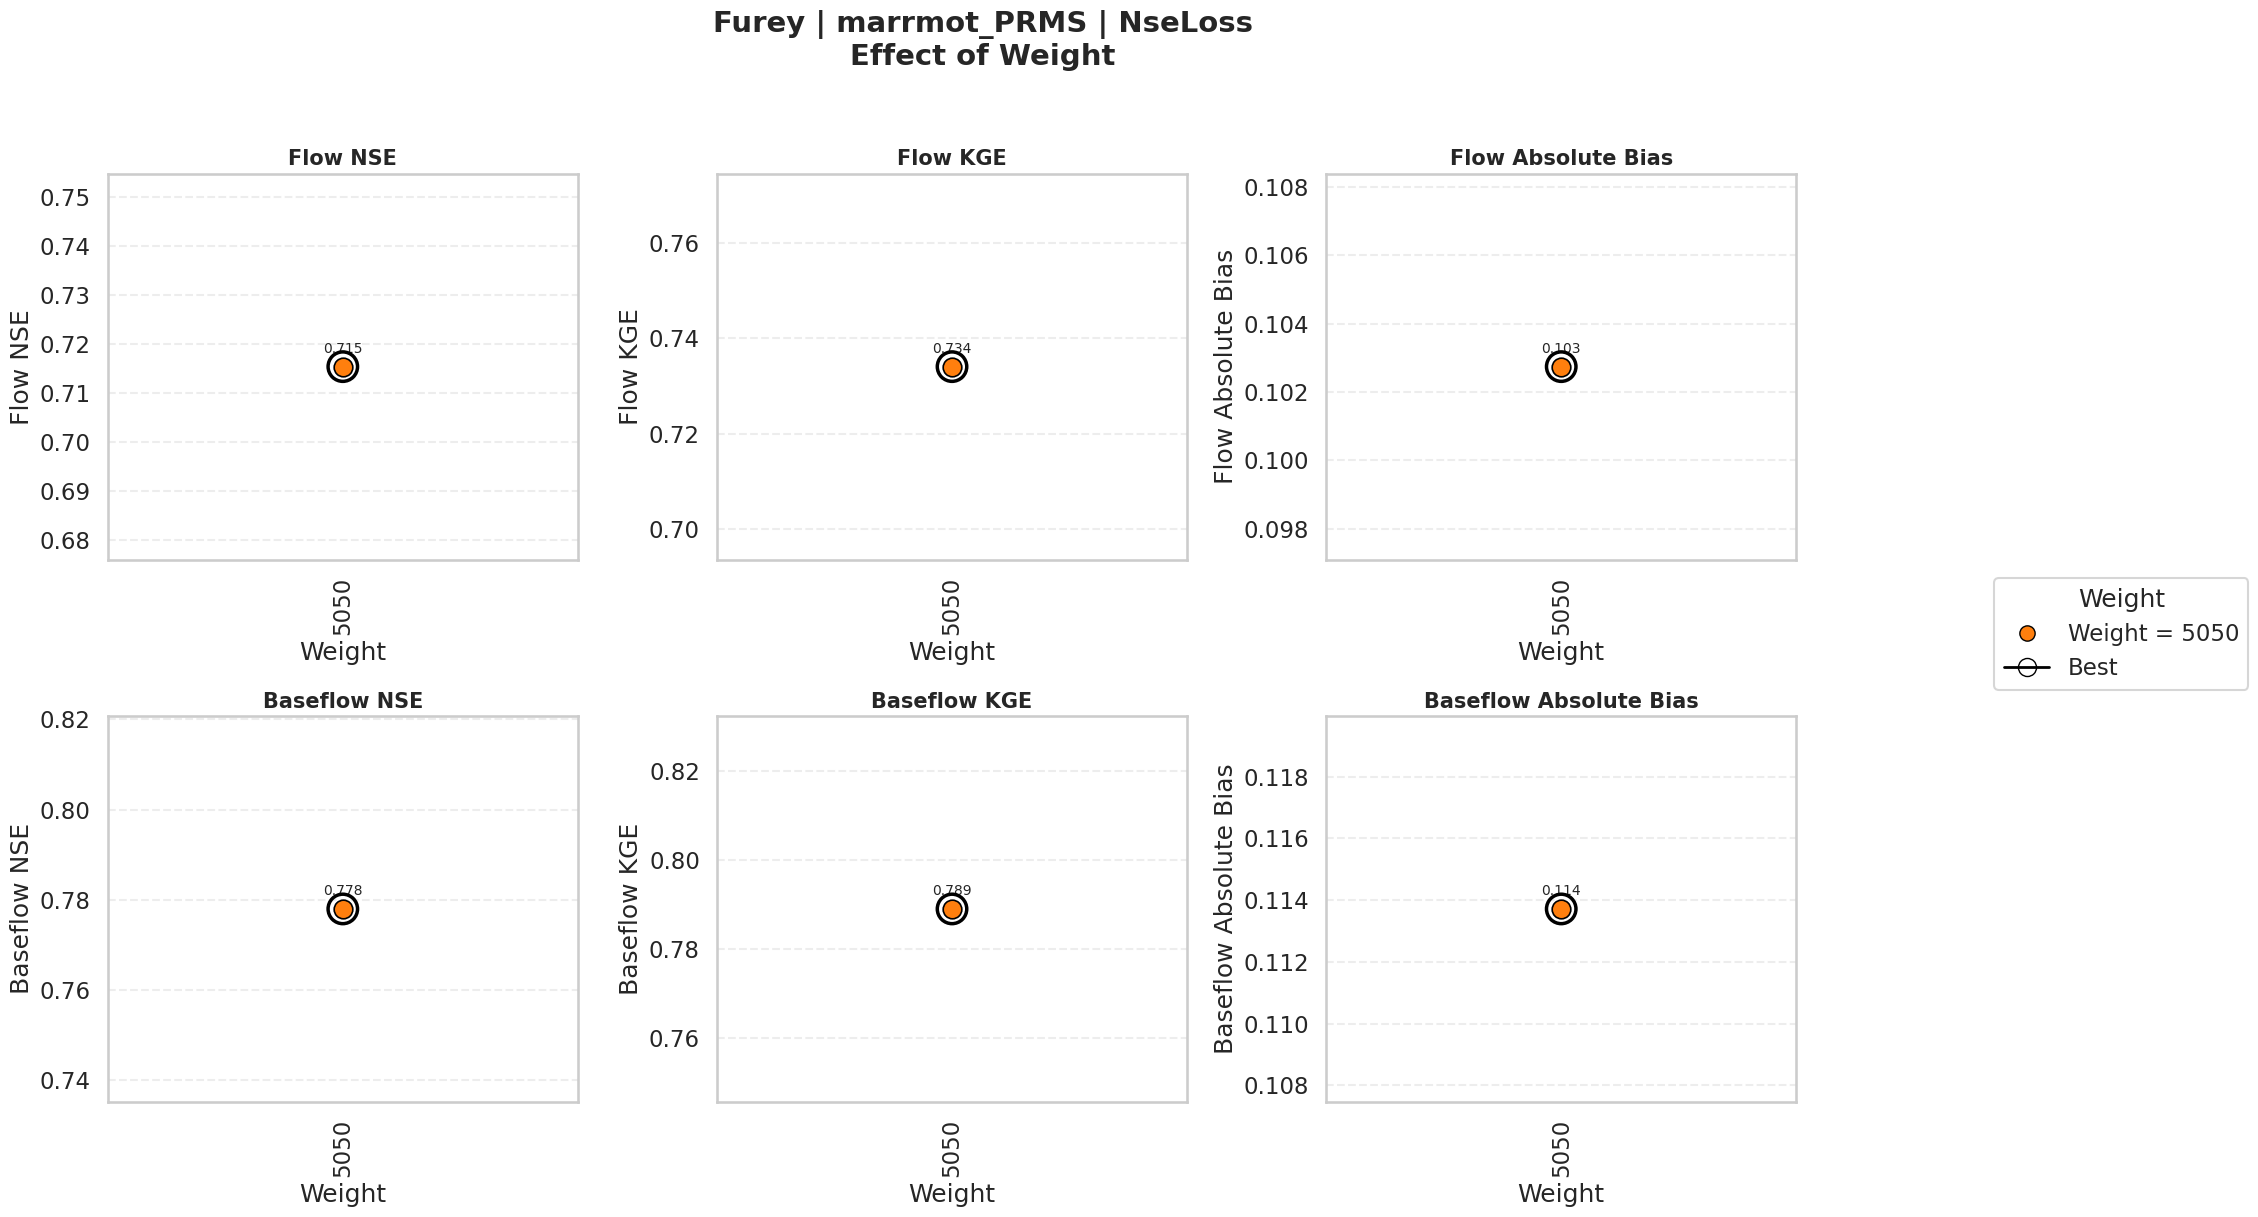

Plotting: Furey | marrmot_PRMS | RmseLoss


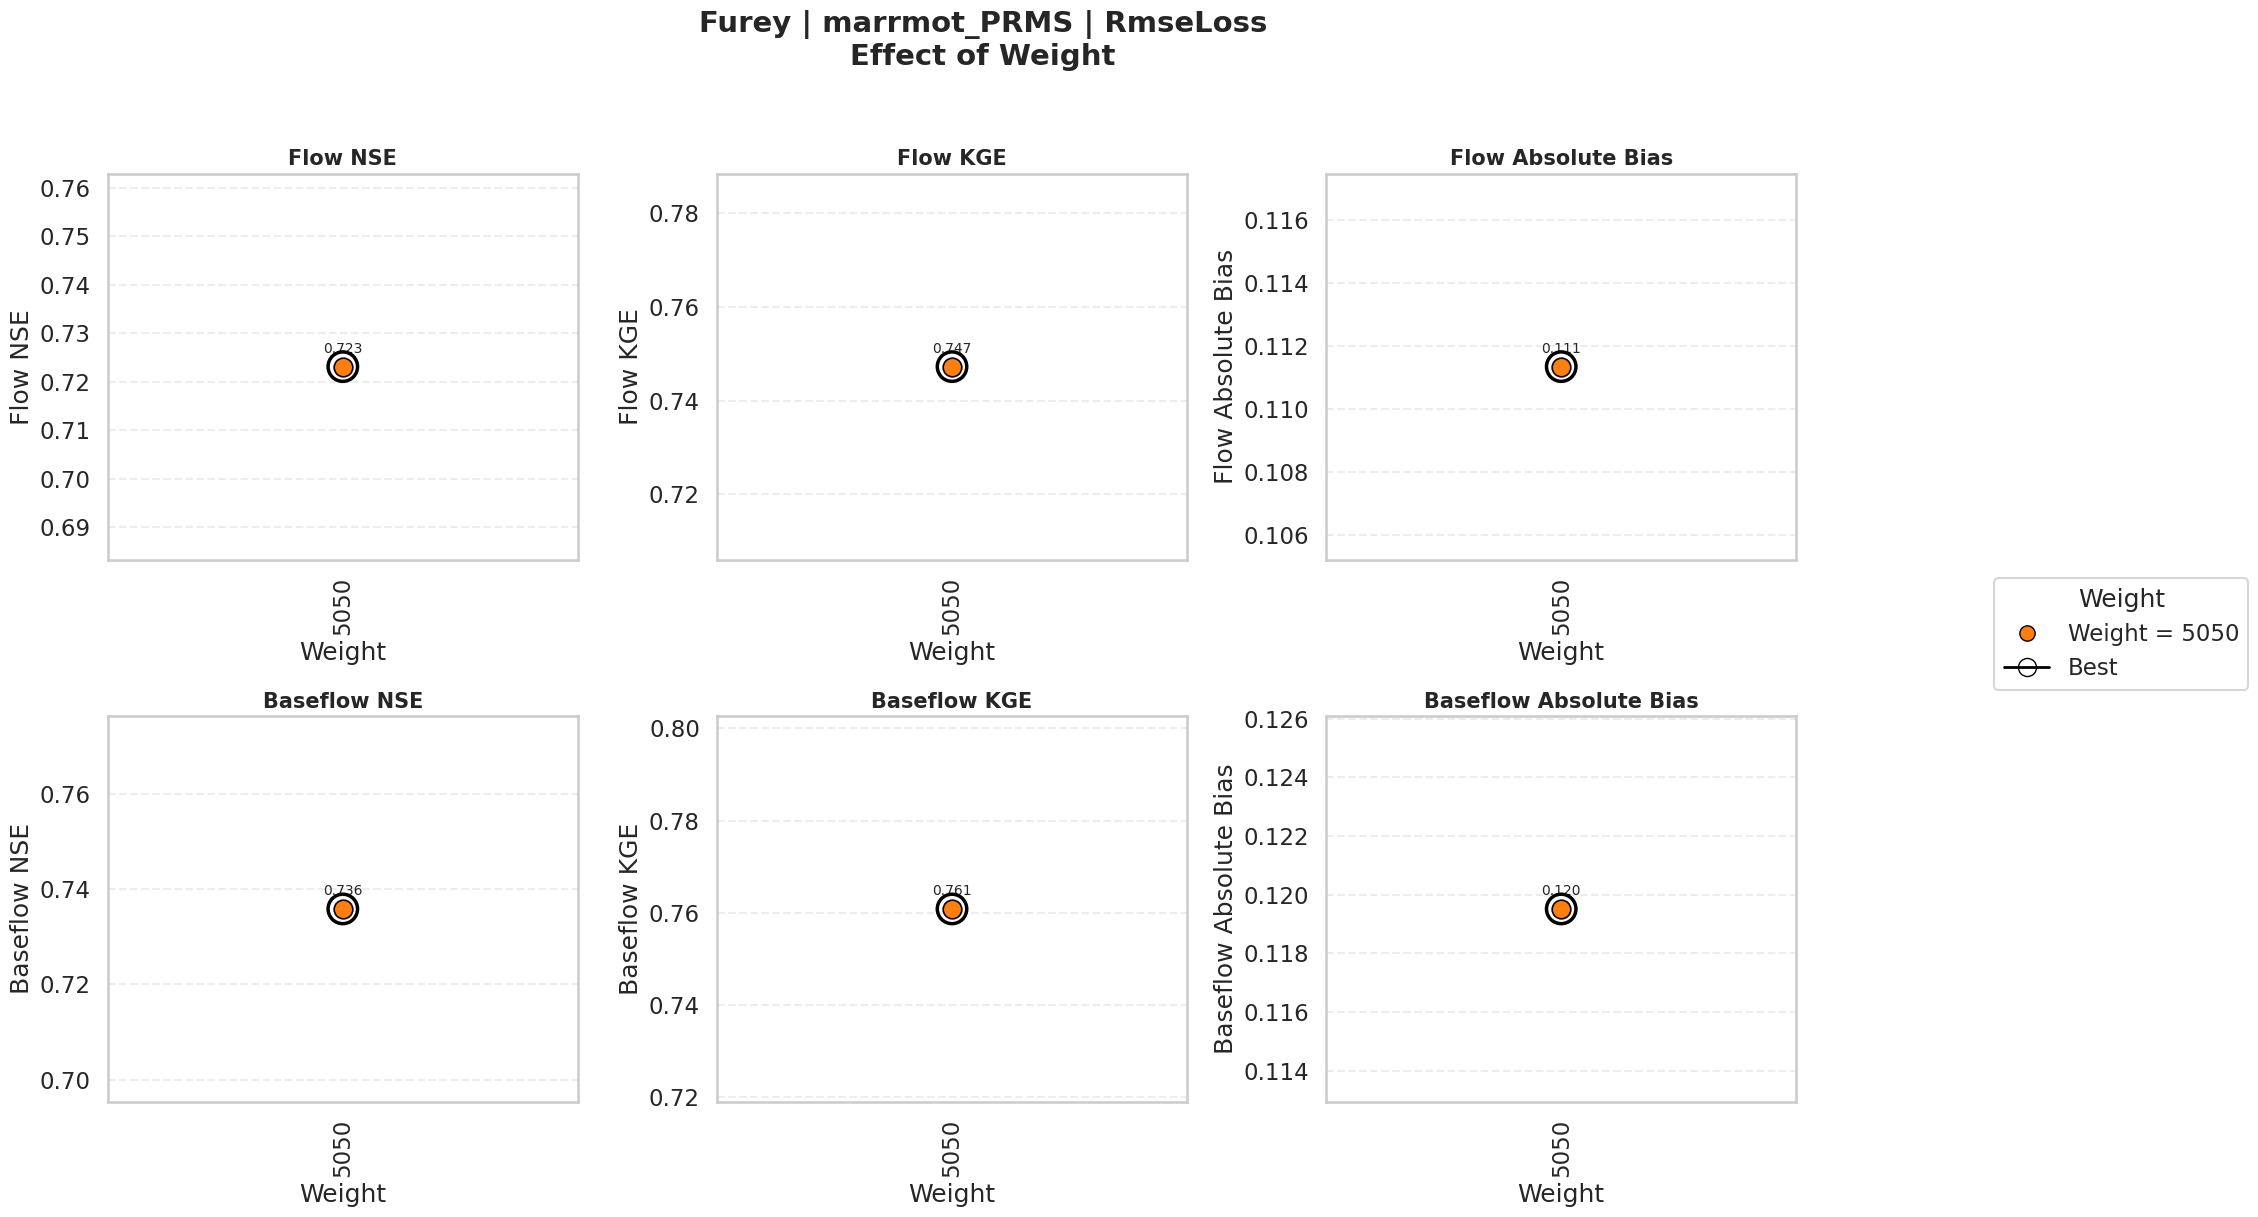

Plotting: Furey | marrmot_PRMS | RmseLoss1


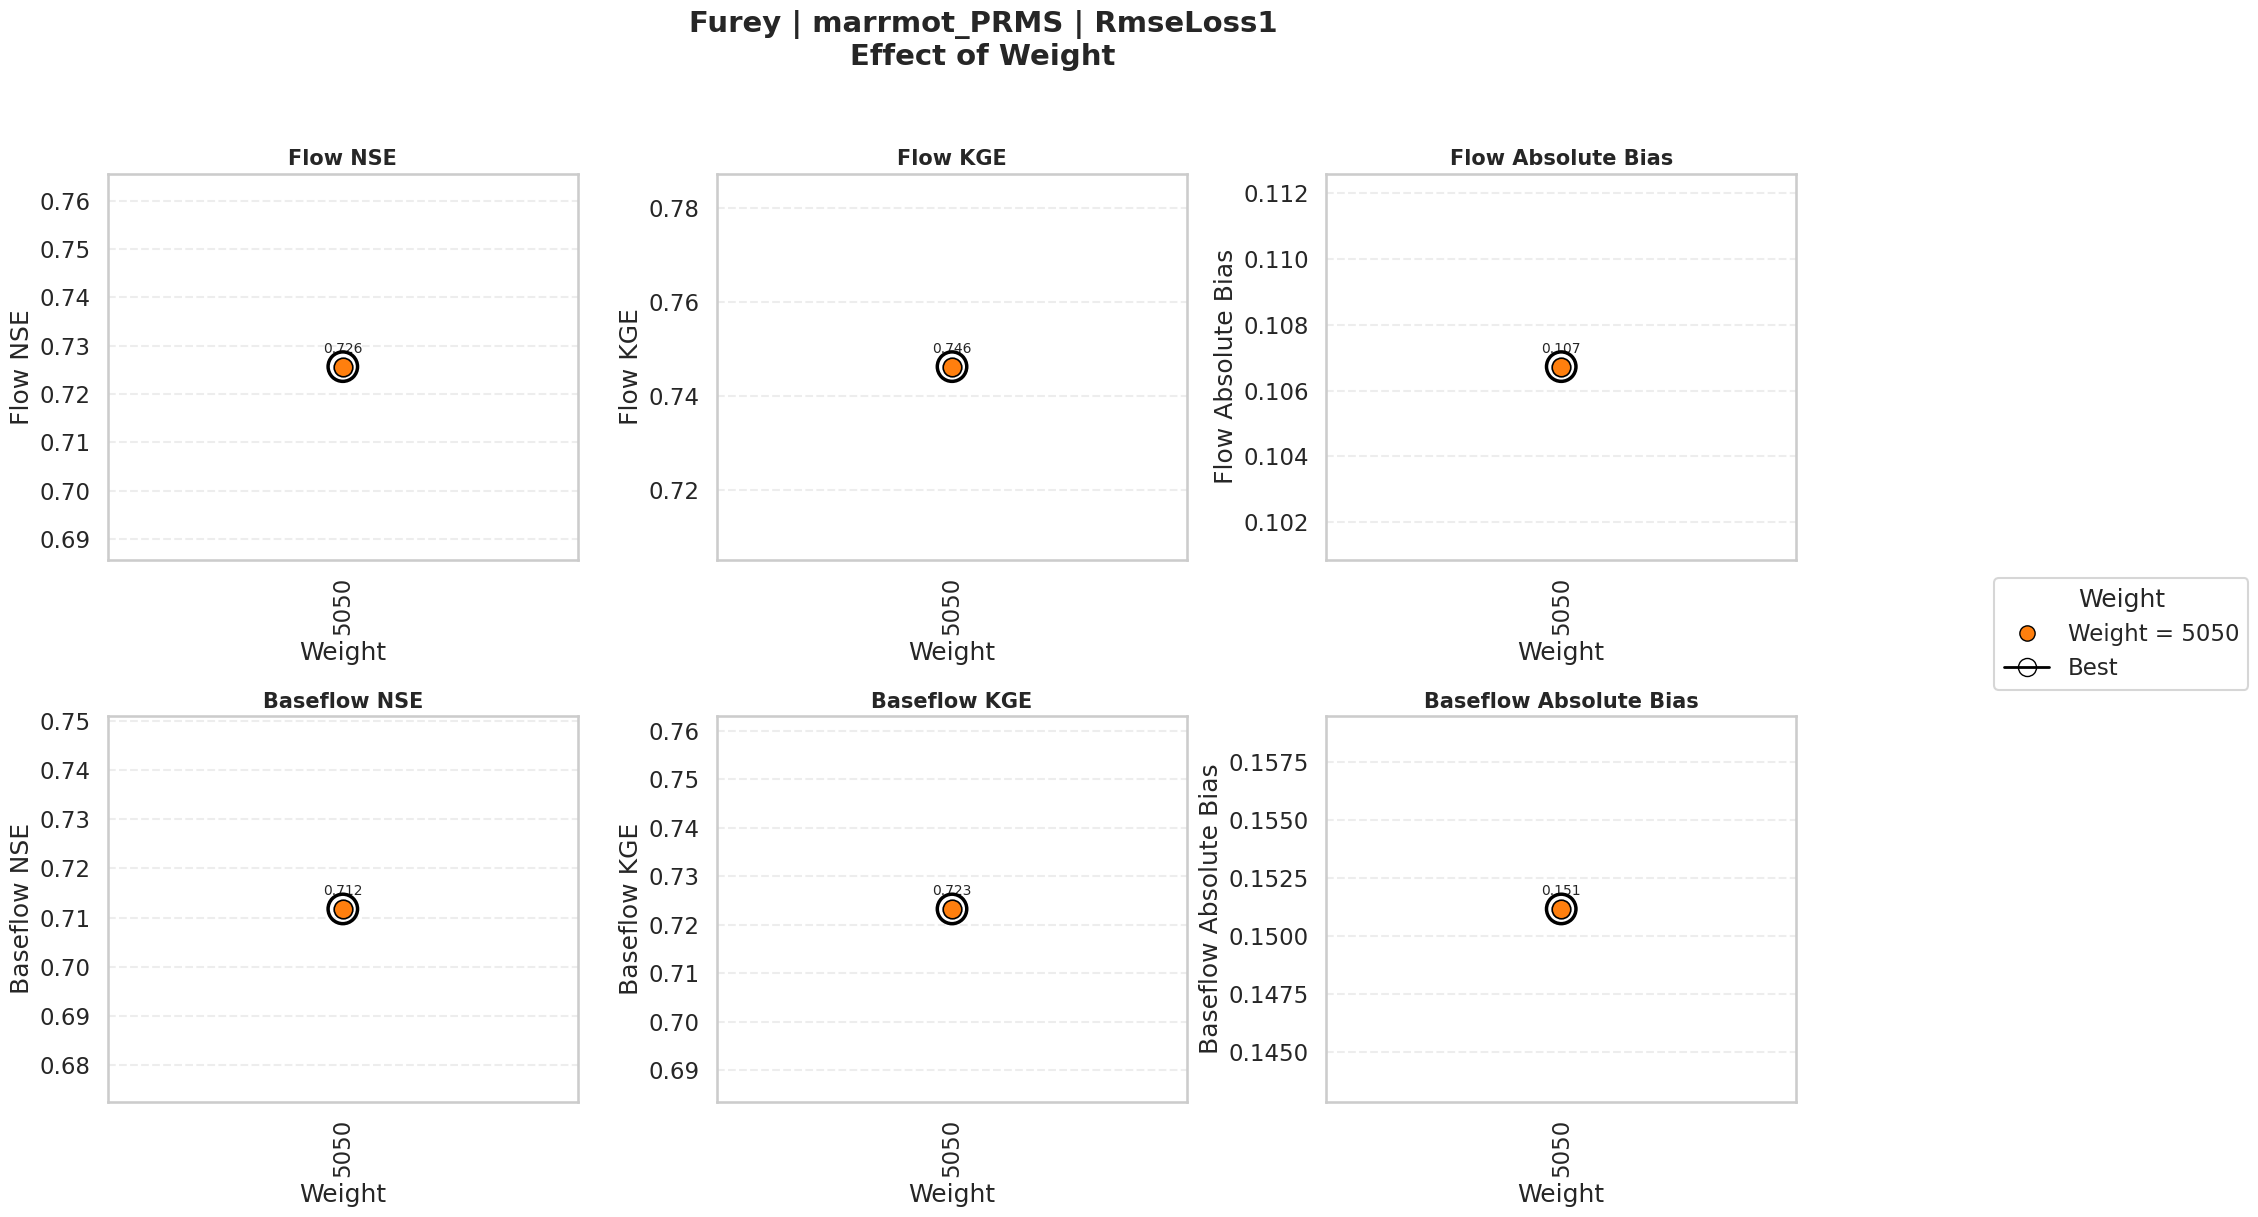

Plotting: Furey | marrmot_PRMS | RMSE_4items


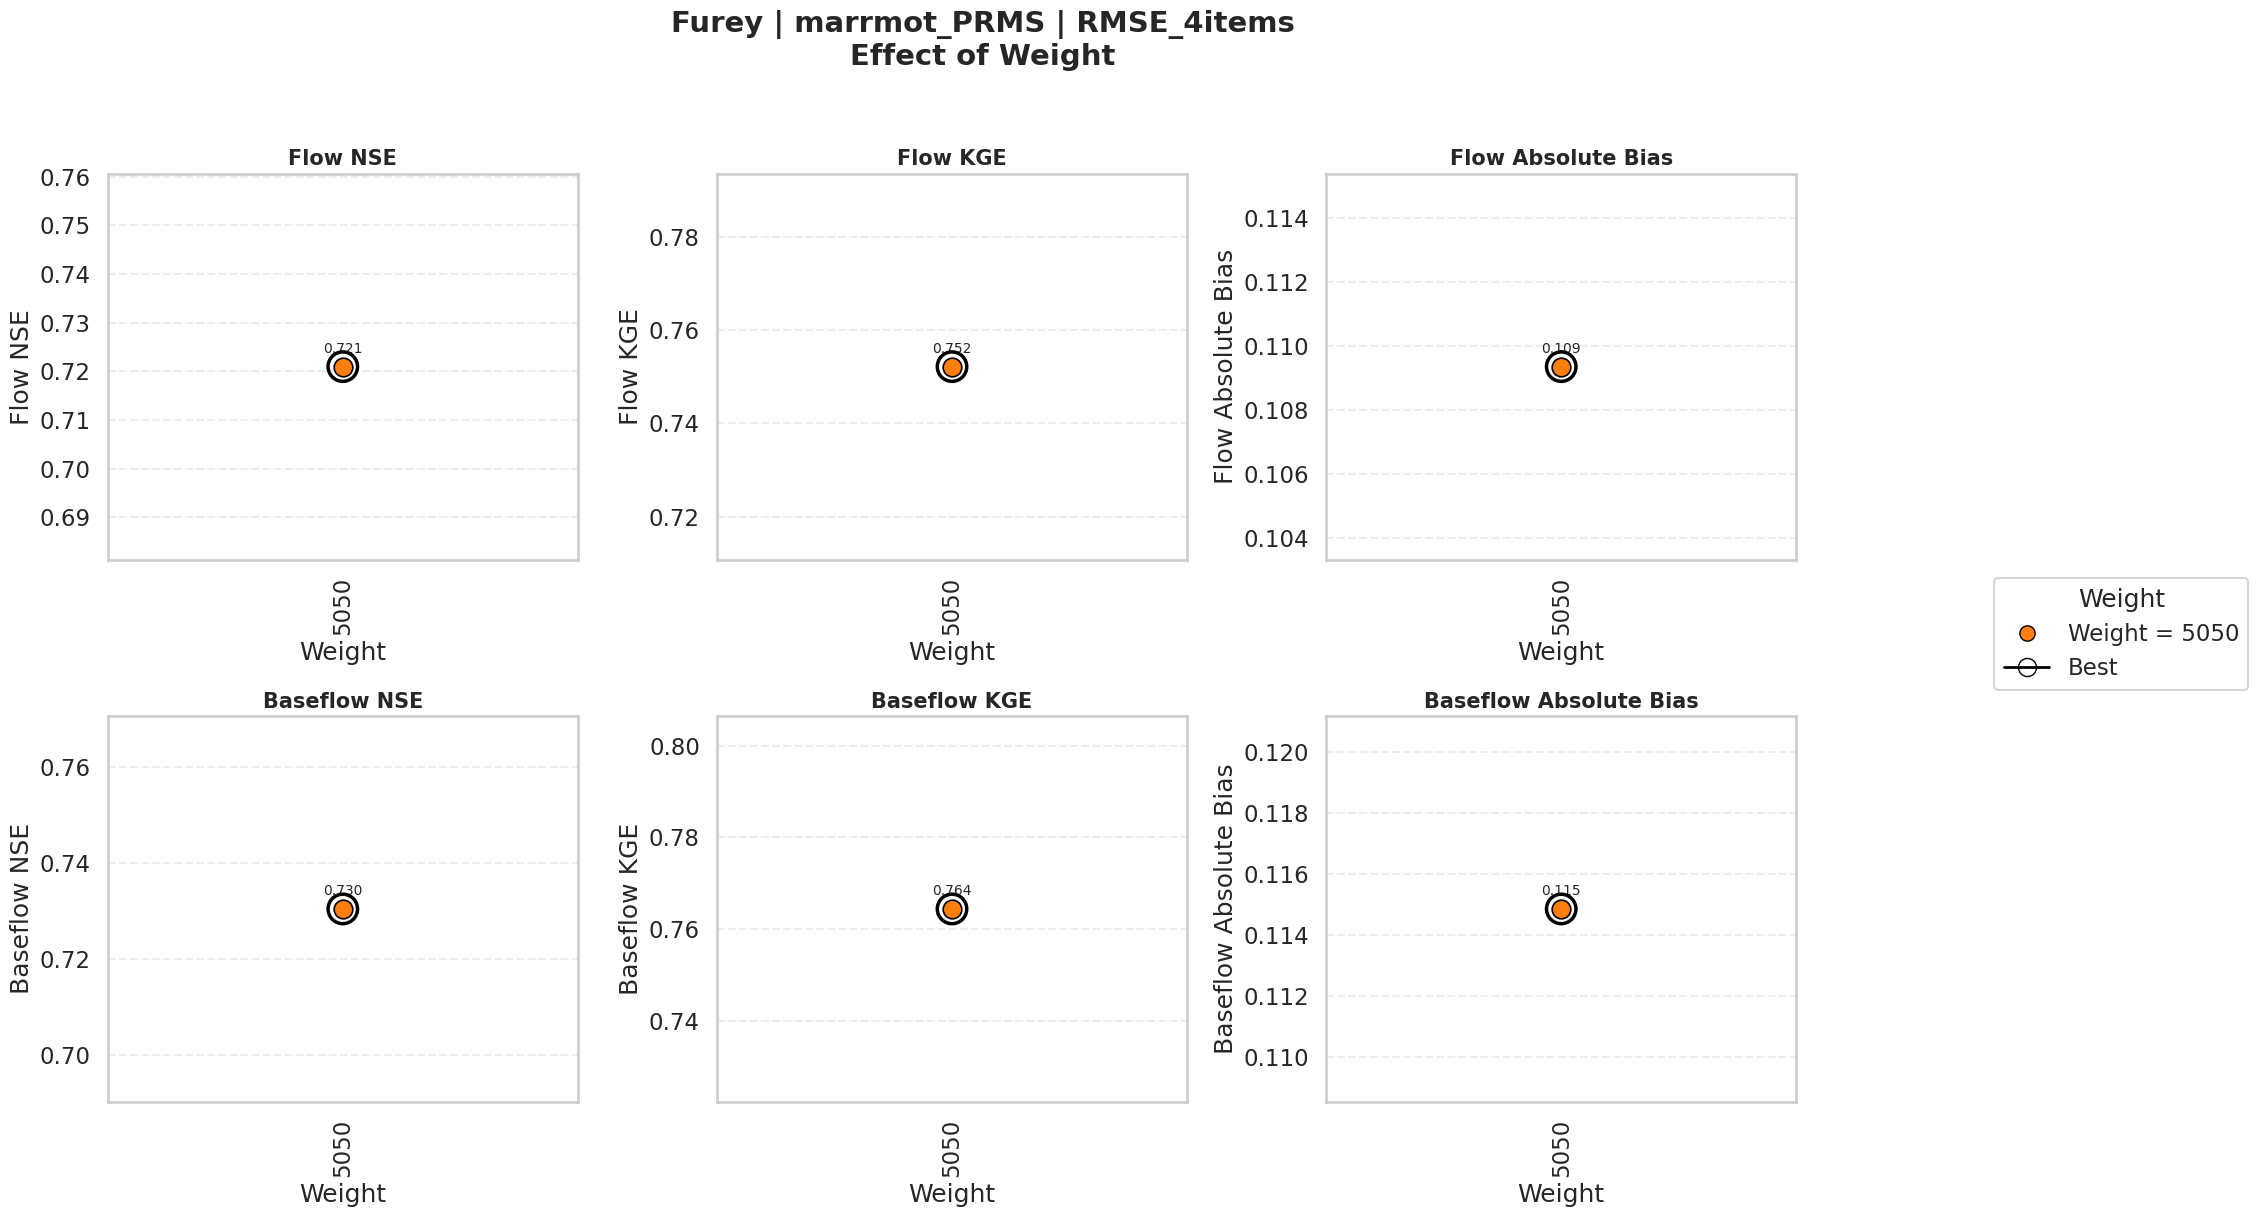

Plotting: Furey | marrmot_PRMS | RMSE_4itemsv2


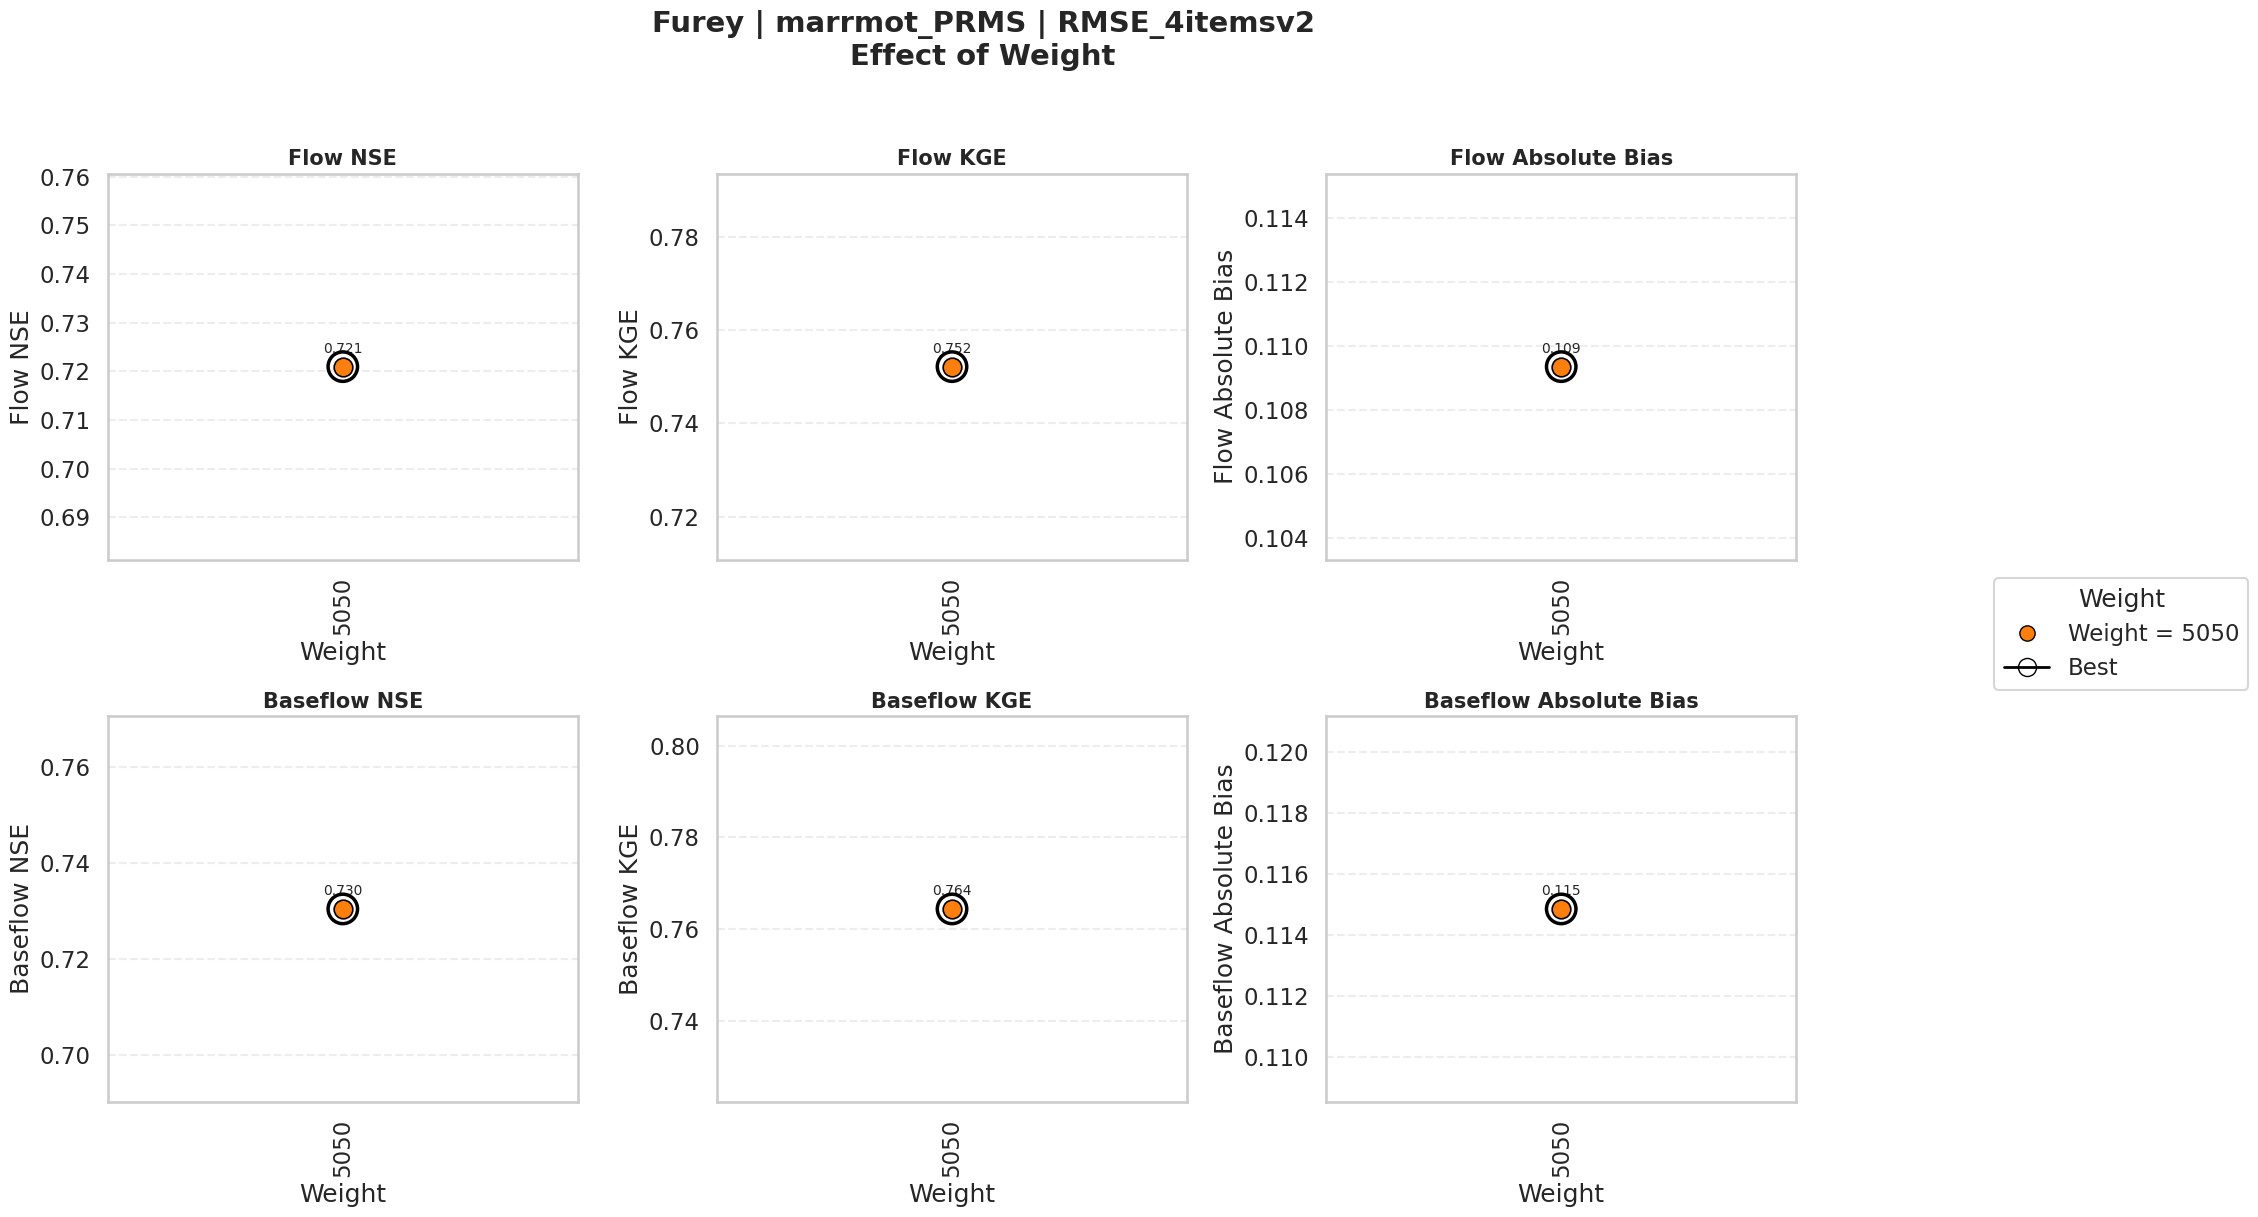

Plotting: Furey | HBV_capillary | NseLoss


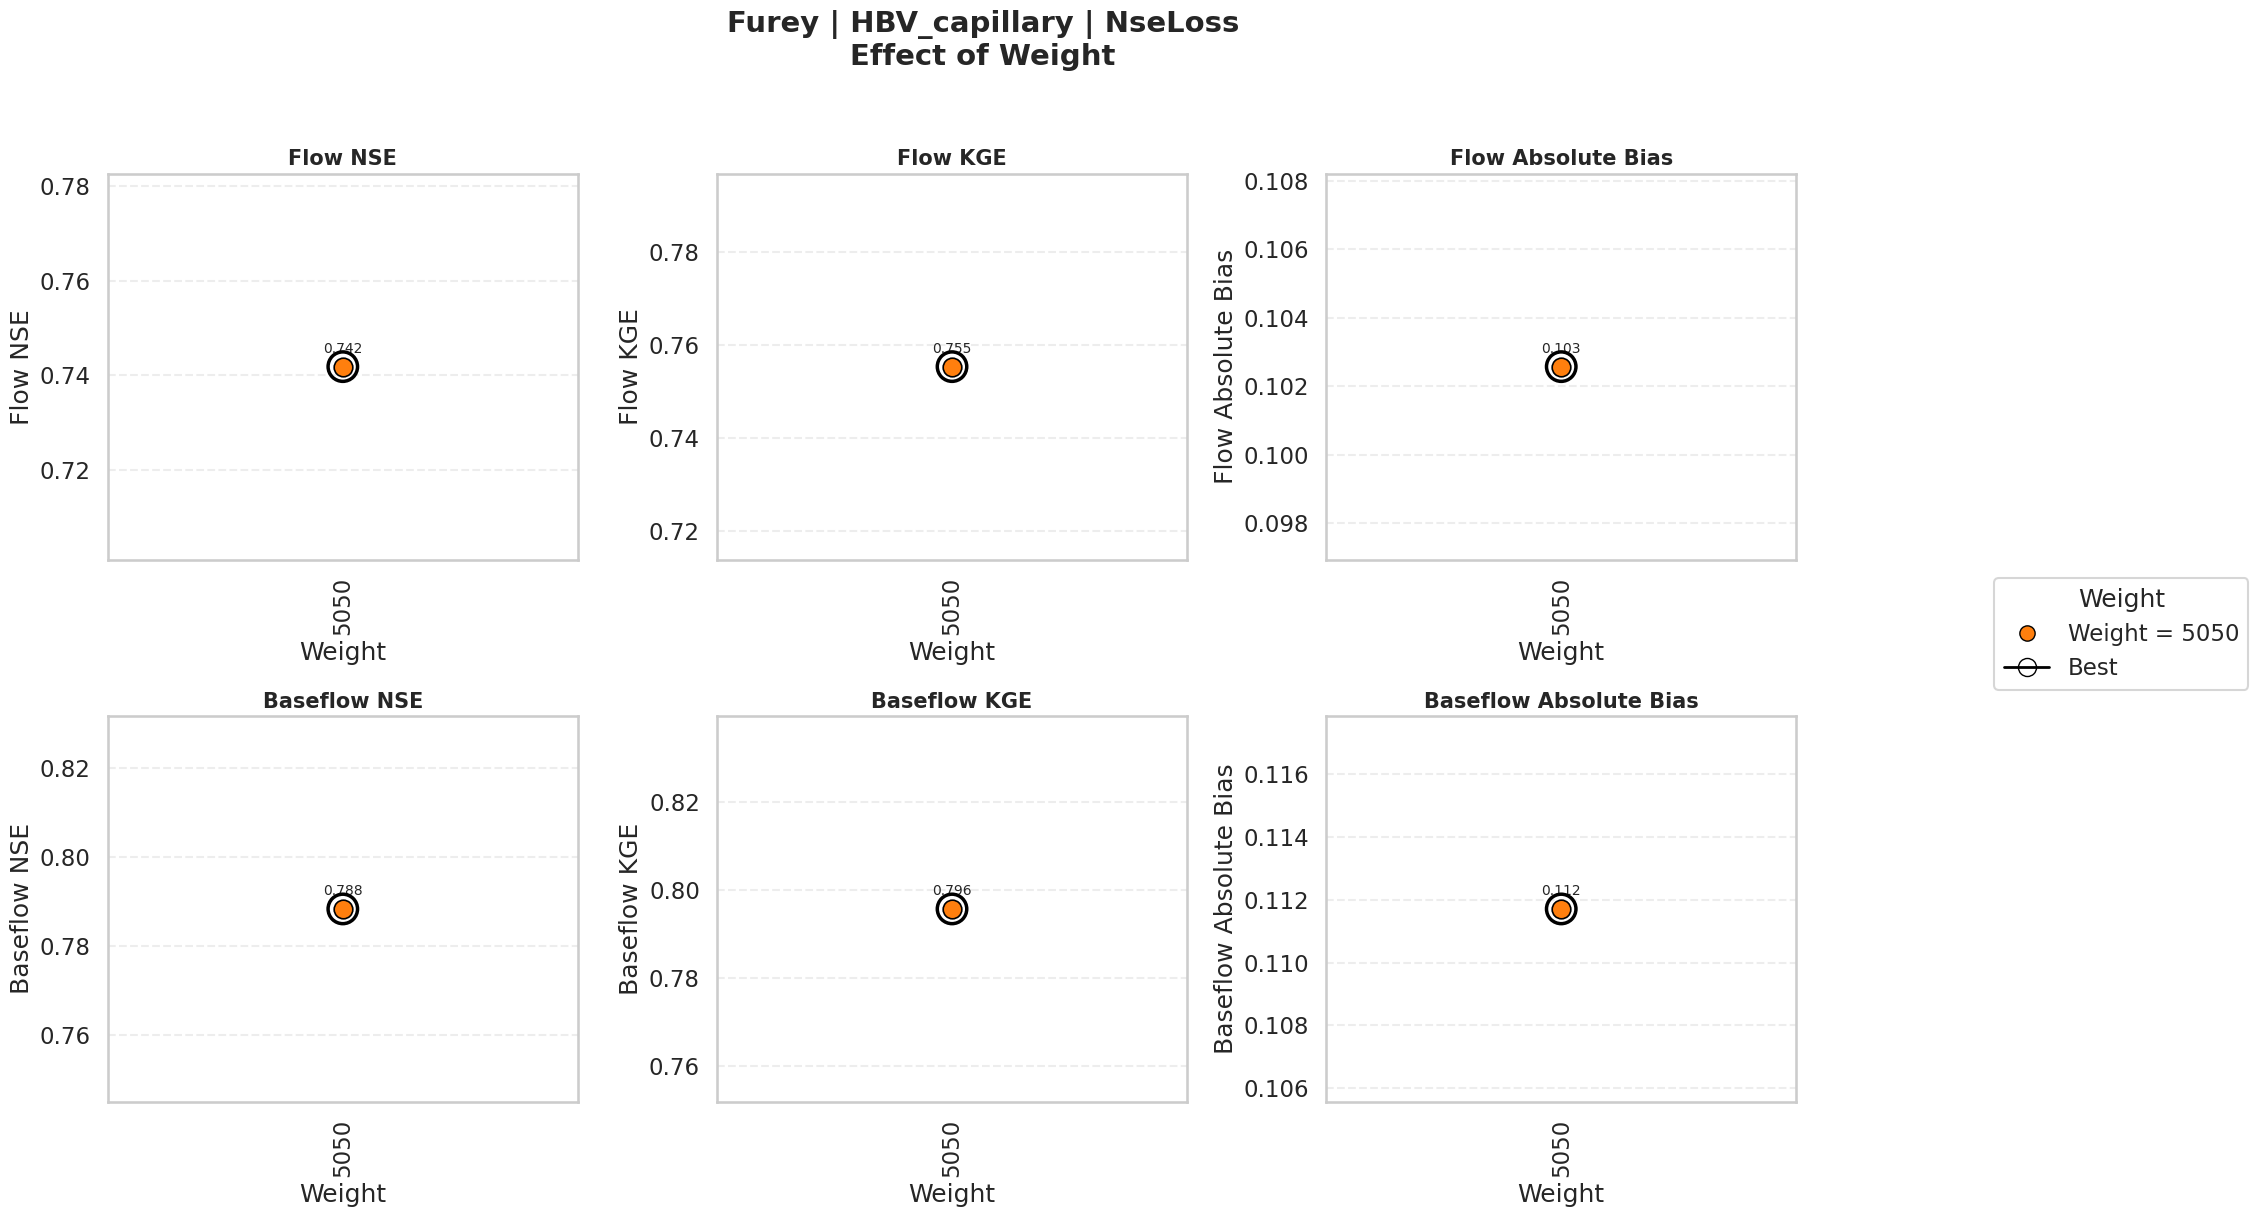

Plotting: Furey | HBV_capillary | RmseLoss


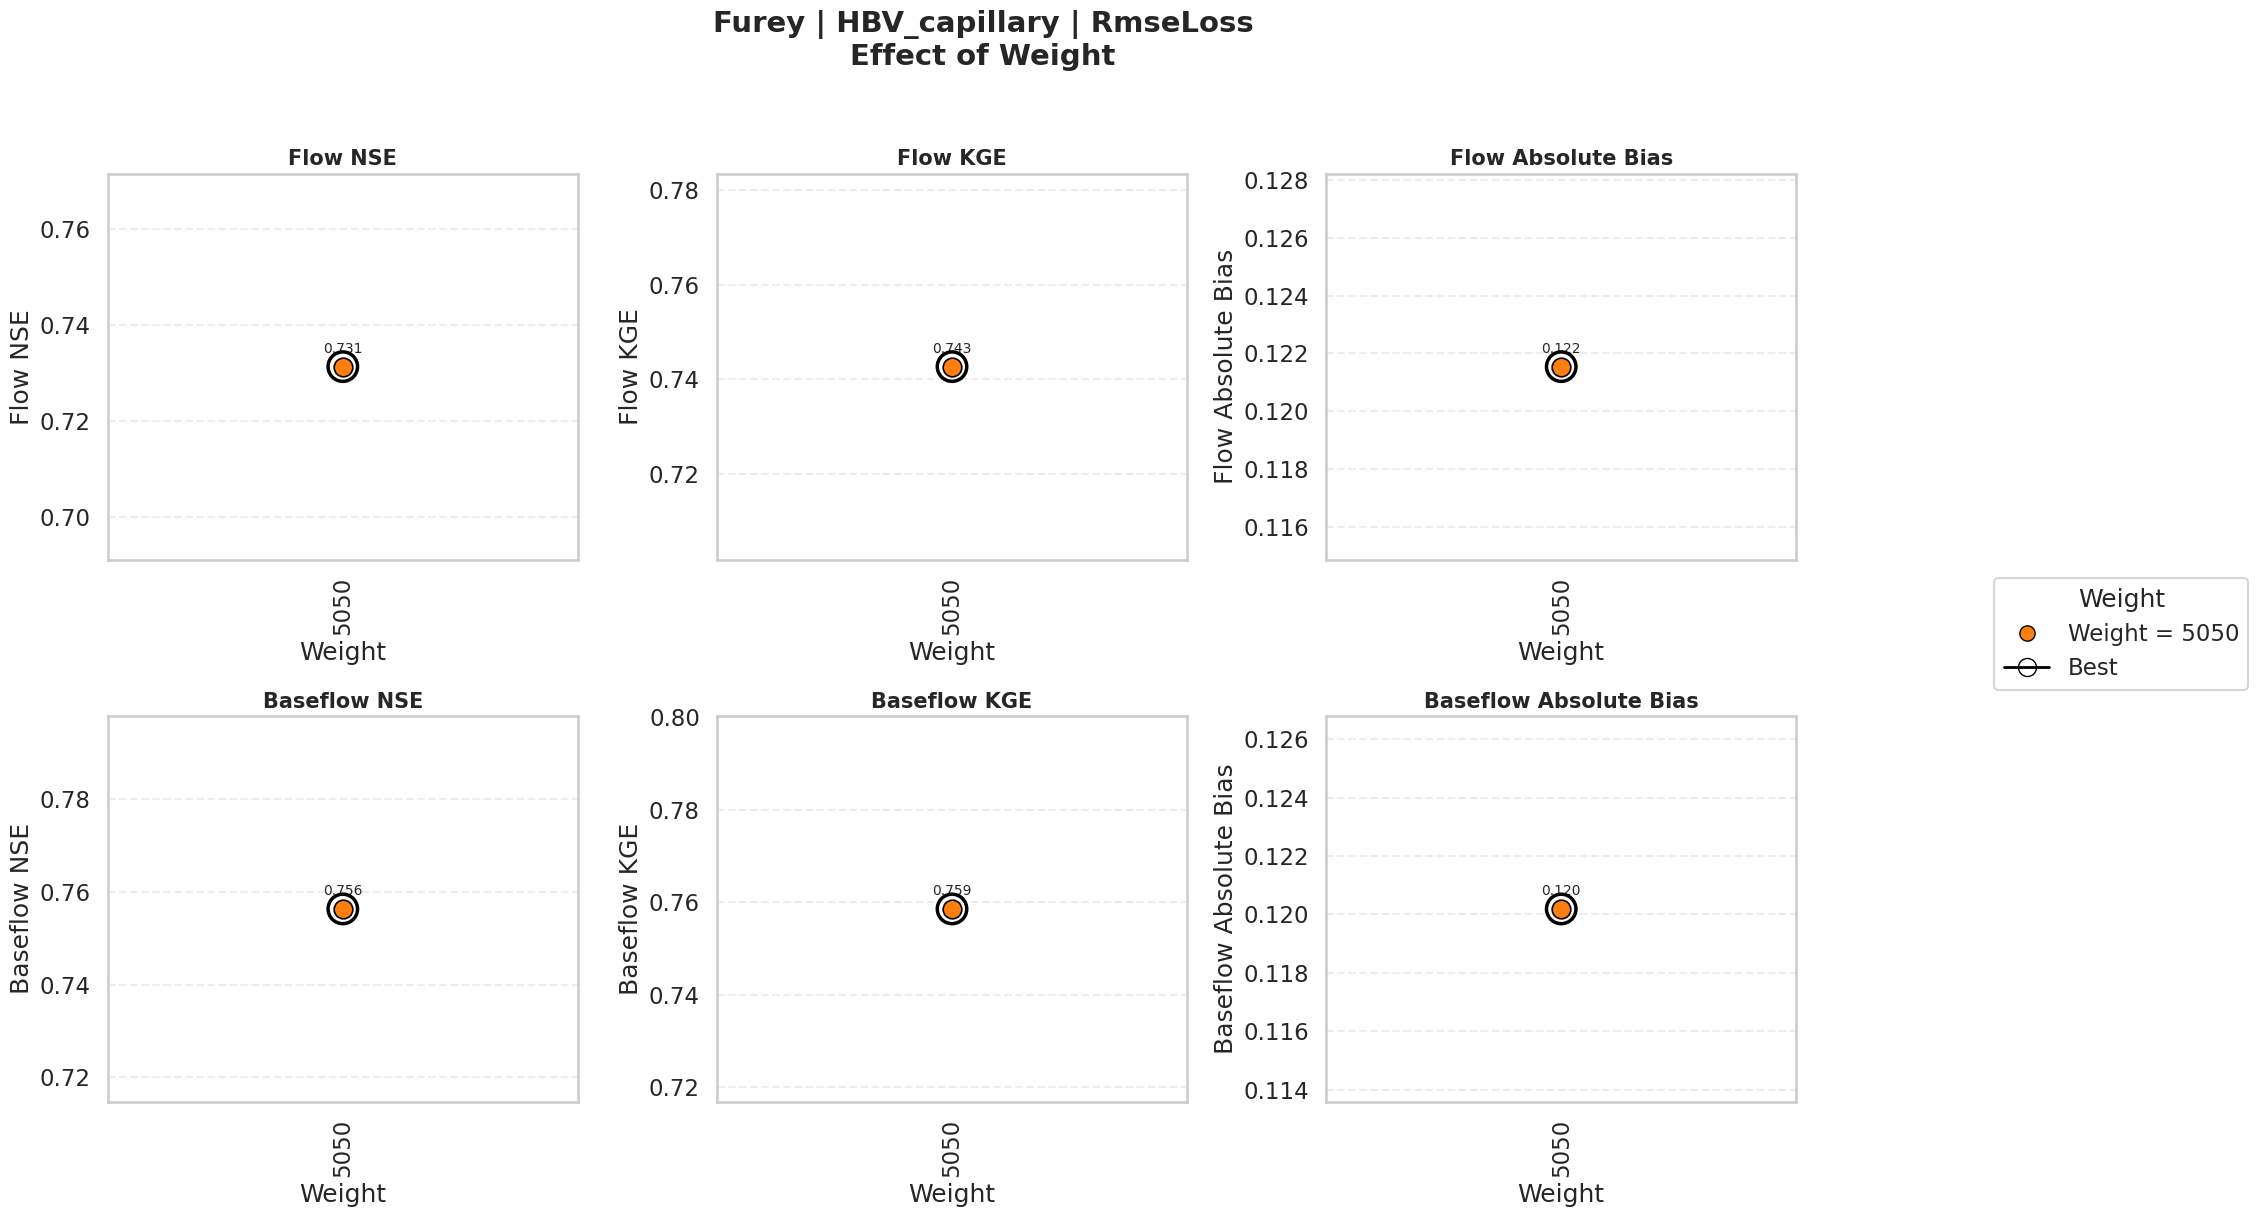

Plotting: Furey | HBV_capillary | RmseLoss1


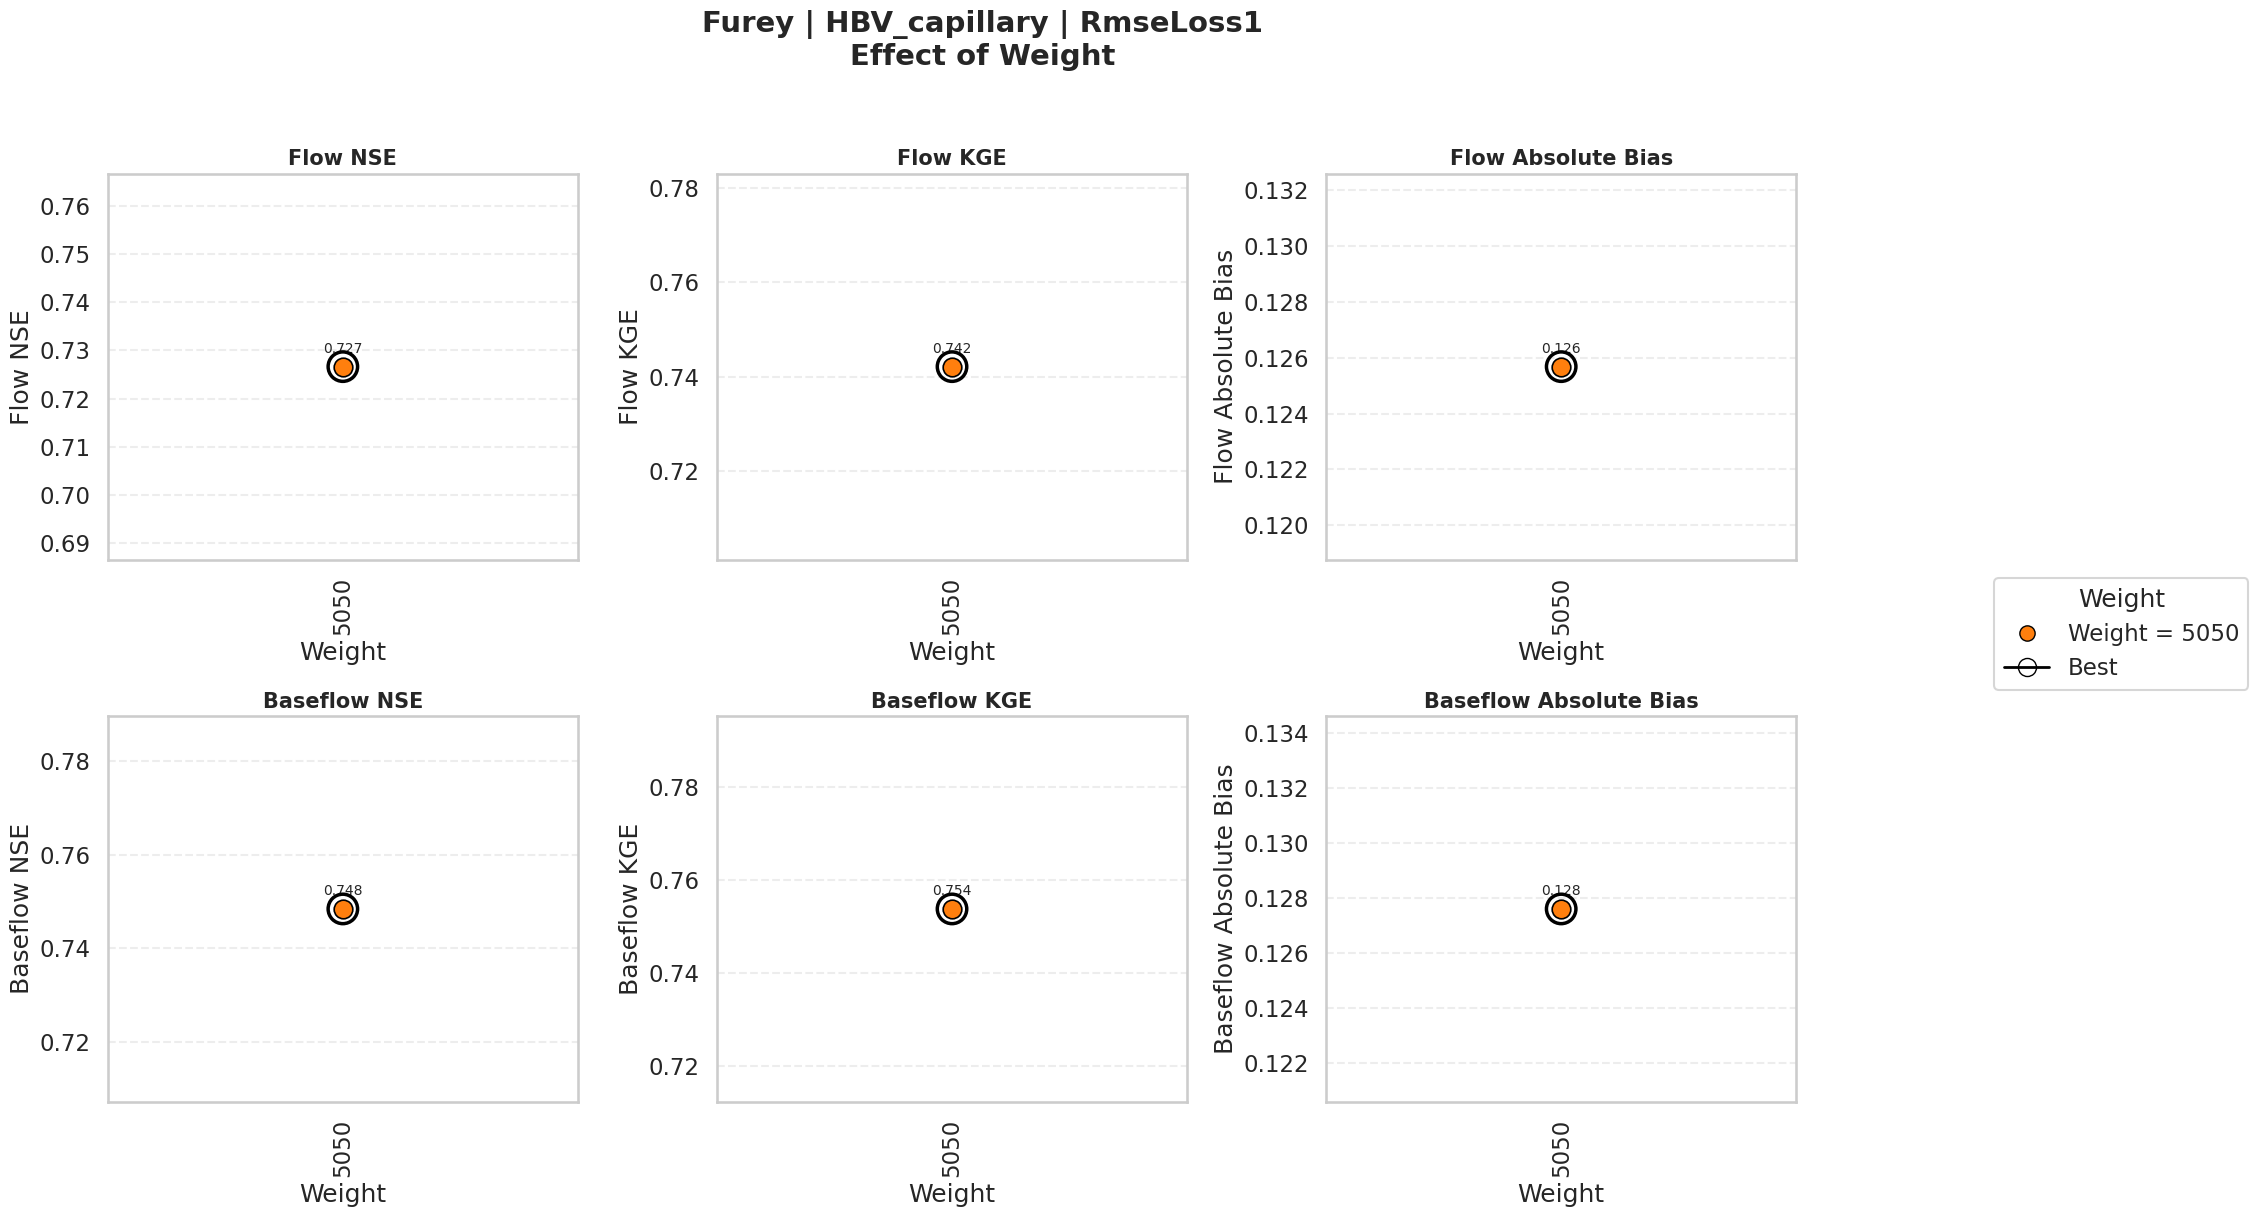

Plotting: Furey | HBV_capillary | RMSE_4items


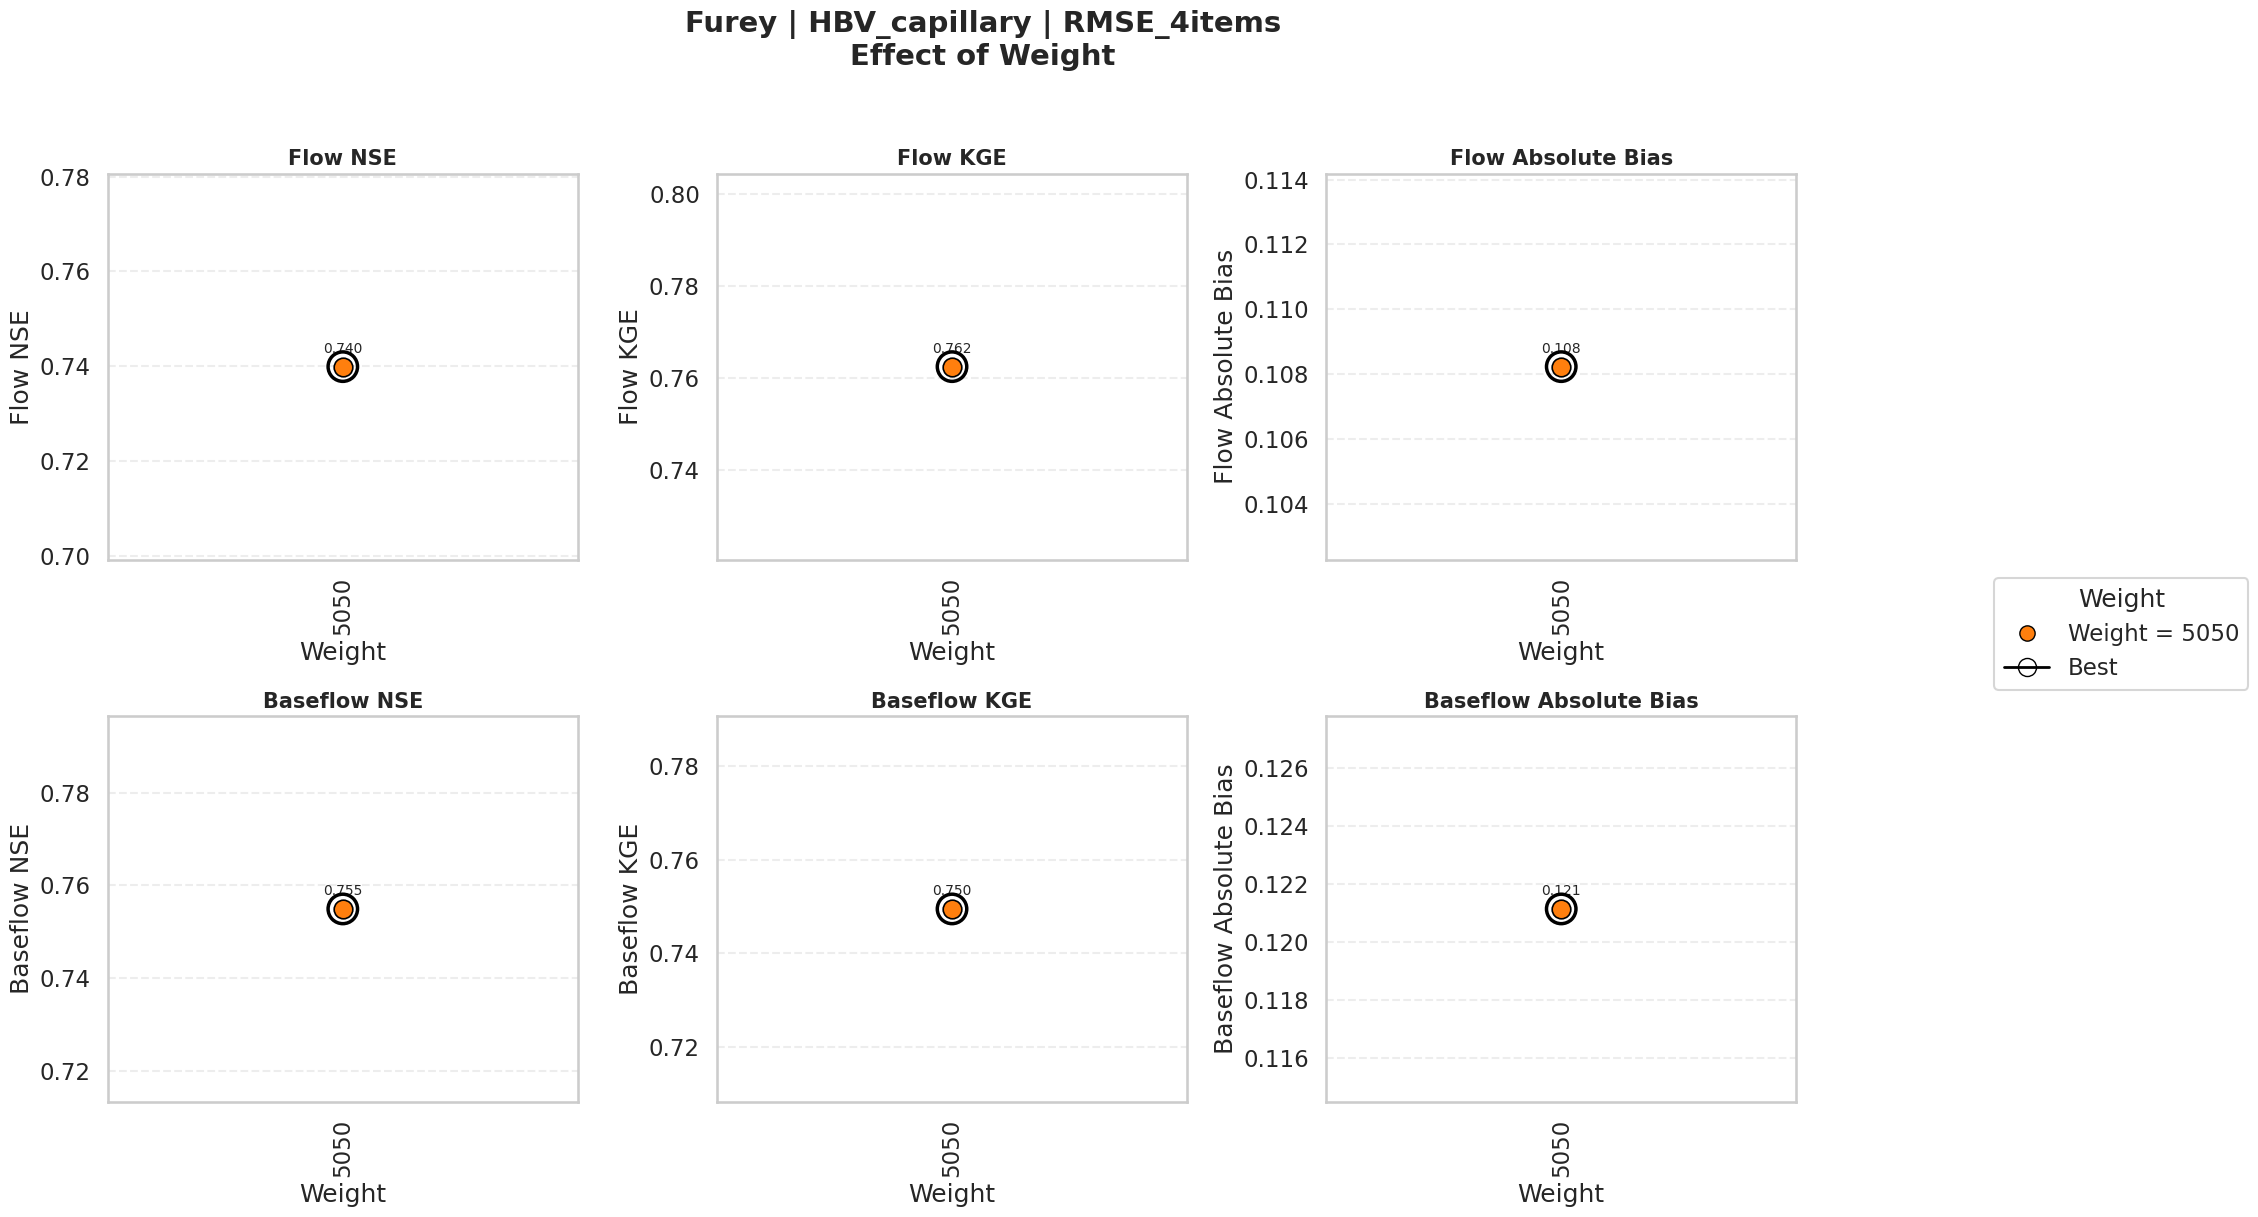

Plotting: Furey | HBV_capillary | RMSE_4itemsv2


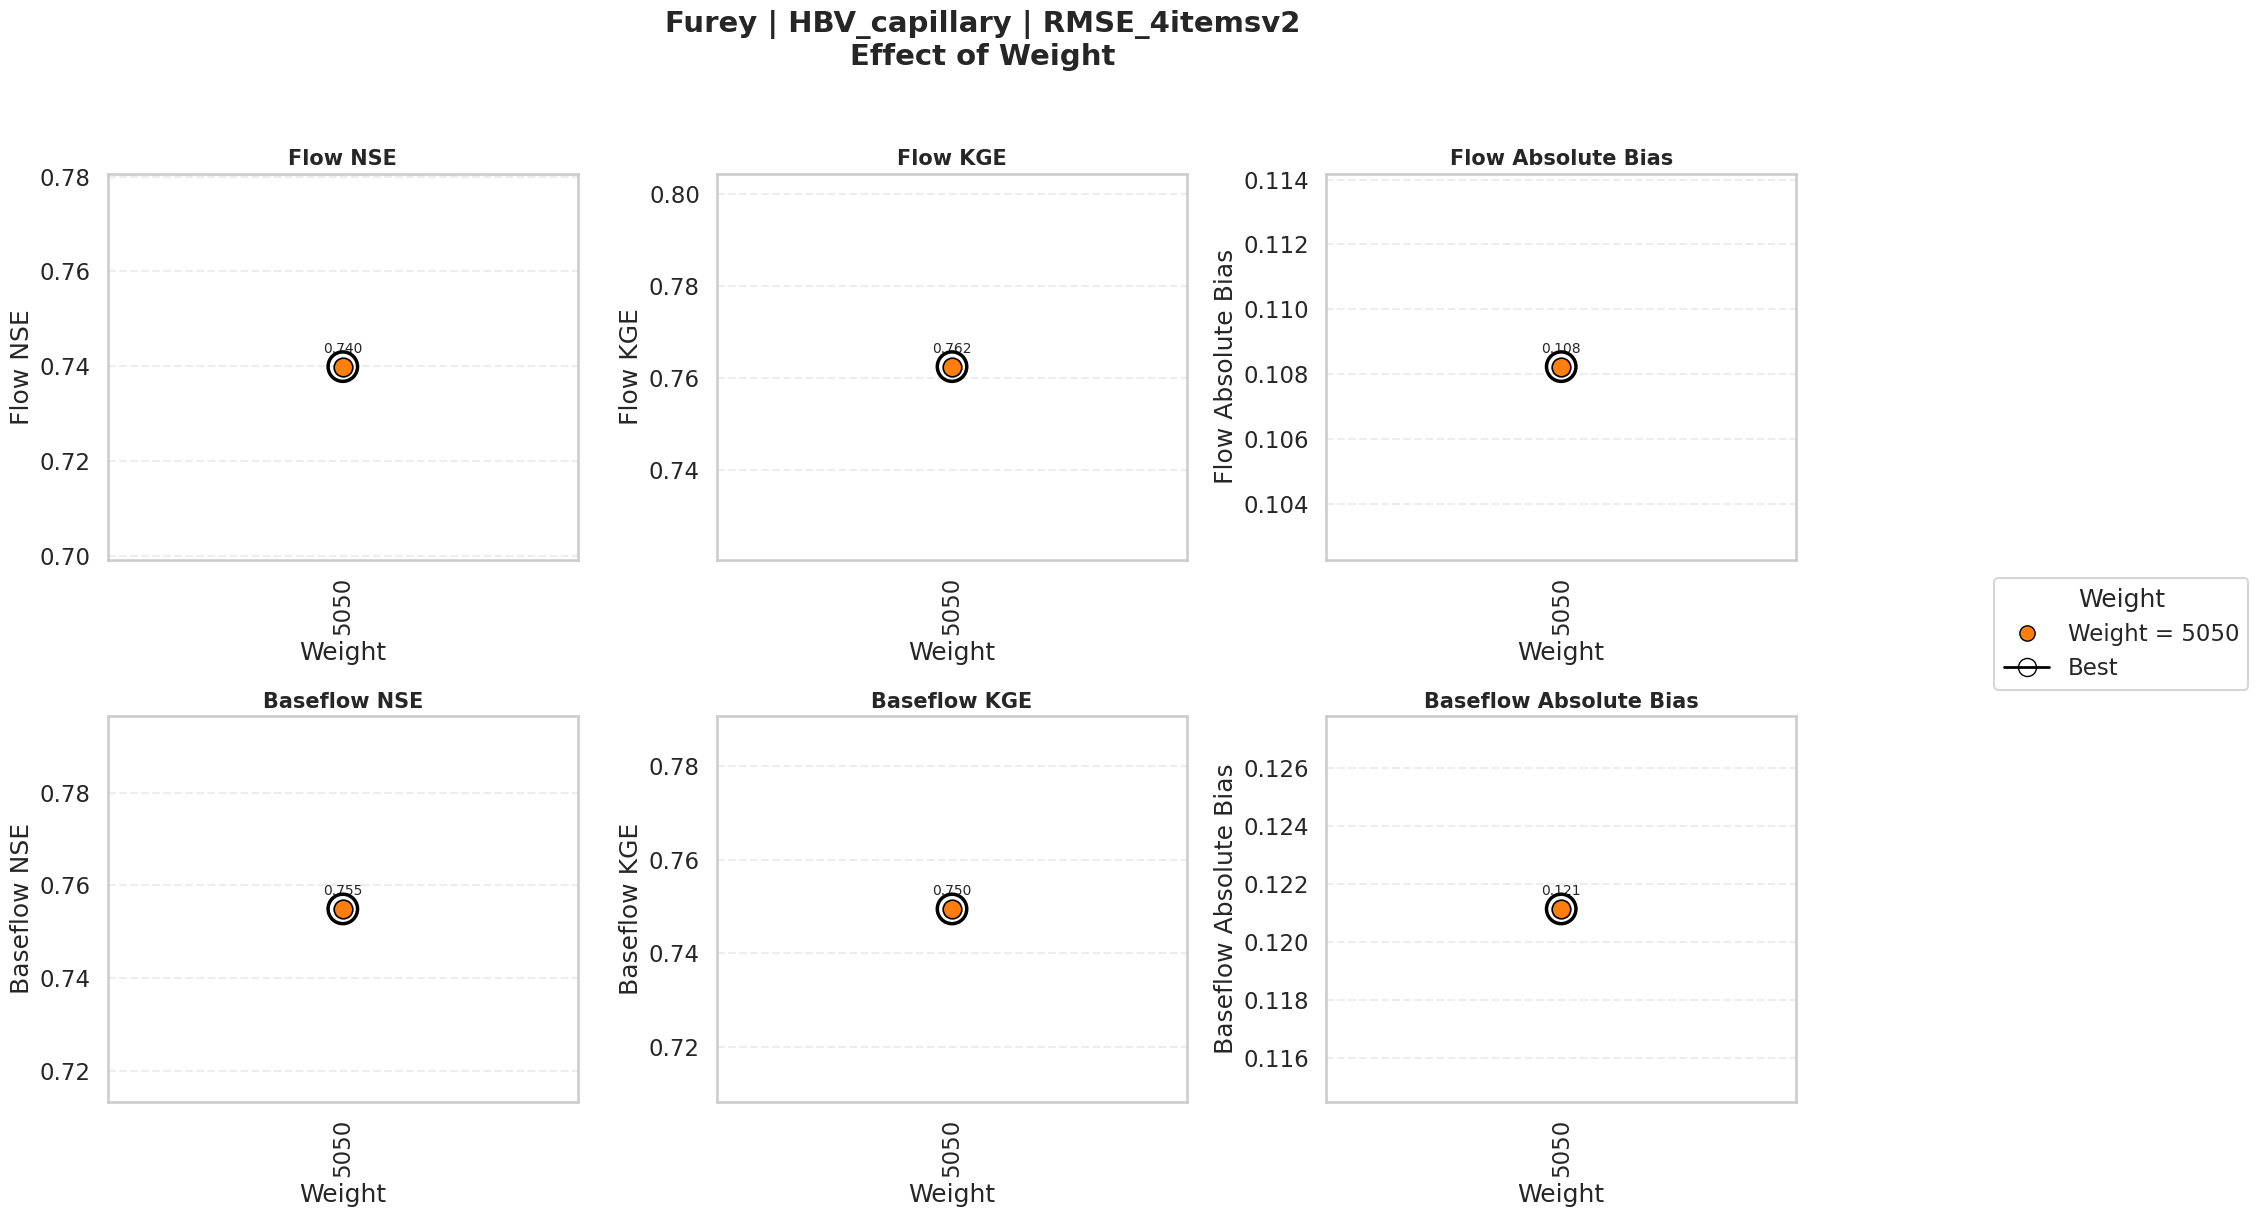



PART 2: EFFECT OF LOSS FUNCTION
Plotting: Furey | HBV | Weight = 5050


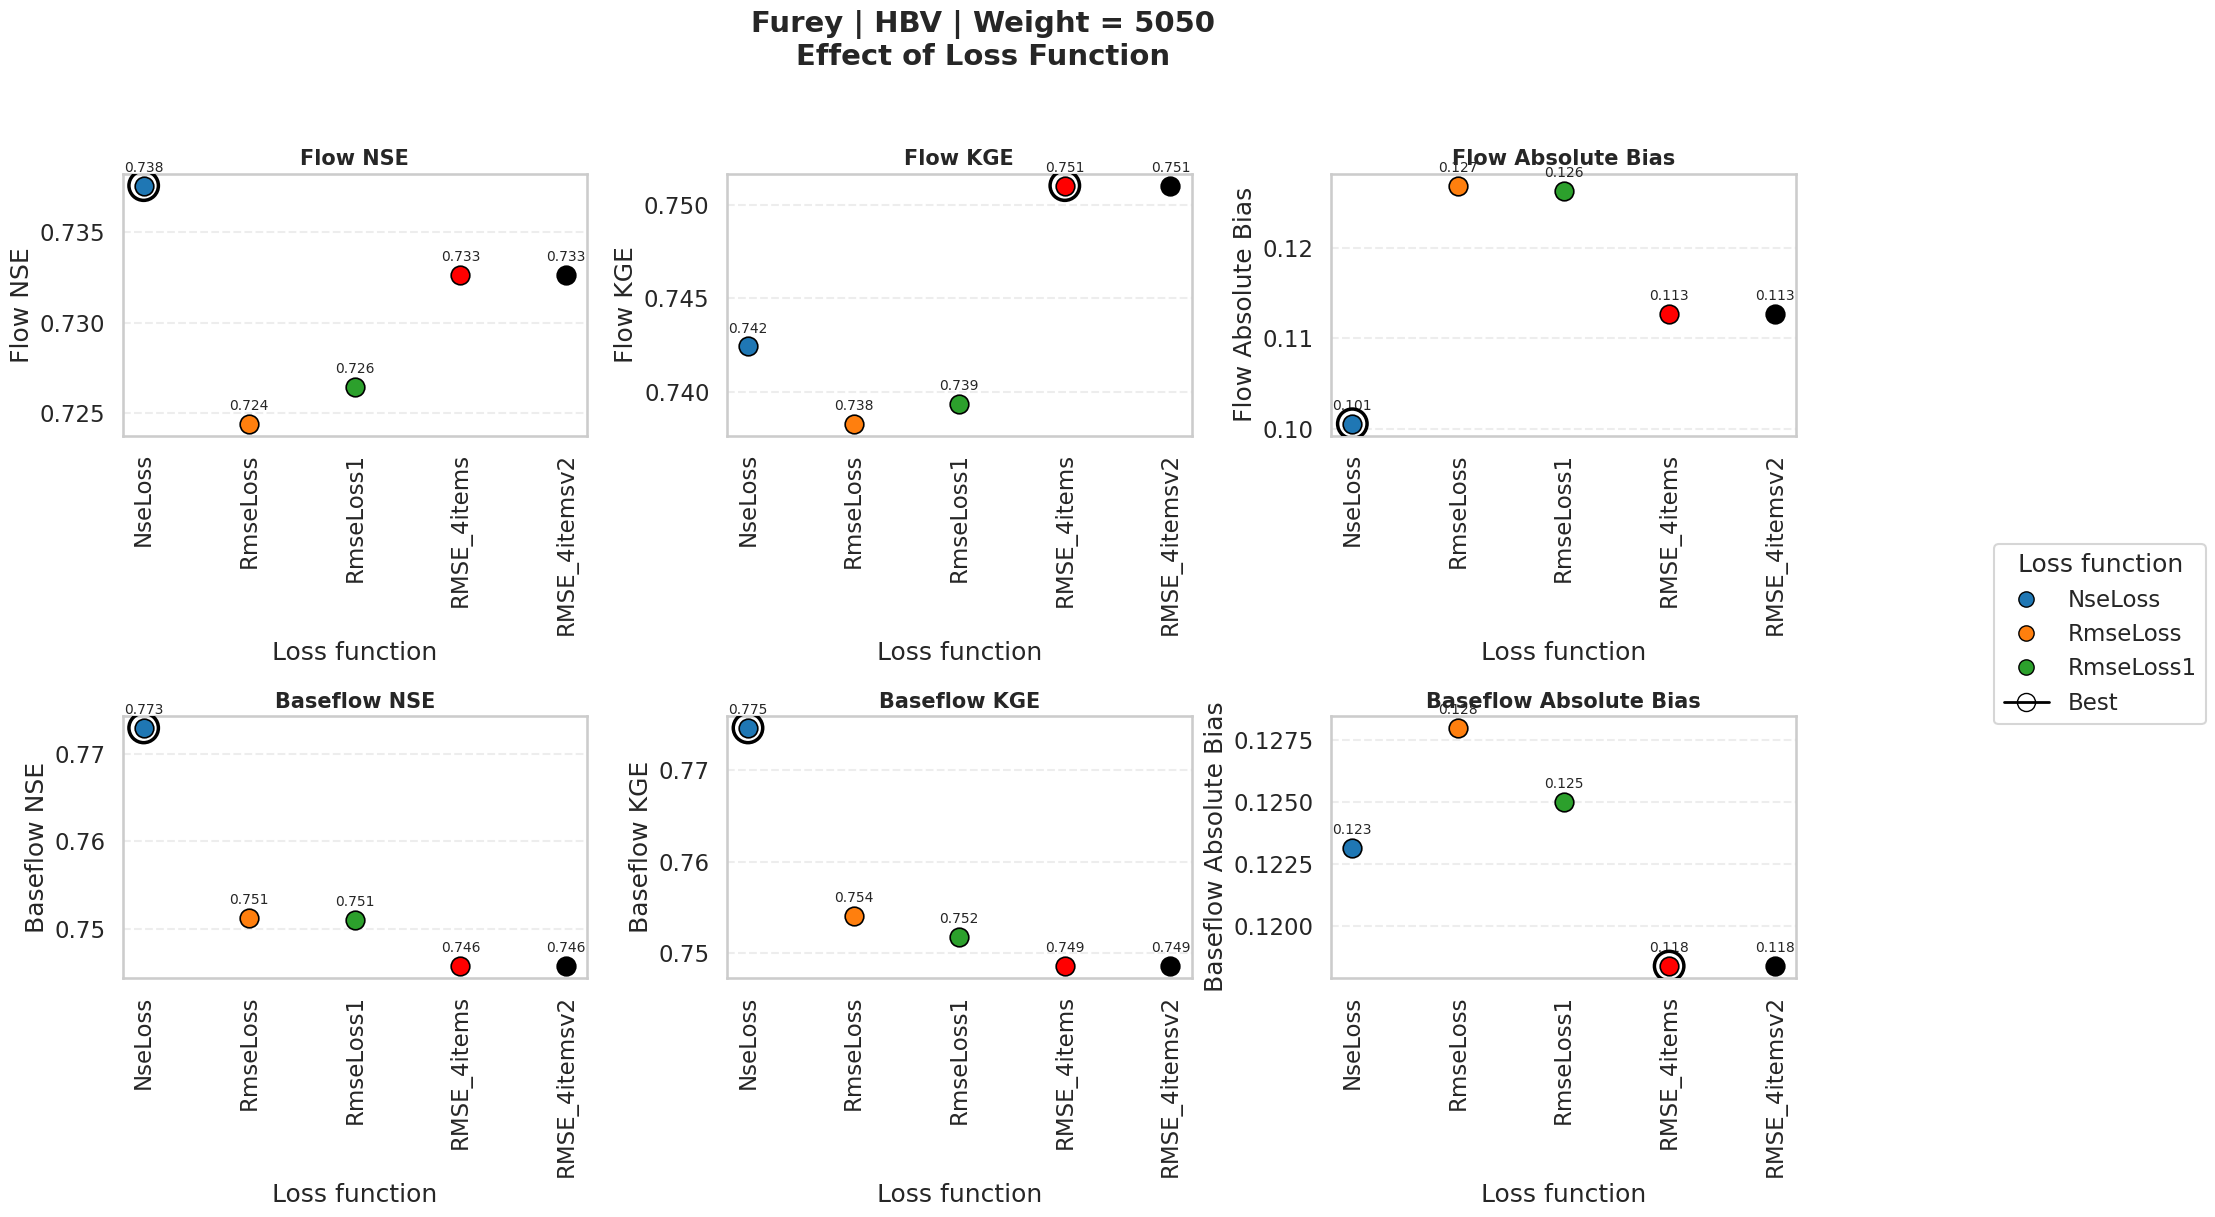

Plotting: Furey | marrmot_PRMS | Weight = 5050


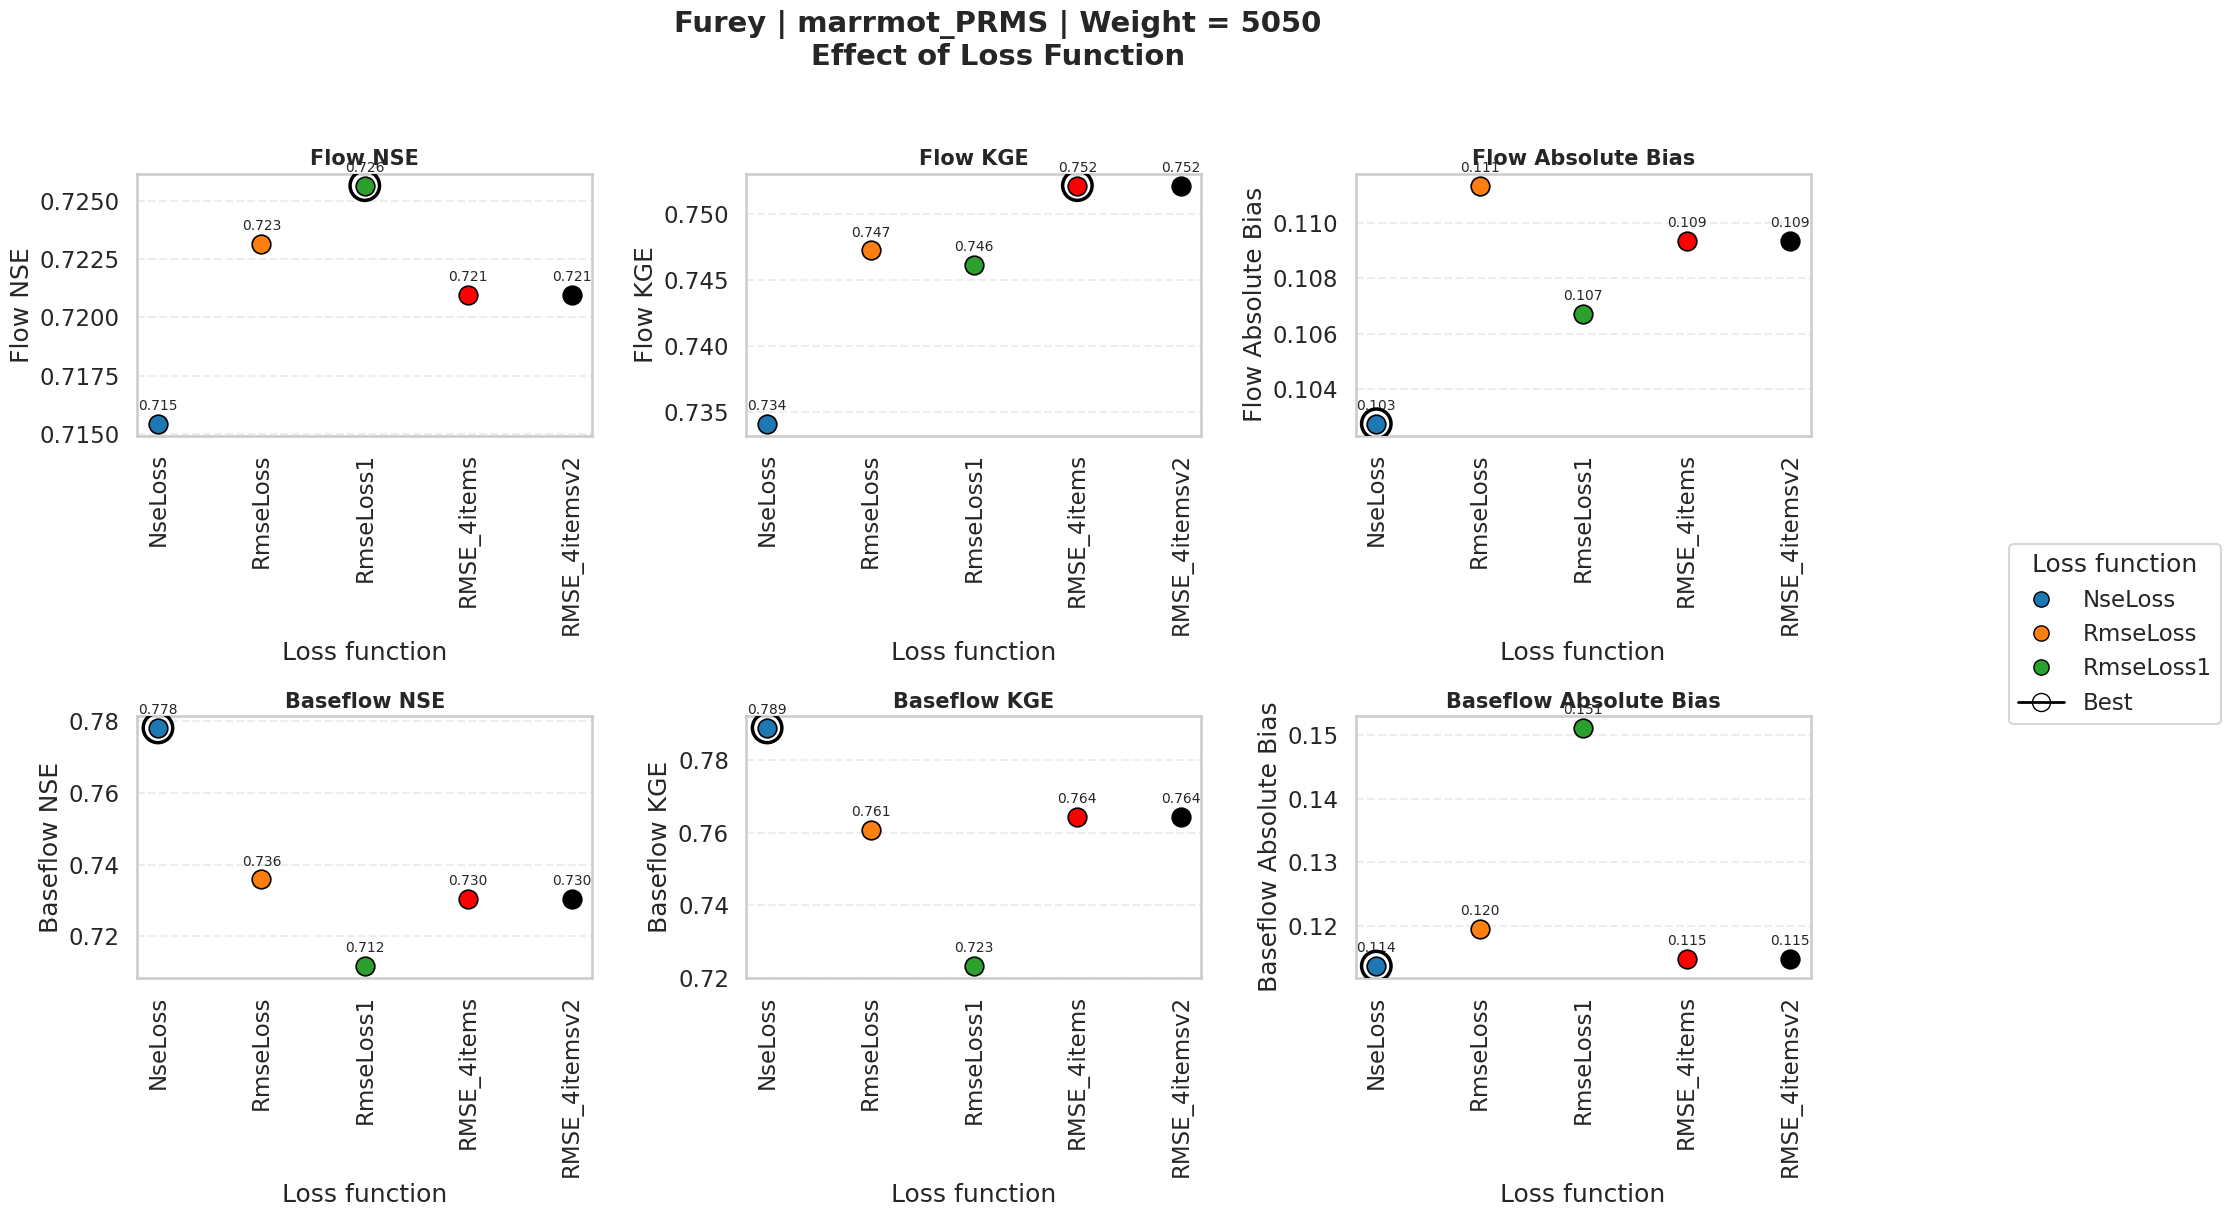

Plotting: Furey | HBV_capillary | Weight = 5050


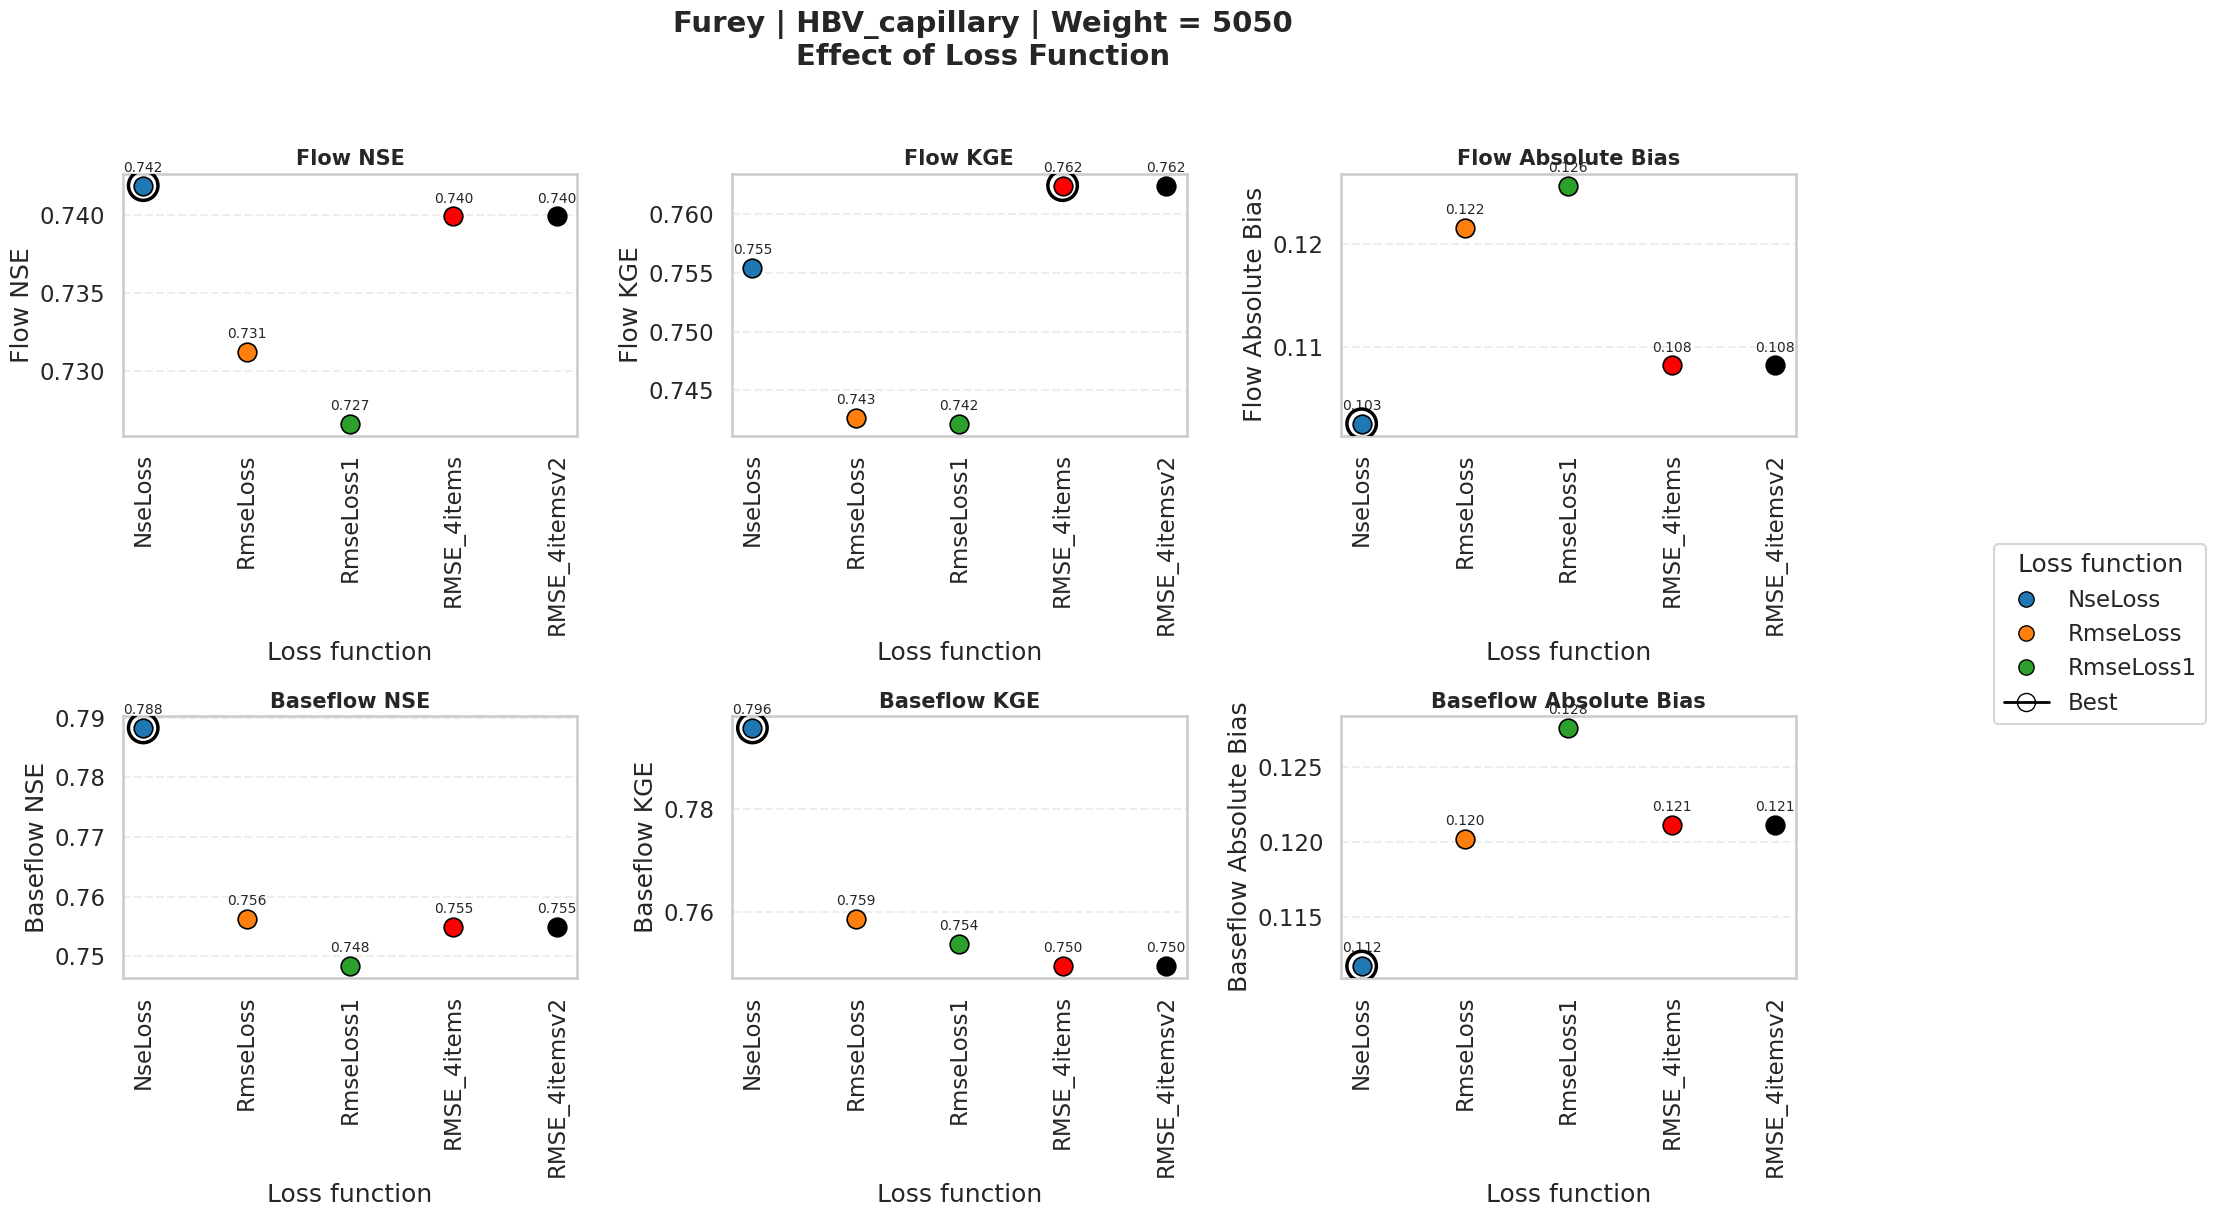



PART 3: BEST WEIGHT
Method         Model          Loss Best_NSE_Flow  Best_NSE_Flow_Value Best_KGE_Flow  Best_KGE_Flow_Value Best_Abs_Bias_Flow  Best_Abs_Bias_Flow_Value Best_NSE_Baseflow  Best_NSE_Baseflow_Value Best_KGE_Baseflow  Best_KGE_Baseflow_Value Best_Abs_Bias_Baseflow  Best_Abs_Bias_Baseflow_Value
 Furey           HBV       NseLoss          5050             0.737563          5050             0.742434               5050                  0.100536              5050                 0.772945              5050                 0.774623                   5050                      0.123159
 Furey           HBV      RmseLoss          5050             0.724410          5050             0.738306               5050                  0.126881              5050                 0.751298              5050                 0.754095                   5050                      0.128001
 Furey           HBV     RmseLoss1          5050             0.726458          5050             0.739369       

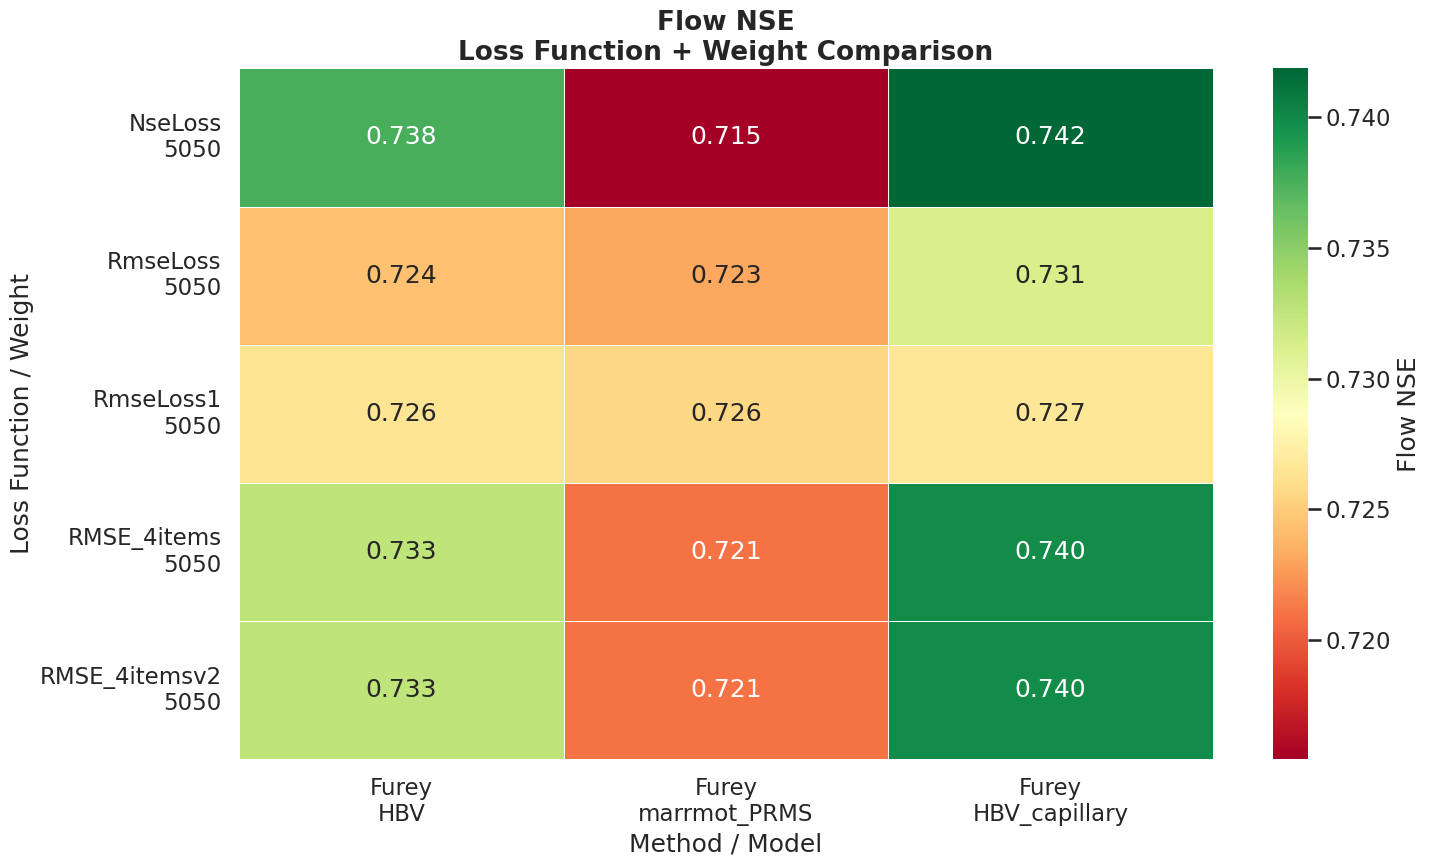

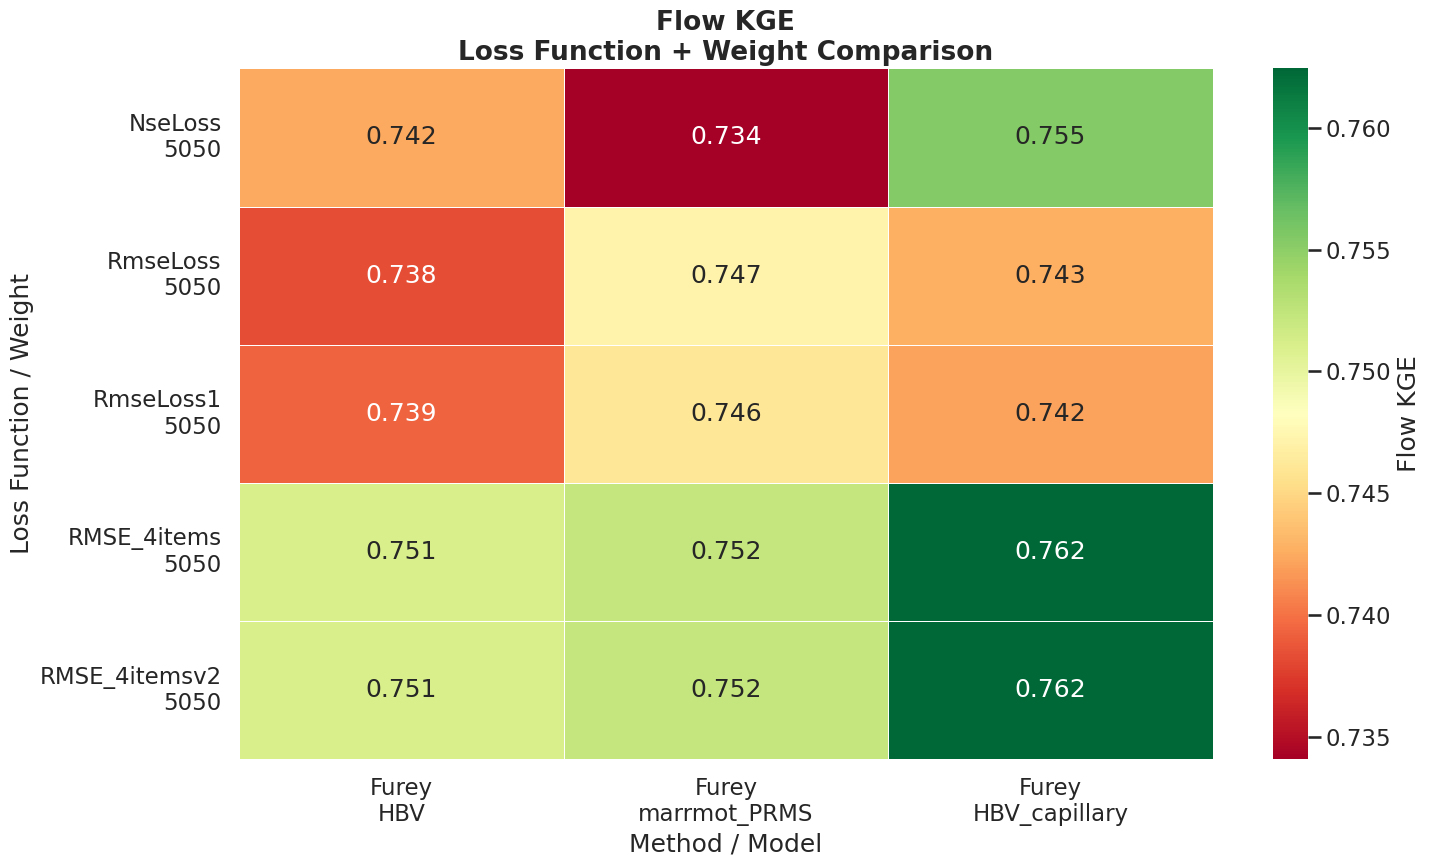

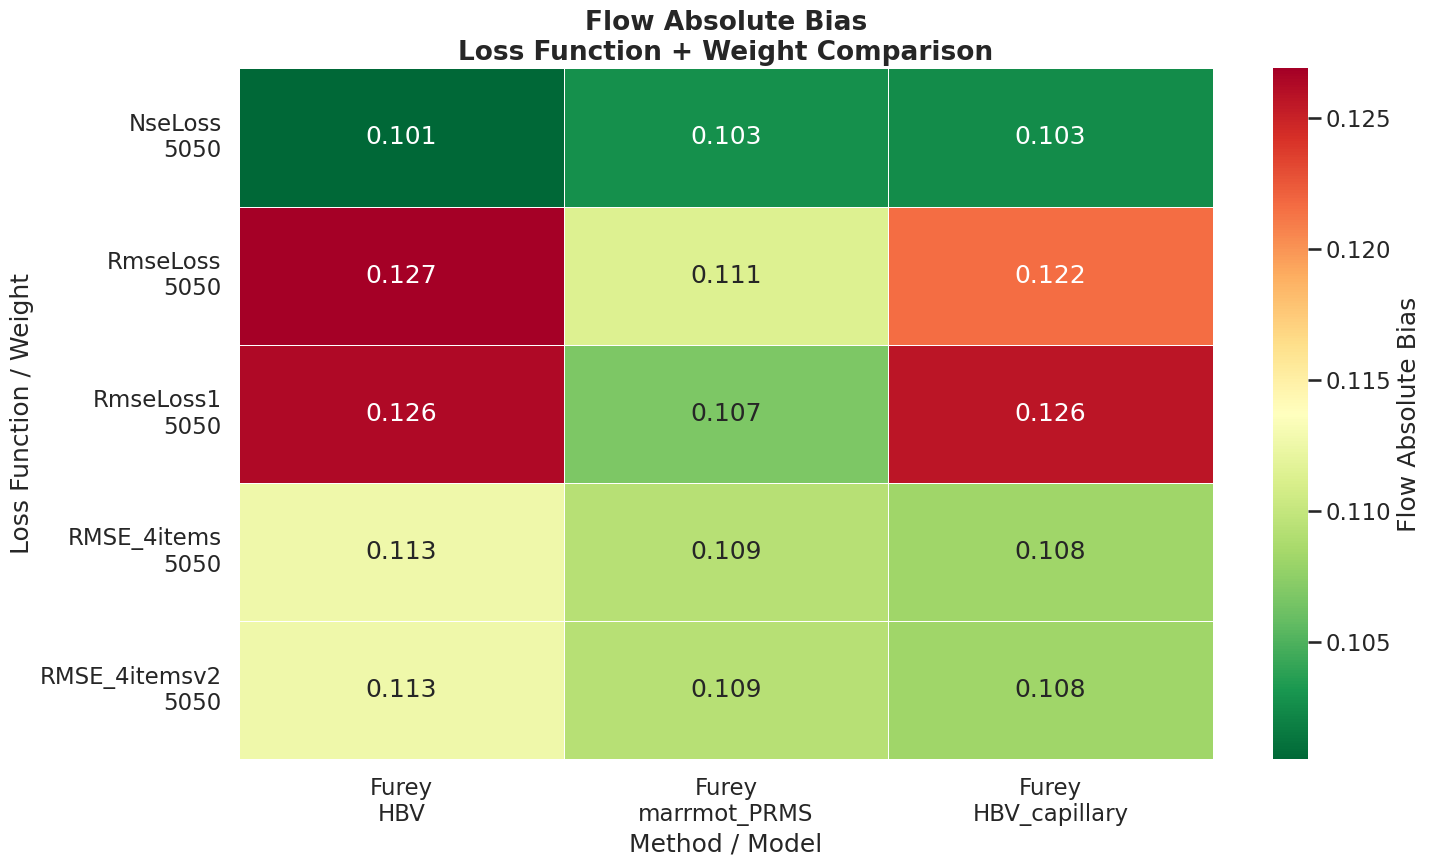

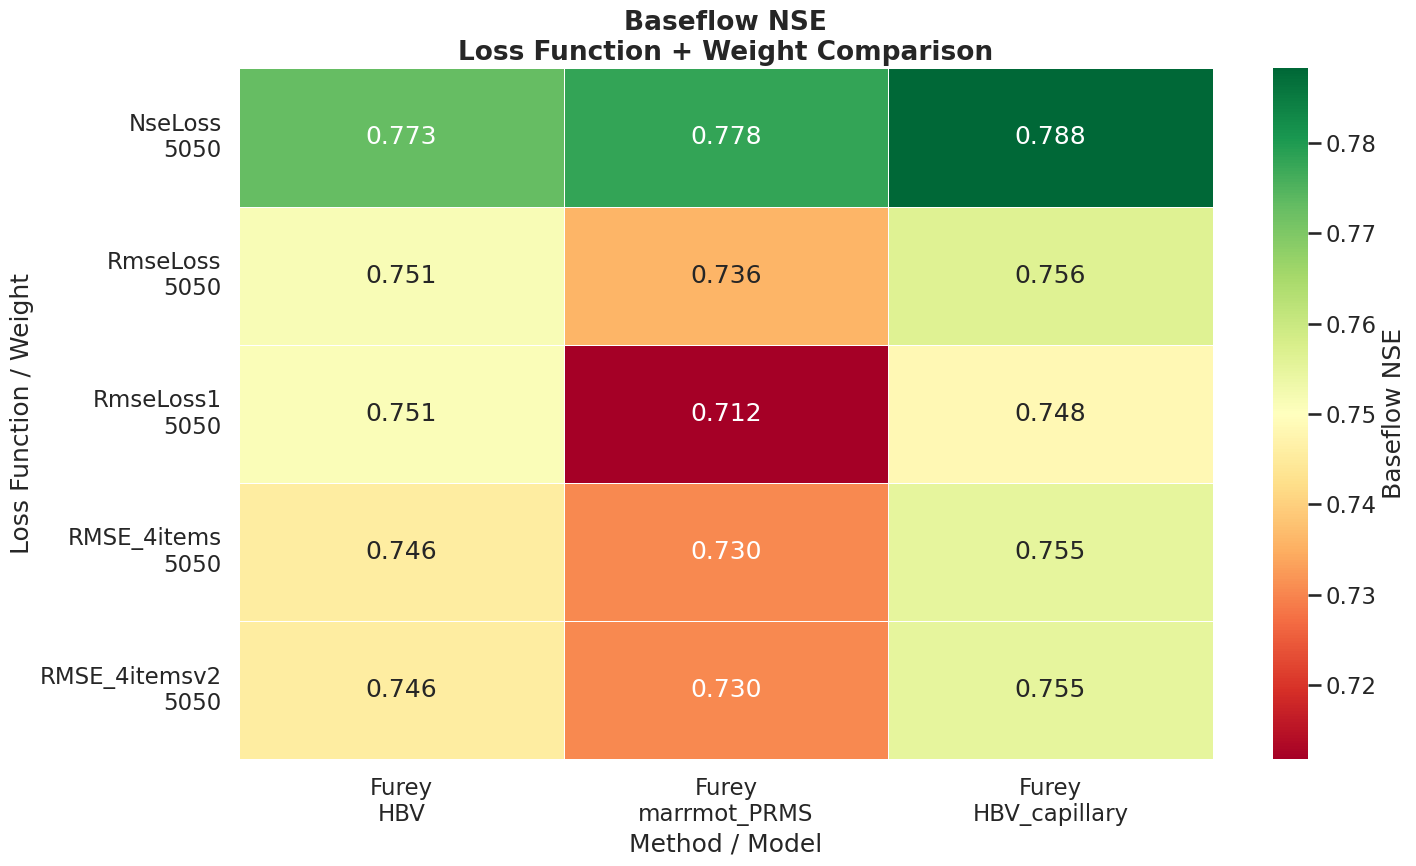

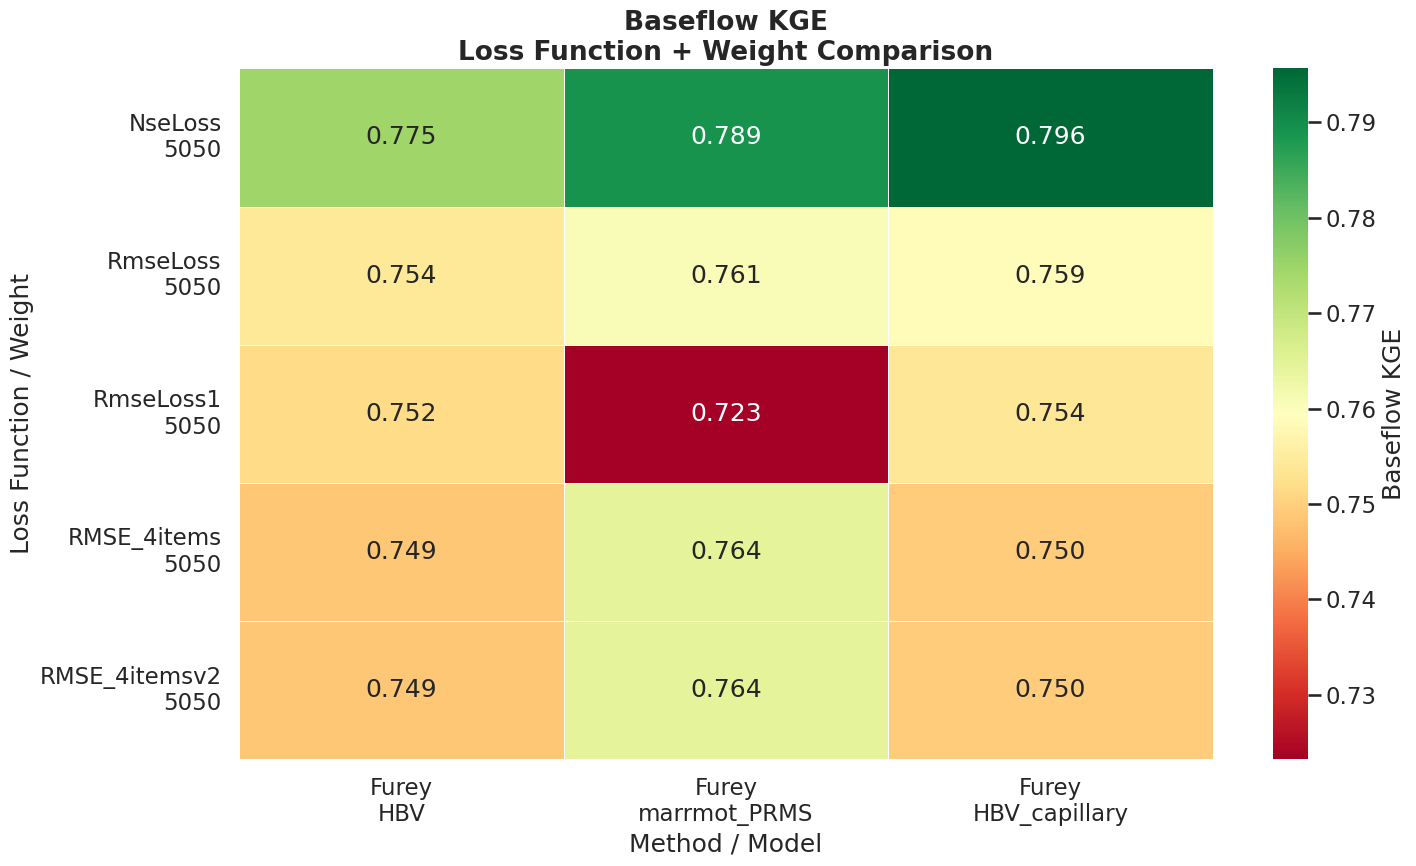

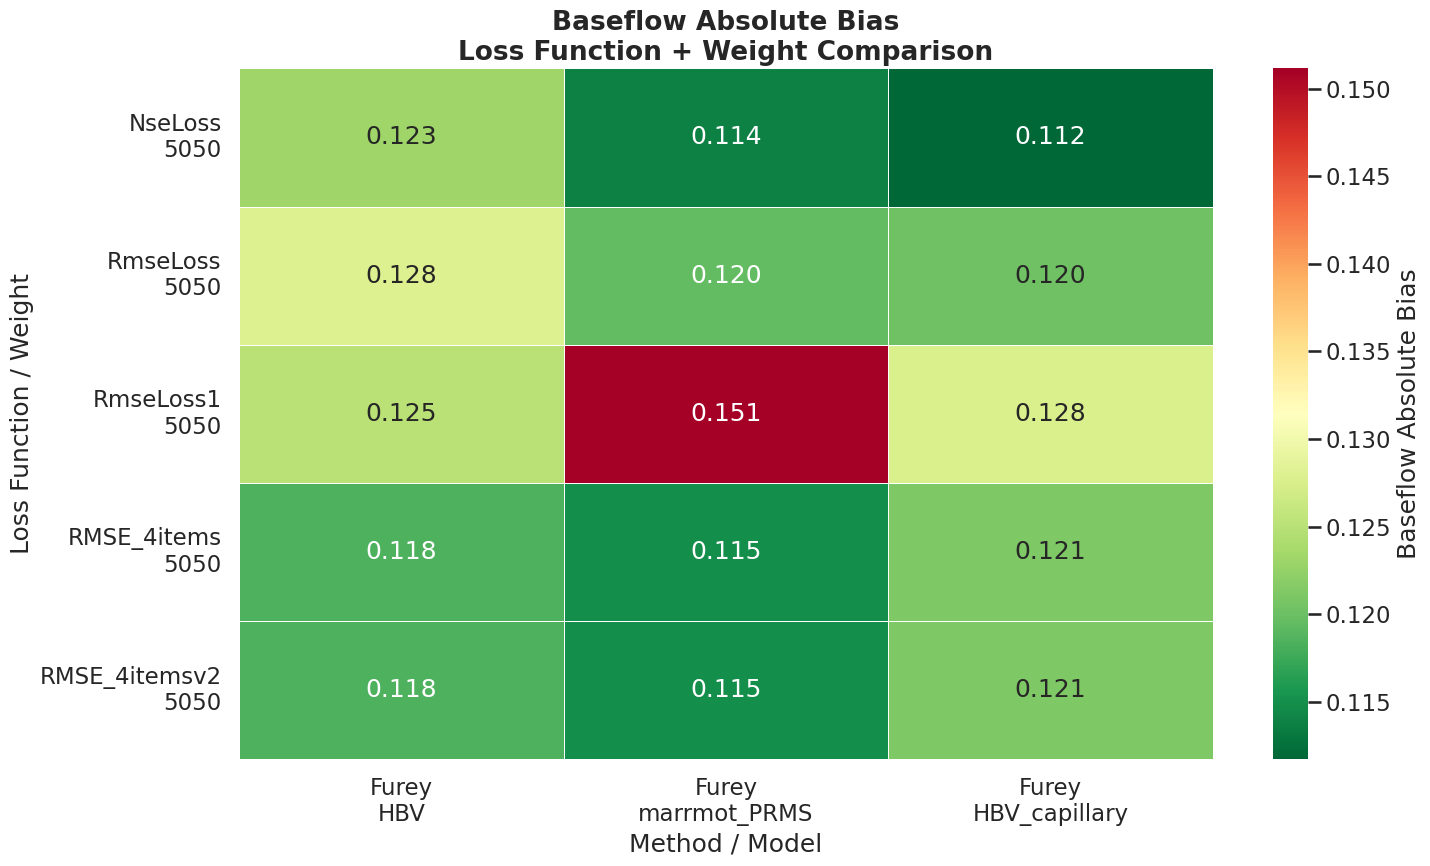



ANALYSIS COMPLETE

Objects available in memory:

1. best_weight_df
   Best weight for each Method × Model × Loss × Metric

2. best_loss_df
   Best loss for each Method × Model × Weight × Metric

3. best_weight_counts_df
   Frequency with which each weight is the best

4. best_loss_counts_df
   Frequency with which each loss is the best

No files were saved.


In [11]:
# ============================================================
# COMPLETE ANALYSIS
#
# PART 1:
# Fix Method + Model + Loss
# Vary Weight
#
# PART 2:
# Fix Method + Model + Weight
# Vary Loss
#
# PART 3:
# Best Weight for every Method × Model × Loss × Metric
#
# PART 4:
# Best Loss for every Method × Model × Weight × Metric
#
# PART 5:
# Count how often each Weight is best
#
# PART 6:
# Count how often each Loss is best
#
# PART 7:
# Heatmaps for all metrics
#
# NO FILES ARE SAVED
# ============================================================


# ============================================================
# IMPORTS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.lines import Line2D


# ============================================================
# SETTINGS
# ============================================================

sns.set_theme(
    style="whitegrid",
    context="talk"
)


# ============================================================
# METHODS
# ============================================================

methods_order = [
    'Furey',
    # 'Eckhardt'
]


# ============================================================
# MODELS
# ============================================================

models_order = [
    'HBV',
    'marrmot_PRMS',
    'HBV_capillary'
]


# ============================================================
# LOSS FUNCTIONS
# ============================================================

losses_order = [
    'NseLoss',
    'RmseLoss',
    'RmseLoss1',

     'RMSE_4items',
    
    'RMSE_4itemsv2'
]


# ============================================================
# WEIGHTS
# ============================================================

weights_order = [
    # '2575',
    '5050',
    # '7525'
]


# ============================================================
# PREPARE DATAFRAME
# ============================================================

df = df.copy()


# ------------------------------------------------------------
# Convert Weight to string
# ------------------------------------------------------------

df['Weights'] = (
    df['Weights']
    .astype(str)
    .str.strip()
)


# ------------------------------------------------------------
# Create simplified loss-function name
#
# Example:
# NseLoss_flow_baseflow
#              ↓
# NseLoss
# ------------------------------------------------------------

df['Loss_Short'] = (
    df['Loss_Function']
    .astype(str)
    .str.strip()
    .str.replace(
        '_flow_baseflow',
        '',
        regex=False
    )
)


# ============================================================
# CHECK DATA
# ============================================================

print("\n")
print("=" * 80)
print("DATA CHECK")
print("=" * 80)

print("\nDataframe columns:")
print(df.columns.tolist())

print("\nMethods:")
print(df['Method'].unique())

print("\nModels:")
print(df['Model'].unique())

print("\nLoss functions:")
print(df['Loss_Short'].unique())

print("\nWeights:")
print(df['Weights'].unique())

print("\nNumber of rows:")
print(len(df))


# ============================================================
# METRICS
#
# metric name
# display name
# optimization direction
# ============================================================

metrics = [

    (
        'NSE_Flow',
        'Flow NSE',
        'higher'
    ),

    (
        'KGE_Flow',
        'Flow KGE',
        'higher'
    ),

    (
        'Abs_Bias_Flow',
        'Flow Absolute Bias',
        'lower'
    ),

    (
        'NSE_Baseflow',
        'Baseflow NSE',
        'higher'
    ),

    (
        'KGE_Baseflow',
        'Baseflow KGE',
        'higher'
    ),

    (
        'Abs_Bias_Baseflow',
        'Baseflow Absolute Bias',
        'lower'
    )
]


# ============================================================
# COLORS
# ============================================================

weight_colors = {

    # '2575': '#1f77b4',

    '5050': '#ff7f0e',

    # '7525': '#2ca02c'
}


loss_colors = {

    'NseLoss': '#1f77b4',

    'RmseLoss': '#ff7f0e',

    'RmseLoss1': '#2ca02c',

    'RMSE_4items': 'red',

    'RMSE_4itemsv2': 'black',
}


# ============================================================
# FUNCTION 1
#
# FIX:
#   Method
#   Model
#   Loss
#
# VARY:
#   Weight
# ============================================================

def plot_weight_effect(
    df,
    method,
    model,
    loss
):

    # --------------------------------------------------------
    # Select data
    # --------------------------------------------------------

    data = df[
        (df['Method'] == method) &
        (df['Model'] == model) &
        (df['Loss_Short'] == loss)
    ].copy()


    # --------------------------------------------------------
    # Check data
    # --------------------------------------------------------

    if data.empty:

        print(
            f"No data for "
            f"{method} | {model} | {loss}"
        )

        return


    # --------------------------------------------------------
    # Sort weights
    # --------------------------------------------------------

    data['Weights'] = pd.Categorical(
        data['Weights'],
        categories=weights_order,
        ordered=True
    )

    data = data.sort_values(
        'Weights'
    )


    # --------------------------------------------------------
    # Create figure
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(20, 12)
    )

    axes = axes.flatten()


    # --------------------------------------------------------
    # Loop through metrics
    # --------------------------------------------------------

    for ax, (
        metric,
        title,
        direction
    ) in zip(
        axes,
        metrics
    ):

        # ----------------------------------------------------
        # Plot values
        # ----------------------------------------------------

        for weight in weights_order:

            subset = data[
                data['Weights'] == weight
            ]

            if subset.empty:
                continue

            value = subset[metric].iloc[0]

            if pd.isna(value):
                continue

            x = weights_order.index(weight)

            ax.scatter(
                x,
                value,
                s=180,
                color=weight_colors[weight],
                edgecolor='black',
                linewidth=1.2,
                zorder=5
            )

            ax.annotate(
                f'{value:.3f}',
                (x, value),
                xytext=(0, 10),
                textcoords='offset points',
                ha='center',
                fontsize=10
            )


        # ----------------------------------------------------
        # Determine best weight
        # ----------------------------------------------------

        valid_data = data[
            data[metric].notna()
        ]

        if not valid_data.empty:

            if direction == 'higher':

                best_idx = valid_data[
                    metric
                ].idxmax()

            else:

                best_idx = valid_data[
                    metric
                ].idxmin()


            best_weight = str(
                valid_data.loc[
                    best_idx,
                    'Weights'
                ]
            )

            best_value = valid_data.loc[
                best_idx,
                metric
            ]

            best_x = weights_order.index(
                best_weight
            )


            # ------------------------------------------------
            # Highlight best
            # ------------------------------------------------

            ax.scatter(
                best_x,
                best_value,
                s=450,
                facecolors='none',
                edgecolors='black',
                linewidth=2.5,
                marker='o',
                zorder=10
            )


        # ----------------------------------------------------
        # Reference line
        # ----------------------------------------------------

        # if direction == 'higher':

        #     ax.axhline(
        #         1,
        #         color='black',
        #         linestyle='--',
        #         linewidth=1.3,
        #         alpha=0.6
        #     )

        # else:

        #     ax.axhline(
        #         0,
        #         color='black',
        #         linestyle='--',
        #         linewidth=1.3,
        #         alpha=0.6
        #     )


        # ----------------------------------------------------
        # Formatting
        # ----------------------------------------------------

        ax.set_xticks(
            range(len(weights_order))
        )

        ax.set_xticklabels(
            weights_order, rotation=90
        )

        ax.set_xlabel(
            'Weight'
        )

        ax.set_ylabel(
            title
        )

        ax.set_title(
            title,
            fontsize=15,
            fontweight='bold'
        )

        ax.grid(
            axis='y',
            linestyle='--',
            alpha=0.35
        )

        ax.grid(
            axis='x',
            visible=False
        )


    # ========================================================
    # FIGURE TITLE
    # ========================================================

    fig.suptitle(
        f'{method} | {model} | {loss}\n'
        f'Effect of Weight',
        fontsize=21,
        fontweight='bold',
        y=1.02
    )


    # ========================================================
    # LEGEND
    # ========================================================

    legend_elements = [

        # Line2D(
        #     [0],
        #     [0],
        #     marker='o',
        #     color='w',
        #     label='Weight = 2575',
        #     markerfacecolor=weight_colors['2575'],
        #     markeredgecolor='black',
        #     markersize=11
        # ),

        Line2D(
            [0],
            [0],
            marker='o',
            color='w',
            label='Weight = 5050',
            markerfacecolor=weight_colors['5050'],
            markeredgecolor='black',
            markersize=11
        ),

        # Line2D(
        #     [0],
        #     [0],
        #     marker='o',
        #     color='w',
        #     label='Weight = 7525',
        #     markerfacecolor=weight_colors['7525'],
        #     markeredgecolor='black',
        #     markersize=11
        # ),

        Line2D(
            [0],
            [0],
            marker='o',
            color='black',
            markerfacecolor='none',
            label='Best',
            markersize=13,
            linewidth=2
        )
    ]


    fig.legend(
        handles=legend_elements,
        loc='center left',
        bbox_to_anchor=(1.0, 0.5),
        title='Weight'
    )


    plt.tight_layout(
        rect=[0, 0, 0.92, 1]
    )

    plt.show()

    plt.close(fig)


# ============================================================
# PART 1
#
# EFFECT OF WEIGHT
#
# 2 Methods × 3 Models × 3 Losses = 18 figures
# ============================================================

print("\n")
print("=" * 80)
print("PART 1: EFFECT OF WEIGHT")
print("=" * 80)


for method in methods_order:

    for model in models_order:

        for loss in losses_order:

            print(
                f"Plotting: "
                f"{method} | {model} | {loss}"
            )

            plot_weight_effect(
                df=df,
                method=method,
                model=model,
                loss=loss
            )


# ============================================================
# FUNCTION 2
#
# FIX:
#   Method
#   Model
#   Weight
#
# VARY:
#   Loss
# ============================================================

def plot_loss_effect(
    df,
    method,
    model,
    weight
):

    # --------------------------------------------------------
    # Select data
    # --------------------------------------------------------

    data = df[
        (df['Method'] == method) &
        (df['Model'] == model) &
        (df['Weights'] == str(weight))
    ].copy()


    # --------------------------------------------------------
    # Check data
    # --------------------------------------------------------

    if data.empty:

        print(
            f"No data for "
            f"{method} | {model} | {weight}"
        )

        return


    # --------------------------------------------------------
    # Sort loss functions
    # --------------------------------------------------------

    data['Loss_Short'] = pd.Categorical(
        data['Loss_Short'],
        categories=losses_order,
        ordered=True
    )

    data = data.sort_values(
        'Loss_Short'
    )


    # --------------------------------------------------------
    # Create figure
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(20, 12)
    )

    axes = axes.flatten()


    # --------------------------------------------------------
    # Loop through metrics
    # --------------------------------------------------------

    for ax, (
        metric,
        title,
        direction
    ) in zip(
        axes,
        metrics
    ):

        # ----------------------------------------------------
        # Plot each loss
        # ----------------------------------------------------

        for loss in losses_order:

            subset = data[
                data['Loss_Short'] == loss
            ]

            if subset.empty:
                continue

            value = subset[metric].iloc[0]

            if pd.isna(value):
                continue

            x = losses_order.index(loss)

            ax.scatter(
                x,
                value,
                s=180,
                color=loss_colors[loss],
                edgecolor='black',
                linewidth=1.2,
                zorder=5
            )

            ax.annotate(
                f'{value:.3f}',
                (x, value),
                xytext=(0, 10),
                textcoords='offset points',
                ha='center',
                fontsize=10
            )


        # ----------------------------------------------------
        # Determine best loss
        # ----------------------------------------------------

        valid_data = data[
            data[metric].notna()
        ]

        if not valid_data.empty:

            if direction == 'higher':

                best_idx = valid_data[
                    metric
                ].idxmax()

            else:

                best_idx = valid_data[
                    metric
                ].idxmin()


            best_loss = str(
                valid_data.loc[
                    best_idx,
                    'Loss_Short'
                ]
            )

            best_value = valid_data.loc[
                best_idx,
                metric
            ]

            best_x = losses_order.index(
                best_loss
            )


            # ------------------------------------------------
            # Highlight best
            # ------------------------------------------------

            ax.scatter(
                best_x,
                best_value,
                s=450,
                facecolors='none',
                edgecolors='black',
                linewidth=2.5,
                marker='o',
                zorder=10
            )


        # ----------------------------------------------------
        # Reference line
        # ----------------------------------------------------

        # if direction == 'higher':

        #     ax.axhline(
        #         1,
        #         color='black',
        #         linestyle='--',
        #         linewidth=1.3,
        #         alpha=0.6
        #     )

        # else:

        #     ax.axhline(
        #         0,
        #         color='black',
        #         linestyle='--',
        #         linewidth=1.3,
        #         alpha=0.6
        #     )


        # ----------------------------------------------------
        # Formatting
        # ----------------------------------------------------

        ax.set_xticks(
            range(len(losses_order))
        )

        ax.set_xticklabels(
            losses_order, rotation=90
        )

        ax.set_xlabel(
            'Loss function'
        )

        ax.set_ylabel(
            title
        )

        ax.set_title(
            title,
            fontsize=15,
            fontweight='bold'
        )

        ax.grid(
            axis='y',
            linestyle='--',
            alpha=0.35
        )

        ax.grid(
            axis='x',
            visible=False
        )


    # ========================================================
    # FIGURE TITLE
    # ========================================================

    fig.suptitle(
        f'{method} | {model} | Weight = {weight}\n'
        f'Effect of Loss Function',
        fontsize=21,
        fontweight='bold',
        y=1.02
    )


    # ========================================================
    # LEGEND
    # ========================================================

    legend_elements = [

        Line2D(
            [0],
            [0],
            marker='o',
            color='w',
            label='NseLoss',
            markerfacecolor=loss_colors['NseLoss'],
            markeredgecolor='black',
            markersize=11
        ),

        Line2D(
            [0],
            [0],
            marker='o',
            color='w',
            label='RmseLoss',
            markerfacecolor=loss_colors['RmseLoss'],
            markeredgecolor='black',
            markersize=11
        ),

        Line2D(
            [0],
            [0],
            marker='o',
            color='w',
            label='RmseLoss1',
            markerfacecolor=loss_colors['RmseLoss1'],
            markeredgecolor='black',
            markersize=11
        ),

        Line2D(
            [0],
            [0],
            marker='o',
            color='black',
            markerfacecolor='none',
            label='Best',
            markersize=13,
            linewidth=2
        )
    ]


    fig.legend(
        handles=legend_elements,
        loc='center left',
        bbox_to_anchor=(1.0, 0.5),
        title='Loss function'
    )


    plt.tight_layout(
        rect=[0, 0, 0.92, 1]
    )

    plt.show()

    plt.close(fig)


# ============================================================
# PART 2
#
# EFFECT OF LOSS FUNCTION
#
# 2 Methods × 3 Models × 3 Weights = 18 figures
# ============================================================

print("\n")
print("=" * 80)
print("PART 2: EFFECT OF LOSS FUNCTION")
print("=" * 80)


for method in methods_order:

    for model in models_order:

        for weight in weights_order:

            print(
                f"Plotting: "
                f"{method} | {model} | Weight = {weight}"
            )

            plot_loss_effect(
                df=df,
                method=method,
                model=model,
                weight=weight
            )


# ============================================================
# PART 3
#
# BEST WEIGHT
#
# For every:
#   Method × Model × Loss × Metric
# ============================================================

print("\n")
print("=" * 80)
print("PART 3: BEST WEIGHT")
print("=" * 80)


best_weight_results = []


for method in methods_order:

    for model in models_order:

        for loss in losses_order:

            data = df[
                (df['Method'] == method) &
                (df['Model'] == model) &
                (df['Loss_Short'] == loss)
            ].copy()


            if data.empty:
                continue


            result = {

                'Method': method,

                'Model': model,

                'Loss': loss
            }


            for metric, title, direction in metrics:

                valid = data[
                    data[metric].notna()
                ]


                if valid.empty:

                    result[
                        f'Best_{metric}'
                    ] = np.nan

                    result[
                        f'Best_{metric}_Value'
                    ] = np.nan

                    continue


                if direction == 'higher':

                    idx = valid[
                        metric
                    ].idxmax()

                else:

                    idx = valid[
                        metric
                    ].idxmin()


                result[
                    f'Best_{metric}'
                ] = str(
                    valid.loc[
                        idx,
                        'Weights'
                    ]
                )

                result[
                    f'Best_{metric}_Value'
                ] = valid.loc[
                    idx,
                    metric
                ]


            best_weight_results.append(
                result
            )


best_weight_df = pd.DataFrame(
    best_weight_results
)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

pd.set_option(
    'display.max_columns',
    None
)

print(
    best_weight_df.to_string(
        index=False
    )
)


# ============================================================
# PART 4
#
# BEST LOSS
#
# For every:
#   Method × Model × Weight × Metric
# ============================================================

print("\n")
print("=" * 80)
print("PART 4: BEST LOSS")
print("=" * 80)


best_loss_results = []


for method in methods_order:

    for model in models_order:

        for weight in weights_order:

            data = df[
                (df['Method'] == method) &
                (df['Model'] == model) &
                (df['Weights'] == str(weight))
            ].copy()


            if data.empty:
                continue


            result = {

                'Method': method,

                'Model': model,

                'Weight': weight
            }


            for metric, title, direction in metrics:

                valid = data[
                    data[metric].notna()
                ]


                if valid.empty:

                    result[
                        f'Best_{metric}'
                    ] = np.nan

                    result[
                        f'Best_{metric}_Value'
                    ] = np.nan

                    continue


                if direction == 'higher':

                    idx = valid[
                        metric
                    ].idxmax()

                else:

                    idx = valid[
                        metric
                    ].idxmin()


                result[
                    f'Best_{metric}'
                ] = str(
                    valid.loc[
                        idx,
                        'Loss_Short'
                    ]
                )

                result[
                    f'Best_{metric}_Value'
                ] = valid.loc[
                    idx,
                    metric
                ]


            best_loss_results.append(
                result
            )


best_loss_df = pd.DataFrame(
    best_loss_results
)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print(
    best_loss_df.to_string(
        index=False
    )
)


# ============================================================
# PART 5
#
# HOW OFTEN IS EACH WEIGHT THE BEST?
# ============================================================

print("\n")
print("=" * 80)
print("PART 5: HOW OFTEN IS EACH WEIGHT THE BEST?")
print("=" * 80)


best_weight_counts = {}


for metric, title, direction in metrics:

    col = f'Best_{metric}'


    if col not in best_weight_df.columns:
        continue


    counts = (
        best_weight_df[col]
        .dropna()
        .value_counts()
        .reindex(
            weights_order,
            fill_value=0
        )
    )


    best_weight_counts[title] = counts


best_weight_counts_df = pd.DataFrame(
    best_weight_counts
)


print(
    best_weight_counts_df
)


# ============================================================
# PART 6
#
# HOW OFTEN IS EACH LOSS THE BEST?
# ============================================================

print("\n")
print("=" * 80)
print("PART 6: HOW OFTEN IS EACH LOSS FUNCTION THE BEST?")
print("=" * 80)


best_loss_counts = {}


for metric, title, direction in metrics:

    col = f'Best_{metric}'


    if col not in best_loss_df.columns:
        continue


    counts = (
        best_loss_df[col]
        .dropna()
        .value_counts()
        .reindex(
            losses_order,
            fill_value=0
        )
    )


    best_loss_counts[title] = counts


best_loss_counts_df = pd.DataFrame(
    best_loss_counts
)


print(
    best_loss_counts_df
)


# ============================================================
# PART 7
#
# HEATMAPS
#
# Loss + Weight vs Method + Model
# ============================================================

print("\n")
print("=" * 80)
print("PART 7: HEATMAPS")
print("=" * 80)


# ============================================================
# LOSS + WEIGHT LABEL
# ============================================================

df['Loss_Weight'] = (
    df['Loss_Short']
    + '\n'
    + df['Weights']
)


loss_weight_order = [

    # 'NseLoss\n2575',
    'NseLoss\n5050',
    # 'NseLoss\n7525',

    # 'RmseLoss\n2575',
    'RmseLoss\n5050',
    # 'RmseLoss\n7525',

    # 'RmseLoss1\n2575',
    'RmseLoss1\n5050',
    # 'RmseLoss1\n7525'

    'RMSE_4items\n5050',
    'RMSE_4itemsv2\n5050',
]


# ============================================================
# METHOD + MODEL LABEL
# ============================================================

df['Method_Model'] = (
    df['Method']
    + '\n'
    + df['Model']
)


method_model_order = [

    'Furey\nHBV',
    'Furey\nmarrmot_PRMS',
    'Furey\nHBV_capillary',

    # 'Eckhardt\nHBV',
    # 'Eckhardt\nmarrmot_PRMS',
    # 'Eckhardt\nHBV_capillary'
]


# ============================================================
# HEATMAP FOR EVERY METRIC
# ============================================================

for metric, title, direction in metrics:

    # --------------------------------------------------------
    # Pivot
    # --------------------------------------------------------

    pivot = df.pivot_table(
        index='Loss_Weight',
        columns='Method_Model',
        values=metric,
        aggfunc='first'
    )


    # --------------------------------------------------------
    # Force desired ordering
    # --------------------------------------------------------

    pivot = pivot.reindex(
        index=loss_weight_order,
        columns=method_model_order
    )


    # --------------------------------------------------------
    # Figure
    # --------------------------------------------------------

    fig = plt.figure(
        figsize=(15, 9)
    )


    # --------------------------------------------------------
    # Colormap direction
    # --------------------------------------------------------

    if direction == 'higher':

        cmap = 'RdYlGn'

    else:

        cmap = 'RdYlGn_r'


    # --------------------------------------------------------
    # Heatmap
    # --------------------------------------------------------

    sns.heatmap(
        pivot,
        annot=True,
        fmt='.3f',
        cmap=cmap,
        linewidths=0.7,
        linecolor='white',
        cbar_kws={
            'label': title
        }
    )


    # --------------------------------------------------------
    # Formatting
    # --------------------------------------------------------

    plt.title(
        f'{title}\n'
        f'Loss Function + Weight Comparison',
        fontsize=19,
        fontweight='bold'
    )

    plt.xlabel(
        'Method / Model'
    )

    plt.ylabel(
        'Loss Function / Weight'
    )

    plt.tight_layout()

    plt.show()

    plt.close(fig)


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 80)
print("ANALYSIS COMPLETE")
print("=" * 80)

print("\nObjects available in memory:")

print("\n1. best_weight_df")
print(
    "   Best weight for each "
    "Method × Model × Loss × Metric"
)

print("\n2. best_loss_df")
print(
    "   Best loss for each "
    "Method × Model × Weight × Metric"
)

print("\n3. best_weight_counts_df")
print(
    "   Frequency with which each weight "
    "is the best"
)

print("\n4. best_loss_counts_df")
print(
    "   Frequency with which each loss "
    "is the best"
)

print("\nNo files were saved.")

In [51]:
import os
os.getcwd()

'/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config'